# Enterprise Data Collection / Dataset Loading

In [1]:
# Step 1: Enterprise Data Collection / Dataset Loading

import pandas as pd
import os

# Dataset path
dataset_path = r"F:\New_File_Dataset\enterprise_management_dataset.csv"

# Check whether the file exists
if os.path.exists(dataset_path):
    print("Dataset file found successfully.")
    
    # Load dataset
    df = pd.read_csv(dataset_path)
    
    # Display basic dataset information
    print("\nDataset loaded successfully!")
    print("Dataset Shape:", df.shape)
    
    print("\nDataset Columns:")
    print(df.columns.tolist())
    
    print("\nFirst 5 Records:")
    print(df.head())
    
    print("\nDataset Information:")
    print(df.info())
    
    print("\nMissing Values Count:")
    print(df.isnull().sum())
    
else:
    print("Dataset file not found. Please check the file path.")

Dataset file found successfully.

Dataset loaded successfully!
Dataset Shape: (1000, 11)

Dataset Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Text_Report', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Risk_Level', 'Predicted_Sales', 'Inventory_Optimization_Score', 'Decision_Strategy']

First 5 Records:
   Operational_Metric  Financial_Metric  Market_Signal  \
0          193.524658     100715.135131       0.261706   
1          475.850010     275531.464215       0.246979   
2          368.677031     437743.459579       0.906255   
3          303.342657     368790.194341       0.249546   
4           86.449134     405214.962452       0.271950   

                                         Text_Report  Token_Count  \
0  Customer satisfaction improved based on servic...           77   
1  Sales increased due to seasonal demand and imp...           67   
2  New marketing strategy significantly boosted w...           48   
3  Positive workforce pr

# Data Preprocessing

In [2]:
# Step 2: Data Preprocessing

import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ==============================
# 1. Load Dataset
# ==============================

dataset_path = r"F:\New_File_Dataset\enterprise_management_dataset.csv"
df = pd.read_csv(dataset_path)

print("Original Dataset Shape:", df.shape)
print("\nOriginal Columns:")
print(df.columns.tolist())

# ==============================
# 2. Remove Duplicate Records
# ==============================

df = df.drop_duplicates()
print("\nDataset Shape After Removing Duplicates:", df.shape)

# ==============================
# 3. Check Missing Values
# ==============================

print("\nMissing Values Before Preprocessing:")
print(df.isnull().sum())

# ==============================
# 4. Identify Column Types
# ==============================

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
text_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumerical Columns:")
print(numeric_cols)

print("\nText / Categorical Columns:")
print(text_cols)

# ==============================
# 5. Handle Missing Values
# ==============================

# Fill numerical missing values with median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill text/categorical missing values with mode
for col in text_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Handling:")
print(df.isnull().sum())

# ==============================
# 6. Text Cleaning Function
# ==============================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# ==============================
# 7. Clean Textual Report Columns
# ==============================

# Change this column name if your dataset uses another text column name
possible_text_columns = [
    "Textual_Report",
    "textual_report",
    "Enterprise_Report",
    "enterprise_report",
    "Report",
    "report",
    "Management_Report",
    "management_report"
]

actual_text_columns = [col for col in possible_text_columns if col in df.columns]

if len(actual_text_columns) > 0:
    for col in actual_text_columns:
        df[col] = df[col].apply(clean_text)
        df[col + "_token_count"] = df[col].apply(lambda x: len(str(x).split()))
    
    print("\nText columns cleaned successfully:")
    print(actual_text_columns)
else:
    print("\nNo specific textual report column found. Skipping text cleaning.")

# ==============================
# 8. Encode Target / Categorical Columns
# ==============================

label_encoders = {}

for col in text_cols:
    # Skip textual report columns from label encoding
    if col not in actual_text_columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

print("\nCategorical columns encoded successfully.")

# ==============================
# 9. Z-Score Normalization
# ==============================

# Re-detect numerical columns after encoding
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Do not normalize target label if present
target_columns = [
    "Risk_Level",
    "risk_level",
    "Decision_Label",
    "decision_label",
    "Target",
    "target"
]

exclude_cols = [col for col in target_columns if col in df.columns]

scale_cols = [col for col in numeric_cols if col not in exclude_cols]

scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

print("\nZ-score normalization completed.")
print("Normalized Columns:")
print(scale_cols)

# ==============================
# 10. Save Preprocessed Dataset
# ==============================

output_path = r"F:\New_File_Dataset\enterprise_management_preprocessed.csv"
df.to_csv(output_path, index=False)

print("\nPreprocessed dataset saved successfully at:")
print(output_path)

print("\nFinal Dataset Shape:", df.shape)
print("\nFirst 5 Rows After Preprocessing:")
print(df.head())

Original Dataset Shape: (1000, 11)

Original Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Text_Report', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Risk_Level', 'Predicted_Sales', 'Inventory_Optimization_Score', 'Decision_Strategy']

Dataset Shape After Removing Duplicates: (1000, 11)

Missing Values Before Preprocessing:
Operational_Metric              0
Financial_Metric                0
Market_Signal                   0
Text_Report                     0
Token_Count                     0
Normalized_Operational          0
Normalized_Financial            0
Risk_Level                      0
Predicted_Sales                 0
Inventory_Optimization_Score    0
Decision_Strategy               0
dtype: int64

Numerical Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Predicted_Sales', 'Inventory_Optimization_Score']

Text / Categorical Columns:
['Text_Report', '

# Feature Extraction

In [3]:
# ==========================================================
# Step 3: Feature Extraction
# Enterprise Management Decision Dataset
# ==========================================================

import pandas as pd
import numpy as np
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from scipy.sparse import hstack, csr_matrix
import joblib

# ==============================
# 1. Load Preprocessed Dataset
# ==============================

dataset_path = r"F:\New_File_Dataset\enterprise_management_preprocessed.csv"

df = pd.read_csv(dataset_path)

print("Preprocessed Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())

# ==============================
# 2. Detect Target Columns
# ==============================

possible_class_targets = [
    "Risk_Level",
    "risk_level",
    "Decision_Label",
    "decision_label",
    "Target",
    "target",
    "Risk"
]

possible_regression_targets = [
    "Predicted_Sales",
    "predicted_sales",
    "Inventory_Optimization_Score",
    "inventory_optimization_score",
    "Sales",
    "sales"
]

classification_target = None

for col in possible_class_targets:
    if col in df.columns:
        classification_target = col
        break

regression_targets = [col for col in possible_regression_targets if col in df.columns]

print("\nDetected Classification Target:", classification_target)
print("Detected Regression Targets:", regression_targets)

# ==============================
# 3. Detect Text Columns
# ==============================

possible_text_columns = [
    "Textual_Report",
    "textual_report",
    "Enterprise_Report",
    "enterprise_report",
    "Report",
    "report",
    "Management_Report",
    "management_report",
    "Text",
    "text"
]

text_columns = [col for col in possible_text_columns if col in df.columns]

print("\nDetected Text Columns:", text_columns)

# ==============================
# 4. Detect Numerical Feature Columns
# ==============================

exclude_columns = []

if classification_target is not None:
    exclude_columns.append(classification_target)

exclude_columns.extend(regression_targets)
exclude_columns.extend(text_columns)

numeric_feature_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_feature_columns = [col for col in numeric_feature_columns if col not in exclude_columns]

print("\nDetected Numerical Feature Columns:")
print(numeric_feature_columns)

# ==============================
# 5. Extract Numerical Features
# ==============================

X_numeric = df[numeric_feature_columns].values

print("\nNumerical Feature Matrix Shape:", X_numeric.shape)

# ==============================
# 6. Extract Textual Features using TF-IDF
# ==============================

if len(text_columns) > 0:
    # Combine all text columns into one text field
    df["combined_text"] = df[text_columns].astype(str).agg(" ".join, axis=1)

    tfidf_vectorizer = TfidfVectorizer(
        max_features=500,
        ngram_range=(1, 2),
        stop_words="english"
    )

    X_text = tfidf_vectorizer.fit_transform(df["combined_text"])

    print("\nTF-IDF Text Feature Matrix Shape:", X_text.shape)

else:
    print("\nNo text column found. Creating empty text feature matrix.")
    X_text = csr_matrix((df.shape[0], 0))
    tfidf_vectorizer = None

# ==============================
# 7. Combine Numerical + Text Features
# ==============================

X_numeric_sparse = csr_matrix(X_numeric)

X_features = hstack([X_numeric_sparse, X_text])

print("\nFinal Extracted Feature Matrix Shape:", X_features.shape)

# ==============================
# 8. Extract Classification Target
# ==============================

if classification_target is not None:
    y_class = df[classification_target]

    # Encode if target is still object/string
    if y_class.dtype == "object":
        label_encoder = LabelEncoder()
        y_class = label_encoder.fit_transform(y_class)
    else:
        label_encoder = None
        y_class = y_class.values

    print("\nClassification Target Extracted Successfully!")
    print("Classification Target Shape:", y_class.shape)
    print("Unique Classes:", np.unique(y_class))

else:
    y_class = None
    label_encoder = None
    print("\nNo classification target found.")

# ==============================
# 9. Extract Regression Targets
# ==============================

if len(regression_targets) > 0:
    y_reg = df[regression_targets].values

    print("\nRegression Targets Extracted Successfully!")
    print("Regression Target Shape:", y_reg.shape)
    print("Regression Target Columns:", regression_targets)

else:
    y_reg = None
    print("\nNo regression target found.")

# ==============================
# 10. Save Extracted Features
# ==============================

output_folder = r"F:\New_File_Dataset\Step3_Feature_Extraction"
os.makedirs(output_folder, exist_ok=True)

joblib.dump(X_features, os.path.join(output_folder, "X_features.pkl"))
joblib.dump(y_class, os.path.join(output_folder, "y_class.pkl"))
joblib.dump(y_reg, os.path.join(output_folder, "y_reg.pkl"))
joblib.dump(tfidf_vectorizer, os.path.join(output_folder, "tfidf_vectorizer.pkl"))
joblib.dump(label_encoder, os.path.join(output_folder, "label_encoder.pkl"))

# Save feature column names
feature_info = {
    "numeric_feature_columns": numeric_feature_columns,
    "text_columns": text_columns,
    "classification_target": classification_target,
    "regression_targets": regression_targets
}

joblib.dump(feature_info, os.path.join(output_folder, "feature_info.pkl"))

print("\nStep 3 Feature Extraction Completed Successfully!")
print("Extracted files saved at:")
print(output_folder)

Preprocessed Dataset Loaded Successfully!
Dataset Shape: (1000, 11)

Dataset Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Text_Report', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Risk_Level', 'Predicted_Sales', 'Inventory_Optimization_Score', 'Decision_Strategy']

Detected Classification Target: Risk_Level
Detected Regression Targets: ['Predicted_Sales', 'Inventory_Optimization_Score']

Detected Text Columns: []

Detected Numerical Feature Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Text_Report', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Decision_Strategy']

Numerical Feature Matrix Shape: (1000, 8)

No text column found. Creating empty text feature matrix.

Final Extracted Feature Matrix Shape: (1000, 8)

Classification Target Extracted Successfully!
Classification Target Shape: (1000,)
Unique Classes: [0 1 2]

Regression Targets Extracted Successfully!
Regression Target Shape: (1000, 2)


# Multimodal Feature Fusion

In [4]:
# ==========================================================
# Step 4: Multimodal Feature Fusion
# Attention-Based Fusion for Enterprise Management Dataset
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from sklearn.preprocessing import MinMaxScaler

# ==============================
# 1. Load Step 3 Extracted Files
# ==============================

input_folder = r"F:\New_File_Dataset\Step3_Feature_Extraction"

X_features = joblib.load(os.path.join(input_folder, "X_features.pkl"))
y_class = joblib.load(os.path.join(input_folder, "y_class.pkl"))
y_reg = joblib.load(os.path.join(input_folder, "y_reg.pkl"))
feature_info = joblib.load(os.path.join(input_folder, "feature_info.pkl"))

print("Step 3 extracted features loaded successfully!")
print("Original Feature Matrix Shape:", X_features.shape)

numeric_feature_columns = feature_info["numeric_feature_columns"]
text_columns = feature_info["text_columns"]

print("\nNumerical Feature Columns:")
print(numeric_feature_columns)

print("\nText Columns:")
print(text_columns)

# ==============================
# 2. Convert Sparse Matrix to Dense
# ==============================

X_dense = X_features.toarray()

print("\nDense Feature Matrix Shape:", X_dense.shape)

# ==============================
# 3. Separate Numerical and Text Feature Parts
# ==============================

num_numeric_features = len(numeric_feature_columns)

X_numeric = X_dense[:, :num_numeric_features]
X_text = X_dense[:, num_numeric_features:]

print("\nNumerical Feature Matrix Shape:", X_numeric.shape)
print("Text Feature Matrix Shape:", X_text.shape)

# ==============================
# 4. Normalize Feature Blocks
# ==============================

numeric_scaler = MinMaxScaler()
text_scaler = MinMaxScaler()

X_numeric_scaled = numeric_scaler.fit_transform(X_numeric)

if X_text.shape[1] > 0:
    X_text_scaled = text_scaler.fit_transform(X_text)
else:
    X_text_scaled = X_text

print("\nFeature block normalization completed.")

# ==============================
# 5. Define Attention Weight Function
# ==============================

def calculate_attention_weights(feature_block):
    """
    Calculates attention weight for each feature block.
    Higher mean activation receives higher attention score.
    """
    if feature_block.shape[1] == 0:
        return 0.0
    
    score = np.mean(np.abs(feature_block))
    return score

# ==============================
# 6. Calculate Modality Attention Scores
# ==============================

numeric_score = calculate_attention_weights(X_numeric_scaled)
text_score = calculate_attention_weights(X_text_scaled)

attention_scores = np.array([numeric_score, text_score])

# Avoid division by zero
if attention_scores.sum() == 0:
    attention_weights = np.array([0.5, 0.5])
else:
    attention_weights = attention_scores / attention_scores.sum()

numeric_weight = attention_weights[0]
text_weight = attention_weights[1]

print("\nAttention Scores:")
print("Numerical Score:", round(numeric_score, 4))
print("Text Score:", round(text_score, 4))

print("\nAttention Weights:")
print("Numerical Weight:", round(numeric_weight, 4))
print("Text Weight:", round(text_weight, 4))

# ==============================
# 7. Apply Attention-Based Fusion
# ==============================

X_numeric_attention = X_numeric_scaled * numeric_weight
X_text_attention = X_text_scaled * text_weight

X_fused = np.hstack([X_numeric_attention, X_text_attention])

print("\nAttention-Based Multimodal Fusion Completed!")
print("Fused Feature Matrix Shape:", X_fused.shape)

# ==============================
# 8. Create Feature Names
# ==============================

numeric_names = numeric_feature_columns

text_feature_names = [
    "TFIDF_Feature_" + str(i + 1) for i in range(X_text.shape[1])
]

fused_feature_names = numeric_names + text_feature_names

# ==============================
# 9. Save Fused Features
# ==============================

output_folder = r"F:\New_File_Dataset\Step4_Multimodal_Fusion"
os.makedirs(output_folder, exist_ok=True)

joblib.dump(X_fused, os.path.join(output_folder, "X_fused_features.pkl"))
joblib.dump(y_class, os.path.join(output_folder, "y_class.pkl"))
joblib.dump(y_reg, os.path.join(output_folder, "y_reg.pkl"))
joblib.dump(numeric_scaler, os.path.join(output_folder, "numeric_scaler.pkl"))
joblib.dump(text_scaler, os.path.join(output_folder, "text_scaler.pkl"))

fusion_info = {
    "numeric_weight": numeric_weight,
    "text_weight": text_weight,
    "numeric_score": numeric_score,
    "text_score": text_score,
    "fused_feature_names": fused_feature_names,
    "num_numeric_features": num_numeric_features,
    "num_text_features": X_text.shape[1]
}

joblib.dump(fusion_info, os.path.join(output_folder, "fusion_info.pkl"))

# Also save as CSV for checking
fused_df = pd.DataFrame(X_fused, columns=fused_feature_names)
fused_df.to_csv(os.path.join(output_folder, "fused_features.csv"), index=False)

print("\nStep 4 Multimodal Feature Fusion Completed Successfully!")
print("Files saved at:")
print(output_folder)

Step 3 extracted features loaded successfully!
Original Feature Matrix Shape: (1000, 8)

Numerical Feature Columns:
['Operational_Metric', 'Financial_Metric', 'Market_Signal', 'Text_Report', 'Token_Count', 'Normalized_Operational', 'Normalized_Financial', 'Decision_Strategy']

Text Columns:
[]

Dense Feature Matrix Shape: (1000, 8)

Numerical Feature Matrix Shape: (1000, 8)
Text Feature Matrix Shape: (1000, 0)

Feature block normalization completed.

Attention Scores:
Numerical Score: 0.4995
Text Score: 0.0

Attention Weights:
Numerical Weight: 1.0
Text Weight: 0.0

Attention-Based Multimodal Fusion Completed!
Fused Feature Matrix Shape: (1000, 8)

Step 4 Multimodal Feature Fusion Completed Successfully!
Files saved at:
F:\New_File_Dataset\Step4_Multimodal_Fusion


# WPS-Based Hyperparameter Optimization

In [5]:
# ==========================================================
# Step 5: WPS-Based Hyperparameter Optimization
# Enterprise Management Decision Dataset
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd
import random
import time

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# ==============================
# 1. Load Step 4 Fused Features
# ==============================

input_folder = r"F:\New_File_Dataset\Step4_Multimodal_Fusion"

X_fused = joblib.load(os.path.join(input_folder, "X_fused_features.pkl"))
y_class = joblib.load(os.path.join(input_folder, "y_class.pkl"))
fusion_info = joblib.load(os.path.join(input_folder, "fusion_info.pkl"))

print("Step 4 fused features loaded successfully!")
print("Fused Feature Matrix Shape:", X_fused.shape)
print("Target Shape:", y_class.shape)

# ==============================
# 2. Train-Test Split
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X_fused,
    y_class,
    test_size=0.30,
    random_state=42,
    stratify=y_class
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# ==============================
# 3. Define Hyperparameter Search Space
# ==============================

search_space = {
    "hidden_units": [128, 256, 512],
    "learning_rate": [0.0001, 0.0005, 0.001],
    "dropout_rate": [0.2, 0.3, 0.4, 0.5],
    "batch_size": [16, 32, 64],
    "max_iter": [100, 150, 200]
}

# ==============================
# 4. Helper Function: Generate Random Wolf
# ==============================

def generate_random_wolf():
    """
    Each wolf represents one candidate hyperparameter combination.
    """
    wolf = {
        "hidden_units": random.choice(search_space["hidden_units"]),
        "learning_rate": random.choice(search_space["learning_rate"]),
        "dropout_rate": random.choice(search_space["dropout_rate"]),
        "batch_size": random.choice(search_space["batch_size"]),
        "max_iter": random.choice(search_space["max_iter"])
    }
    return wolf

# ==============================
# 5. Fitness Function
# ==============================

def evaluate_wolf(wolf, X_train, X_test, y_train, y_test):
    """
    Fitness is calculated using validation accuracy and F1-score.
    Higher fitness means better wolf position.
    """

    hidden_units = wolf["hidden_units"]
    learning_rate = wolf["learning_rate"]
    batch_size = wolf["batch_size"]
    max_iter = wolf["max_iter"]

    # MLPClassifier is used here as a practical MDNN classifier
    model = MLPClassifier(
        hidden_layer_sizes=(hidden_units, hidden_units // 2),
        activation="relu",
        solver="adam",
        learning_rate_init=learning_rate,
        batch_size=batch_size,
        max_iter=max_iter,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=10
    )

    start_time = time.time()

    try:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
        precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
        recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)

        # Combined fitness score
        fitness = (0.50 * acc) + (0.50 * f1)

    except Exception as e:
        print("Model failed for wolf:", wolf)
        print("Error:", e)

        acc = 0
        f1 = 0
        precision = 0
        recall = 0
        fitness = 0

    end_time = time.time()
    training_time = end_time - start_time

    result = {
        "wolf": wolf,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "fitness": fitness,
        "training_time_sec": training_time
    }

    return result

# ==============================
# 6. Initialize Wolf Population
# ==============================

population_size = 10
max_iterations = 5

wolf_population = [generate_random_wolf() for _ in range(population_size)]

print("\nInitial Wolf Population Created")
print("Population Size:", population_size)

# ==============================
# 7. WPS Optimization Process
# ==============================

all_results = []

best_result = None

for iteration in range(max_iterations):
    print("\n" + "=" * 60)
    print("WPS Iteration:", iteration + 1)
    print("=" * 60)

    iteration_results = []

    # Evaluate each wolf
    for i, wolf in enumerate(wolf_population):
        print(f"\nEvaluating Wolf {i + 1}/{population_size}: {wolf}")

        result = evaluate_wolf(wolf, X_train, X_test, y_train, y_test)

        iteration_results.append(result)
        all_results.append(result)

        print(
            "Accuracy:",
            round(result["accuracy"] * 100, 2),
            "% | F1:",
            round(result["f1_score"] * 100, 2),
            "% | Fitness:",
            round(result["fitness"], 4)
        )

    # Select best wolf in current iteration
    iteration_results = sorted(
        iteration_results,
        key=lambda x: x["fitness"],
        reverse=True
    )

    current_best = iteration_results[0]

    if best_result is None or current_best["fitness"] > best_result["fitness"]:
        best_result = current_best

    print("\nBest Wolf in Iteration", iteration + 1)
    print(current_best["wolf"])
    print("Fitness:", round(current_best["fitness"], 4))

    # ==============================
    # 8. Wolf Pack Update Mechanism
    # ==============================

    new_population = []

    # Keep best wolf directly
    new_population.append(best_result["wolf"])

    # Generate new wolves around best wolf
    while len(new_population) < population_size:
        new_wolf = best_result["wolf"].copy()

        # Randomly modify one or two parameters
        param_to_change = random.choice(list(search_space.keys()))
        new_wolf[param_to_change] = random.choice(search_space[param_to_change])

        # Additional random mutation
        if random.random() < 0.30:
            param_to_change = random.choice(list(search_space.keys()))
            new_wolf[param_to_change] = random.choice(search_space[param_to_change])

        new_population.append(new_wolf)

    wolf_population = new_population

# ==============================
# 9. Final Best Hyperparameters
# ==============================

print("\n" + "=" * 70)
print("WPS Optimization Completed Successfully!")
print("=" * 70)

print("\nBest Hyperparameter Combination:")
print(best_result["wolf"])

print("\nBest Performance:")
print("Accuracy:", round(best_result["accuracy"] * 100, 2), "%")
print("Precision:", round(best_result["precision"] * 100, 2), "%")
print("Recall:", round(best_result["recall"] * 100, 2), "%")
print("F1-Score:", round(best_result["f1_score"] * 100, 2), "%")
print("Fitness:", round(best_result["fitness"], 4))
print("Training Time:", round(best_result["training_time_sec"], 2), "seconds")

# ==============================
# 10. Save Optimization Results
# ==============================

output_folder = r"F:\New_File_Dataset\Step5_WPS_Optimization"
os.makedirs(output_folder, exist_ok=True)

results_table = []

for item in all_results:
    row = {
        "hidden_units": item["wolf"]["hidden_units"],
        "learning_rate": item["wolf"]["learning_rate"],
        "dropout_rate": item["wolf"]["dropout_rate"],
        "batch_size": item["wolf"]["batch_size"],
        "max_iter": item["wolf"]["max_iter"],
        "accuracy": item["accuracy"],
        "precision": item["precision"],
        "recall": item["recall"],
        "f1_score": item["f1_score"],
        "fitness": item["fitness"],
        "training_time_sec": item["training_time_sec"]
    }
    results_table.append(row)

results_df = pd.DataFrame(results_table)

results_csv_path = os.path.join(output_folder, "wps_optimization_results.csv")
results_df.to_csv(results_csv_path, index=False)

joblib.dump(best_result, os.path.join(output_folder, "best_wps_result.pkl"))
joblib.dump(best_result["wolf"], os.path.join(output_folder, "best_hyperparameters.pkl"))

print("\nOptimization results saved at:")
print(output_folder)
print("\nResults CSV:")
print(results_csv_path)

Step 4 fused features loaded successfully!
Fused Feature Matrix Shape: (1000, 8)
Target Shape: (1000,)

Training Samples: 700
Testing Samples: 300

Initial Wolf Population Created
Population Size: 10

WPS Iteration: 1

Evaluating Wolf 1/10: {'hidden_units': 512, 'learning_rate': 0.0005, 'dropout_rate': 0.2, 'batch_size': 16, 'max_iter': 150}
Accuracy: 34.33 % | F1: 21.66 % | Fitness: 0.28

Evaluating Wolf 2/10: {'hidden_units': 128, 'learning_rate': 0.001, 'dropout_rate': 0.2, 'batch_size': 16, 'max_iter': 100}
Accuracy: 31.33 % | F1: 24.48 % | Fitness: 0.2791

Evaluating Wolf 3/10: {'hidden_units': 512, 'learning_rate': 0.0005, 'dropout_rate': 0.2, 'batch_size': 64, 'max_iter': 200}
Accuracy: 33.0 % | F1: 26.41 % | Fitness: 0.297

Evaluating Wolf 4/10: {'hidden_units': 512, 'learning_rate': 0.0001, 'dropout_rate': 0.2, 'batch_size': 16, 'max_iter': 150}
Accuracy: 34.67 % | F1: 23.9 % | Fitness: 0.2928

Evaluating Wolf 5/10: {'hidden_units': 128, 'learning_rate': 0.0001, 'dropout_rate'

# Att-MDNN Training

Fused Features Loaded Successfully!
Feature Shape: (1000, 8)
Target Shape: (1000,)

Best WPS Hyperparameters Loaded:
{'hidden_units': 256, 'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 64, 'max_iter': 100}

Number of Classes: 3
Encoded Target Shape: (1000, 3)

Training Samples: 700
Testing Samples: 300

Model Architecture:


Model: "WPS_Att_MDNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Input_Fused_Features          │ (None, 8)                 │               0 │ -                          │
│ (InputLayer)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Attention_Dense (Dense)       │ (None, 8)                 │              72 │ Input_Fused_Features[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Attention_Weights (Softmax)   │ (None, 8)                 │               0 │ Attention_Dense[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Attention_Applied (Multiply)  │ (None, 8)                 │               0 │ Input_Fused_Features[0][0… │
│                               │                           │                 │ Attention_Weights[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dense_Block_1 (Dense)         │ (None, 256)               │           2,304 │ Attention_Applied[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BatchNorm_1                   │ (None, 256)               │           1,024 │ Dense_Block_1[0][0]        │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dropout_1 (Dropout)           │ (None, 256)               │               0 │ BatchNorm_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dense_Block_2 (Dense)         │ (None, 128)               │          32,896 │ Dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BatchNorm_2                   │ (None, 128)               │             512 │ Dense_Block_2[0][0]        │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dropout_2 (Dropout)           │ (None, 128)               │               0 │ BatchNorm_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dense_Block_3 (Dense)         │ (None, 64)                │           8,256 │ Dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BatchNorm_3                   │ (None, 64)                │             256 │ Dense_Block_3[0][0]        │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Dropout_3 (Dropout)           │ (None, 64)                │               0 │ BatchNorm_3[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Risk_Level_Output (Dense)     │ (None, 3)                 │             195 │ Dropout_3[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 45,515 (177.79 KB)

 Trainable params: 44,619 (174.29 KB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/100
 8/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2972 - loss: 1.8389
Epoch 1: val_accuracy improved from None to 0.32381, saving model to F:\New_File_Dataset\Step6_Att_MDNN_Training\best_att_mdnn_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.3076 - loss: 1.8742 - val_accuracy: 0.3238 - val_loss: 1.1002
Epoch 2/100
 5/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3512 - loss: 1.6648
Epoch 2: val_accuracy improved from 0.32381 to 0.33333, saving model to F:\New_File_Dataset\Step6_Att_MDNN_Training\best_att_mdnn_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3563 - loss: 1.6672 - val_accuracy: 0.3333 - val_loss: 1.1039
Epoch 3/100
 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3476 - loss: 1.6330 
Epoch 3: val_accuracy did not improve from 0.33333
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3546 - loss: 1.5980 - val_accuracy: 0.3333 - val_loss: 1.1092
Epoch 4/100
 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy:

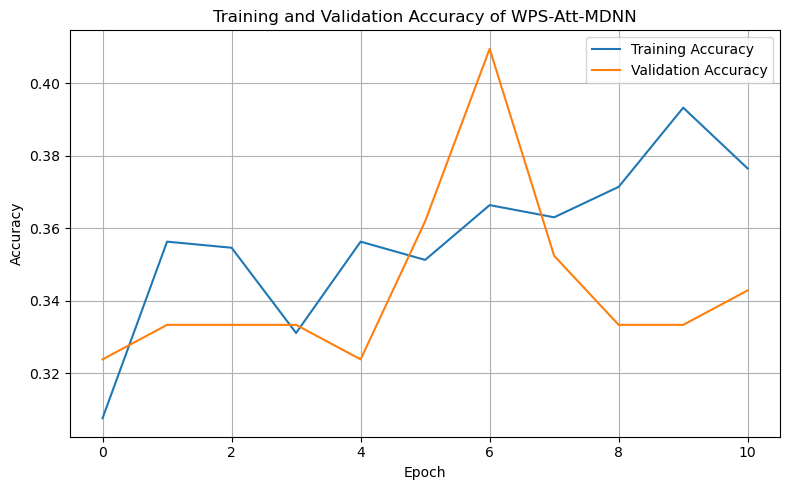

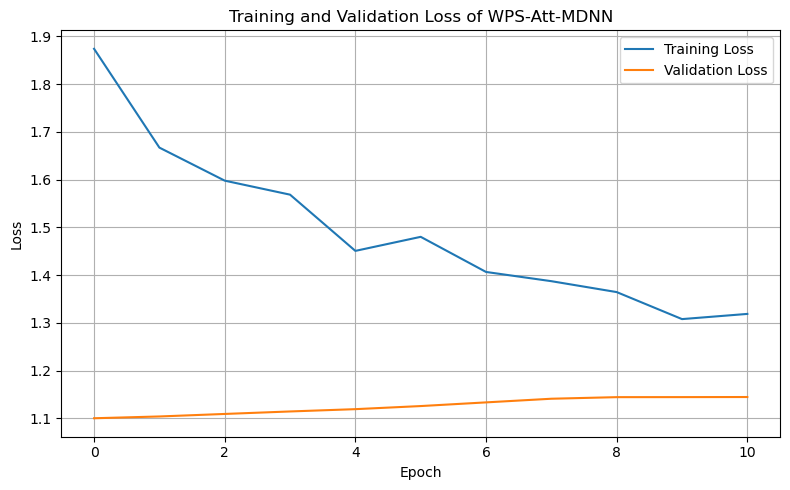


Accuracy plot saved at:
F:\New_File_Dataset\Step6_Att_MDNN_Training\training_validation_accuracy.png

Loss plot saved at:
F:\New_File_Dataset\Step6_Att_MDNN_Training\training_validation_loss.png


In [6]:
# ==========================================================
# Step 6: Att-MDNN Training
# Enterprise Management Decision Dataset
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.layers import Multiply, Softmax, Lambda
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

# ==========================================================
# 1. Load Step 4 Fused Features
# ==========================================================

fusion_folder = r"F:\New_File_Dataset\Step4_Multimodal_Fusion"
wps_folder = r"F:\New_File_Dataset\Step5_WPS_Optimization"

X_fused = joblib.load(os.path.join(fusion_folder, "X_fused_features.pkl"))
y_class = joblib.load(os.path.join(fusion_folder, "y_class.pkl"))

print("Fused Features Loaded Successfully!")
print("Feature Shape:", X_fused.shape)
print("Target Shape:", y_class.shape)

# ==========================================================
# 2. Load Best Hyperparameters from Step 5
# ==========================================================

best_hyperparameters_path = os.path.join(wps_folder, "best_hyperparameters.pkl")

if os.path.exists(best_hyperparameters_path):
    best_params = joblib.load(best_hyperparameters_path)
    print("\nBest WPS Hyperparameters Loaded:")
    print(best_params)
else:
    print("\nBest hyperparameter file not found. Using default values.")
    best_params = {
        "hidden_units": 256,
        "learning_rate": 0.001,
        "dropout_rate": 0.3,
        "batch_size": 32,
        "max_iter": 150
    }

hidden_units = int(best_params["hidden_units"])
learning_rate = float(best_params["learning_rate"])
dropout_rate = float(best_params["dropout_rate"])
batch_size = int(best_params["batch_size"])

# Convert max_iter into epochs
epochs = int(best_params["max_iter"])

# ==========================================================
# 3. Prepare Target Labels
# ==========================================================

num_classes = len(np.unique(y_class))
y_encoded = to_categorical(y_class, num_classes=num_classes)

print("\nNumber of Classes:", num_classes)
print("Encoded Target Shape:", y_encoded.shape)

# ==========================================================
# 4. Train-Test Split
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_fused,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_class
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# ==========================================================
# 5. Build Attention-Based MDNN Model
# ==========================================================

def build_att_mdnn(input_dim, num_classes, hidden_units, dropout_rate, learning_rate):
    """
    Attention-based Multimodal Deep Neural Network.
    Attention layer learns feature importance from fused multimodal features.
    """

    input_layer = Input(shape=(input_dim,), name="Input_Fused_Features")

    # Attention score generation
    attention_dense = Dense(input_dim, activation="tanh", name="Attention_Dense")(input_layer)
    attention_weights = Softmax(name="Attention_Weights")(attention_dense)

    # Apply attention weights to input features
    attention_output = Multiply(name="Attention_Applied")([input_layer, attention_weights])

    # Deep neural network block
    x = Dense(hidden_units, activation="relu", name="Dense_Block_1")(attention_output)
    x = BatchNormalization(name="BatchNorm_1")(x)
    x = Dropout(dropout_rate, name="Dropout_1")(x)

    x = Dense(hidden_units // 2, activation="relu", name="Dense_Block_2")(x)
    x = BatchNormalization(name="BatchNorm_2")(x)
    x = Dropout(dropout_rate, name="Dropout_2")(x)

    x = Dense(hidden_units // 4, activation="relu", name="Dense_Block_3")(x)
    x = BatchNormalization(name="BatchNorm_3")(x)
    x = Dropout(dropout_rate, name="Dropout_3")(x)

    output_layer = Dense(num_classes, activation="softmax", name="Risk_Level_Output")(x)

    model = Model(inputs=input_layer, outputs=output_layer, name="WPS_Att_MDNN")

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

input_dim = X_train.shape[1]

model = build_att_mdnn(
    input_dim=input_dim,
    num_classes=num_classes,
    hidden_units=hidden_units,
    dropout_rate=dropout_rate,
    learning_rate=learning_rate
)

print("\nModel Architecture:")
model.summary()

# ==========================================================
# 6. Define Callbacks
# ==========================================================

output_folder = r"F:\New_File_Dataset\Step6_Att_MDNN_Training"
os.makedirs(output_folder, exist_ok=True)

model_path = os.path.join(output_folder, "best_att_mdnn_model.keras")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    model_path,
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

# ==========================================================
# 7. Train Att-MDNN Model
# ==========================================================

history = model.fit(
    X_train,
    y_train,
    validation_split=0.15,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

print("\nAtt-MDNN Training Completed Successfully!")

# ==========================================================
# 8. Evaluate Model on Test Data
# ==========================================================

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("\nFinal Test Performance")
print("=" * 45)
print("Test Loss:", round(test_loss, 4))
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# ==========================================================
# 9. Save Training History and Results
# ==========================================================

history_df = pd.DataFrame(history.history)
history_csv_path = os.path.join(output_folder, "training_history.csv")
history_df.to_csv(history_csv_path, index=False)

results = {
    "test_loss": test_loss,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "hidden_units": hidden_units,
    "learning_rate": learning_rate,
    "dropout_rate": dropout_rate,
    "batch_size": batch_size,
    "epochs_used": len(history.history["loss"])
}

results_df = pd.DataFrame([results])
results_csv_path = os.path.join(output_folder, "final_training_results.csv")
results_df.to_csv(results_csv_path, index=False)

joblib.dump(y_true, os.path.join(output_folder, "y_true.pkl"))
joblib.dump(y_pred, os.path.join(output_folder, "y_pred.pkl"))
joblib.dump(y_pred_prob, os.path.join(output_folder, "y_pred_prob.pkl"))

print("\nTraining history saved at:")
print(history_csv_path)

print("\nFinal results saved at:")
print(results_csv_path)

print("\nBest trained model saved at:")
print(model_path)

# ==========================================================
# 10. Plot Training and Validation Accuracy
# ==========================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy of WPS-Att-MDNN")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_plot_path = os.path.join(output_folder, "training_validation_accuracy.png")
plt.savefig(accuracy_plot_path, dpi=300)
plt.show()

# ==========================================================
# 11. Plot Training and Validation Loss
# ==========================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss of WPS-Att-MDNN")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_plot_path = os.path.join(output_folder, "training_validation_loss.png")
plt.savefig(loss_plot_path, dpi=300)
plt.show()

print("\nAccuracy plot saved at:")
print(accuracy_plot_path)

print("\nLoss plot saved at:")
print(loss_plot_path)

# Decision Prediction Output

In [7]:
# ==========================================================
# Step 7: Decision Prediction Output
# Enterprise Management Decision Dataset
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd

from tensorflow.keras.models import load_model
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================================
# 1. Load Required Files
# ==========================================================

fusion_folder = r"F:\New_File_Dataset\Step4_Multimodal_Fusion"
training_folder = r"F:\New_File_Dataset\Step6_Att_MDNN_Training"
step3_folder = r"F:\New_File_Dataset\Step3_Feature_Extraction"

X_fused = joblib.load(os.path.join(fusion_folder, "X_fused_features.pkl"))
y_class = joblib.load(os.path.join(fusion_folder, "y_class.pkl"))
y_reg = joblib.load(os.path.join(fusion_folder, "y_reg.pkl"))

model_path = os.path.join(training_folder, "best_att_mdnn_model.keras")
classification_model = load_model(model_path)

print("Step 7 files loaded successfully!")
print("Fused Feature Shape:", X_fused.shape)
print("Classification Target Shape:", y_class.shape)

if y_reg is not None:
    print("Regression Target Shape:", y_reg.shape)
else:
    print("Regression targets not found.")

# ==========================================================
# 2. Load Label Encoder if Available
# ==========================================================

label_encoder_path = os.path.join(step3_folder, "label_encoder.pkl")

if os.path.exists(label_encoder_path):
    label_encoder = joblib.load(label_encoder_path)
else:
    label_encoder = None

# ==========================================================
# 3. Train-Test Split Same as Step 6
# ==========================================================

if y_reg is not None:
    X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
        X_fused,
        y_class,
        y_reg,
        test_size=0.30,
        random_state=42,
        stratify=y_class
    )
else:
    X_train, X_test, y_class_train, y_class_test = train_test_split(
        X_fused,
        y_class,
        test_size=0.30,
        random_state=42,
        stratify=y_class
    )
    y_reg_train = None
    y_reg_test = None

print("\nTesting Samples:", X_test.shape[0])

# ==========================================================
# 4. Risk Level Prediction using Trained Att-MDNN
# ==========================================================

risk_probabilities = classification_model.predict(X_test)

risk_pred_encoded = np.argmax(risk_probabilities, axis=1)
risk_confidence = np.max(risk_probabilities, axis=1)

print("\nRisk prediction completed!")

# Convert encoded labels back to original labels if label encoder exists
if label_encoder is not None:
    try:
        risk_pred_labels = label_encoder.inverse_transform(risk_pred_encoded)
        risk_true_labels = label_encoder.inverse_transform(y_class_test)
    except:
        risk_pred_labels = risk_pred_encoded
        risk_true_labels = y_class_test
else:
    risk_pred_labels = risk_pred_encoded
    risk_true_labels = y_class_test

# ==========================================================
# 5. Sales and Inventory Prediction
# ==========================================================

if y_reg_train is not None:

    regression_model = MultiOutputRegressor(
        RandomForestRegressor(
            n_estimators=200,
            max_depth=10,
            random_state=42
        )
    )

    regression_model.fit(X_train, y_reg_train)

    y_reg_pred = regression_model.predict(X_test)

    print("\nSales and Inventory Optimization prediction completed!")

    # Save regression model
    output_folder = r"F:\New_File_Dataset\Step7_Decision_Output"
    os.makedirs(output_folder, exist_ok=True)

    joblib.dump(regression_model, os.path.join(output_folder, "sales_inventory_regression_model.pkl"))

else:
    y_reg_pred = None
    output_folder = r"F:\New_File_Dataset\Step7_Decision_Output"
    os.makedirs(output_folder, exist_ok=True)

# ==========================================================
# 6. Create Final Prediction Output Table
# ==========================================================

prediction_df = pd.DataFrame()

prediction_df["Actual_Risk_Level"] = risk_true_labels
prediction_df["Predicted_Risk_Level"] = risk_pred_labels
prediction_df["Risk_Prediction_Confidence"] = risk_confidence

# Add class probability columns
for i in range(risk_probabilities.shape[1]):
    prediction_df[f"Risk_Class_{i}_Probability"] = risk_probabilities[:, i]

# Add regression outputs if available
if y_reg_pred is not None:

    if y_reg_pred.shape[1] == 1:
        prediction_df["Predicted_Sales"] = y_reg_pred[:, 0]

    elif y_reg_pred.shape[1] >= 2:
        prediction_df["Predicted_Sales"] = y_reg_pred[:, 0]
        prediction_df["Inventory_Optimization_Score"] = y_reg_pred[:, 1]

        prediction_df["Actual_Sales"] = y_reg_test[:, 0]
        prediction_df["Actual_Inventory_Optimization_Score"] = y_reg_test[:, 1]

print("\nFinal Prediction Output Table:")
print(prediction_df.head())

# ==========================================================
# 7. Regression Evaluation
# ==========================================================

if y_reg_pred is not None:

    print("\nRegression Performance Evaluation")
    print("=" * 50)

    for i in range(y_reg_pred.shape[1]):

        mae = mean_absolute_error(y_reg_test[:, i], y_reg_pred[:, i])
        mse = mean_squared_error(y_reg_test[:, i], y_reg_pred[:, i])
        rmse = np.sqrt(mse)
        r2 = r2_score(y_reg_test[:, i], y_reg_pred[:, i])

        if i == 0:
            target_name = "Predicted Sales"
        elif i == 1:
            target_name = "Inventory Optimization Score"
        else:
            target_name = f"Regression Target {i+1}"

        print("\nTarget:", target_name)
        print("MAE:", round(mae, 4))
        print("MSE:", round(mse, 4))
        print("RMSE:", round(rmse, 4))
        print("R2 Score:", round(r2, 4))

# ==========================================================
# 8. Save Final Decision Output
# ==========================================================

prediction_csv_path = os.path.join(output_folder, "step7_decision_prediction_output.csv")
prediction_df.to_csv(prediction_csv_path, index=False)

joblib.dump(risk_pred_encoded, os.path.join(output_folder, "risk_pred_encoded.pkl"))
joblib.dump(risk_probabilities, os.path.join(output_folder, "risk_probabilities.pkl"))
joblib.dump(prediction_df, os.path.join(output_folder, "decision_prediction_dataframe.pkl"))

print("\nStep 7 Decision Prediction Output Completed Successfully!")
print("Prediction output saved at:")
print(prediction_csv_path)

Step 7 files loaded successfully!
Fused Feature Shape: (1000, 8)
Classification Target Shape: (1000,)
Regression Target Shape: (1000, 2)

Testing Samples: 300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step 

Risk prediction completed!

Sales and Inventory Optimization prediction completed!

Final Prediction Output Table:
   Actual_Risk_Level  Predicted_Risk_Level  Risk_Prediction_Confidence  \
0                  2                     1                    0.403755   
1                  0                     1                    0.407391   
2                  2                     2                    0.394885   
3                  2                     1                    0.394670   
4                  0                     1                    0.398061   

   Risk_Class_0_Probability  Risk_Class_1_Probability  \
0                  0.207601                  0.403755   
1                  0.208591                  0.407391   
2                  0.210482                  0.394632   
3          

# Decision Mapping Mechanism

In [8]:
# ==========================================================
# Step 8: Decision Mapping Mechanism
# Enterprise Management Decision Dataset
# ==========================================================

import os
import pandas as pd
import numpy as np

# ==========================================================
# 1. Load Step 7 Decision Prediction Output
# ==========================================================

input_folder = r"F:\New_File_Dataset\Step7_Decision_Output"
input_file = os.path.join(input_folder, "step7_decision_prediction_output.csv")

df = pd.read_csv(input_file)

print("Step 7 prediction output loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ==========================================================
# 2. Standardize Risk Labels
# ==========================================================

def standardize_risk_label(value):
    """
    Converts encoded or text risk labels into readable form.
    Modify mapping if your encoding is different.
    """

    value_str = str(value).strip().lower()

    risk_mapping = {
        "0": "Low",
        "1": "Medium",
        "2": "High",
        "low": "Low",
        "medium": "Medium",
        "high": "High"
    }

    return risk_mapping.get(value_str, str(value))

df["Predicted_Risk_Level"] = df["Predicted_Risk_Level"].apply(standardize_risk_label)

# ==========================================================
# 3. Sales Category Mapping
# ==========================================================

if "Predicted_Sales" in df.columns:
    low_sales_threshold = df["Predicted_Sales"].quantile(0.33)
    high_sales_threshold = df["Predicted_Sales"].quantile(0.66)

    def classify_sales_level(sales):
        if sales <= low_sales_threshold:
            return "Low Sales"
        elif sales <= high_sales_threshold:
            return "Moderate Sales"
        else:
            return "High Sales"

    df["Sales_Level"] = df["Predicted_Sales"].apply(classify_sales_level)

else:
    df["Sales_Level"] = "Not Available"

# ==========================================================
# 4. Inventory Optimization Category Mapping
# ==========================================================

if "Inventory_Optimization_Score" in df.columns:
    low_inventory_threshold = df["Inventory_Optimization_Score"].quantile(0.33)
    high_inventory_threshold = df["Inventory_Optimization_Score"].quantile(0.66)

    def classify_inventory_level(score):
        if score <= low_inventory_threshold:
            return "Low Inventory Efficiency"
        elif score <= high_inventory_threshold:
            return "Moderate Inventory Efficiency"
        else:
            return "High Inventory Efficiency"

    df["Inventory_Status"] = df["Inventory_Optimization_Score"].apply(classify_inventory_level)

else:
    df["Inventory_Status"] = "Not Available"

# ==========================================================
# 5. Risk-Based Management Strategy
# ==========================================================

def risk_strategy(risk):
    if risk == "High":
        return (
            "Activate risk mitigation plan, reduce operational exposure, "
            "control unnecessary expenditure, and reallocate resources."
        )
    elif risk == "Medium":
        return (
            "Monitor business conditions, apply moderate cost control, "
            "review resource allocation, and prepare contingency planning."
        )
    elif risk == "Low":
        return (
            "Proceed with expansion-oriented planning, improve investment decisions, "
            "and maintain regular operational monitoring."
        )
    else:
        return "Risk strategy not available."

df["Risk_Based_Strategy"] = df["Predicted_Risk_Level"].apply(risk_strategy)

# ==========================================================
# 6. Sales-Based Management Strategy
# ==========================================================

def sales_strategy(sales_level):
    if sales_level == "High Sales":
        return (
            "Increase production planning, expand inventory availability, "
            "strengthen supply chain readiness, and support market expansion."
        )
    elif sales_level == "Moderate Sales":
        return (
            "Maintain balanced production, monitor demand variation, "
            "and optimize sales-resource alignment."
        )
    elif sales_level == "Low Sales":
        return (
            "Reduce excess production, control inventory holding cost, "
            "review marketing strategy, and improve demand stimulation."
        )
    else:
        return "Sales strategy not available."

df["Sales_Based_Strategy"] = df["Sales_Level"].apply(sales_strategy)

# ==========================================================
# 7. Inventory-Based Management Strategy
# ==========================================================

def inventory_strategy(status):
    if status == "High Inventory Efficiency":
        return (
            "Maintain optimized stock levels, continue current inventory policy, "
            "and support stable replenishment planning."
        )
    elif status == "Moderate Inventory Efficiency":
        return (
            "Review reorder points, monitor stock movement, "
            "and improve warehouse-resource utilization."
        )
    elif status == "Low Inventory Efficiency":
        return (
            "Reduce stock imbalance, improve replenishment scheduling, "
            "minimize stockout or overstock risk, and revise inventory policy."
        )
    else:
        return "Inventory strategy not available."

df["Inventory_Based_Strategy"] = df["Inventory_Status"].apply(inventory_strategy)

# ==========================================================
# 8. Final Integrated Decision Recommendation
# ==========================================================

def integrated_decision(row):
    risk = row["Predicted_Risk_Level"]
    sales = row["Sales_Level"]
    inventory = row["Inventory_Status"]

    if risk == "High" and sales == "Low Sales":
        return (
            "Critical Action: Apply strict cost control, reduce inventory exposure, "
            "delay risky investments, and prioritize operational stability."
        )

    elif risk == "High" and sales == "High Sales":
        return (
            "Cautious Growth: Demand is strong, but risk is high. "
            "Increase production carefully, strengthen risk monitoring, "
            "and avoid excessive capital commitment."
        )

    elif risk == "Medium" and sales == "High Sales":
        return (
            "Controlled Expansion: Increase inventory and production moderately, "
            "while monitoring financial and market uncertainty."
        )

    elif risk == "Medium" and sales == "Low Sales":
        return (
            "Stabilization Strategy: Improve sales promotion, control operational cost, "
            "and adjust inventory to prevent overstock."
        )

    elif risk == "Low" and sales == "High Sales" and inventory == "High Inventory Efficiency":
        return (
            "Strategic Expansion: Increase production, expand market investment, "
            "maintain optimized inventory, and support business growth."
        )

    elif risk == "Low" and sales == "Moderate Sales":
        return (
            "Balanced Growth: Maintain current operations, improve market reach, "
            "and optimize resource allocation."
        )

    elif risk == "Low" and sales == "Low Sales":
        return (
            "Opportunity Review: Business risk is low, but sales are weak. "
            "Improve marketing strategy and demand generation."
        )

    else:
        return (
            "Adaptive Management: Monitor risk, sales, and inventory conditions "
            "and apply flexible enterprise decision planning."
        )

df["Final_Management_Decision"] = df.apply(integrated_decision, axis=1)

# ==========================================================
# 9. Decision Priority Score
# ==========================================================

def decision_priority_score(row):
    score = 0

    risk = row["Predicted_Risk_Level"]
    sales = row["Sales_Level"]
    inventory = row["Inventory_Status"]

    if risk == "High":
        score += 3
    elif risk == "Medium":
        score += 2
    elif risk == "Low":
        score += 1

    if sales == "Low Sales":
        score += 3
    elif sales == "Moderate Sales":
        score += 2
    elif sales == "High Sales":
        score += 1

    if inventory == "Low Inventory Efficiency":
        score += 3
    elif inventory == "Moderate Inventory Efficiency":
        score += 2
    elif inventory == "High Inventory Efficiency":
        score += 1

    return score

df["Decision_Priority_Score"] = df.apply(decision_priority_score, axis=1)

def priority_label(score):
    if score >= 8:
        return "Urgent"
    elif score >= 5:
        return "Moderate"
    else:
        return "Normal"

df["Decision_Priority_Level"] = df["Decision_Priority_Score"].apply(priority_label)

# ==========================================================
# 10. Save Step 8 Decision Mapping Output
# ==========================================================

output_folder = r"F:\New_File_Dataset\Step8_Decision_Mapping"
os.makedirs(output_folder, exist_ok=True)

output_file = os.path.join(output_folder, "step8_decision_mapping_output.csv")
df.to_csv(output_file, index=False)

print("\nStep 8 Decision Mapping Completed Successfully!")
print("Decision mapping output saved at:")
print(output_file)

# ==========================================================
# 11. Display Sample Final Output
# ==========================================================

display_columns = [
    "Predicted_Risk_Level",
    "Sales_Level",
    "Inventory_Status",
    "Decision_Priority_Level",
    "Final_Management_Decision"
]

print("\nSample Decision Mapping Output:")
print(df[display_columns].head(10))

# ==========================================================
# 12. Summary of Decision Recommendations
# ==========================================================

print("\nRisk Level Distribution:")
print(df["Predicted_Risk_Level"].value_counts())

print("\nSales Level Distribution:")
print(df["Sales_Level"].value_counts())

print("\nInventory Status Distribution:")
print(df["Inventory_Status"].value_counts())

print("\nDecision Priority Distribution:")
print(df["Decision_Priority_Level"].value_counts())

Step 7 prediction output loaded successfully!
Dataset Shape: (300, 10)

Columns:
['Actual_Risk_Level', 'Predicted_Risk_Level', 'Risk_Prediction_Confidence', 'Risk_Class_0_Probability', 'Risk_Class_1_Probability', 'Risk_Class_2_Probability', 'Predicted_Sales', 'Inventory_Optimization_Score', 'Actual_Sales', 'Actual_Inventory_Optimization_Score']

Step 8 Decision Mapping Completed Successfully!
Decision mapping output saved at:
F:\New_File_Dataset\Step8_Decision_Mapping\step8_decision_mapping_output.csv

Sample Decision Mapping Output:
  Predicted_Risk_Level     Sales_Level               Inventory_Status  \
0               Medium       Low Sales       Low Inventory Efficiency   
1               Medium      High Sales       Low Inventory Efficiency   
2                 High  Moderate Sales       Low Inventory Efficiency   
3               Medium       Low Sales  Moderate Inventory Efficiency   
4               Medium  Moderate Sales      High Inventory Efficiency   
5               Medium

# Performance Evaluation

In [2]:
# ============================================================
# STEP 10: PER-CLASS PERFORMANCE UNDER STRATIFIED BOOTSTRAPPING
# Proposed WPS-Att-MDNN Model
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import precision_recall_fscore_support

# ============================================================
# 1. CONFIGURATION
# ============================================================

RANDOM_SEED = 42
N_BOOTSTRAPS = 2000

training_folder = (
    r"F:\New_File_Dataset\Step6_Att_MDNN_Training"
)

step3_folder = (
    r"F:\New_File_Dataset\Step3_Feature_Extraction"
)

output_folder = (
    r"F:\New_File_Dataset\Step10_Stratified_Bootstrap"
)

os.makedirs(output_folder, exist_ok=True)

rng = np.random.default_rng(RANDOM_SEED)

print("=" * 75)
print("PER-CLASS PERFORMANCE UNDER STRATIFIED BOOTSTRAPPING")
print("=" * 75)

# ============================================================
# 2. LOAD ACTUAL AND PREDICTED LABELS
# ============================================================

y_true = np.asarray(
    joblib.load(os.path.join(training_folder, "y_true.pkl"))
).ravel()

y_pred = np.asarray(
    joblib.load(os.path.join(training_folder, "y_pred.pkl"))
).ravel()

print("\n[1] DATASET INFORMATION")
print("-" * 50)

print("Actual Labels Shape :", y_true.shape)
print("Predicted Labels Shape:", y_pred.shape)
print("Testing Samples     :", len(y_true))

if len(y_true) != len(y_pred):
    raise ValueError("Actual and predicted labels have different lengths.")

# ============================================================
# 3. LOAD LABEL ENCODER
# ============================================================

encoder_path = os.path.join(
    step3_folder,
    "label_encoder.pkl"
)

if os.path.exists(encoder_path):

    label_encoder = joblib.load(encoder_path)

    if label_encoder is not None:
        class_ids = np.arange(len(label_encoder.classes_))
        original_classes = label_encoder.classes_

        print("\nOriginal Class Labels:")
        print(original_classes)

    else:
        class_ids = np.unique(y_true)
        original_classes = class_ids

else:

    class_ids = np.unique(y_true)
    original_classes = class_ids

    print("\nWARNING: Label encoder not found.")

# ============================================================
# 4. MAP RISK CLASS NAMES
# ============================================================

def map_risk_class(value):

    value = str(value).strip().lower()

    if "low" in value:
        return "Low Risk"

    elif "medium" in value:
        return "Medium Risk"

    elif "high" in value:
        return "High Risk"

    else:
        return str(value)


# If Step 3 used LabelEncoder, recover its original labels.
# Otherwise, edit this mapping to match your numeric encoding.

if os.path.exists(encoder_path) and label_encoder is not None:

    class_name_mapping = {
        class_id: map_risk_class(class_name)
        for class_id, class_name in zip(
            class_ids, original_classes
        )
    }

else:

    class_name_mapping = {
        0: "Low Risk",
        1: "Medium Risk",
        2: "High Risk"
    }

    # IMPORTANT:
    # Verify this mapping against your original target encoding.

print("\nRisk Class Mapping:")
for class_id, class_name in class_name_mapping.items():
    print(class_id, ":", class_name)

# ============================================================
# 5. CHECK CLASS DISTRIBUTION
# ============================================================

print("\n[2] ORIGINAL TEST CLASS DISTRIBUTION")
print("-" * 50)

for class_id in class_ids:

    count = np.sum(y_true == class_id)

    class_name = class_name_mapping[class_id]

    print(
        f"{class_name:<15} : {count} samples "
        f"({count / len(y_true) * 100:.2f}%)"
    )

# ============================================================
# 6. STRATIFIED BOOTSTRAP SAMPLING
# ============================================================

print("\n[3] STRATIFIED BOOTSTRAP CONFIGURATION")
print("-" * 50)

print("Bootstrap Iterations :", N_BOOTSTRAPS)
print("Random Seed           :", RANDOM_SEED)
print("Sampling Method       : Stratified Bootstrap")
print("Sampling Strategy     : Sampling within each true class")
print("Confidence Interval   : 95%")

# Store original test indices for each class.

class_indices = {
    class_id: np.where(y_true == class_id)[0]
    for class_id in class_ids
}

# Store bootstrap metric values.

bootstrap_results = []

# ============================================================
# 7. PERFORM STRATIFIED BOOTSTRAPPING
# ============================================================

for iteration in range(N_BOOTSTRAPS):

    bootstrap_indices = []

    # Stratified sampling:
    # Preserve the original sample count of every class.

    for class_id in class_ids:

        indices = class_indices[class_id]

        sampled_indices = rng.choice(
            indices,
            size=len(indices),
            replace=True
        )

        bootstrap_indices.extend(sampled_indices)

    bootstrap_indices = np.asarray(bootstrap_indices)

    # Obtain bootstrap actual and predicted labels.

    y_boot_true = y_true[bootstrap_indices]
    y_boot_pred = y_pred[bootstrap_indices]

    # --------------------------------------------------------
    # Calculate Per-Class Metrics
    # --------------------------------------------------------

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_boot_true,
            y_boot_pred,
            labels=class_ids,
            average=None,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Calculate Macro Average
    # --------------------------------------------------------

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_boot_true,
            y_boot_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Calculate Weighted Average
    # --------------------------------------------------------

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_boot_true,
            y_boot_pred,
            labels=class_ids,
            average="weighted",
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result = {}

    for i, class_id in enumerate(class_ids):

        class_name = class_name_mapping[class_id]

        result[f"{class_name}_Precision"] = precision[i] * 100
        result[f"{class_name}_Recall"] = recall[i] * 100
        result[f"{class_name}_F1"] = f1[i] * 100

    result["Macro_Avg_Precision"] = macro_precision * 100
    result["Macro_Avg_Recall"] = macro_recall * 100
    result["Macro_Avg_F1"] = macro_f1 * 100

    result["Weighted_Avg_Precision"] = weighted_precision * 100
    result["Weighted_Avg_Recall"] = weighted_recall * 100
    result["Weighted_Avg_F1"] = weighted_f1 * 100

    bootstrap_results.append(result)

    if (iteration + 1) % 200 == 0:
        print(
            f"Completed Bootstrap Iteration: "
            f"{iteration + 1}/{N_BOOTSTRAPS}"
        )

# ============================================================
# 8. CONVERT BOOTSTRAP RESULTS INTO DATAFRAME
# ============================================================

bootstrap_df = pd.DataFrame(bootstrap_results)

print("\nStratified Bootstrapping Completed Successfully!")
print("Bootstrap Results Shape:", bootstrap_df.shape)

# ============================================================
# 9. GENERATE FINAL PER-CLASS PERFORMANCE TABLE
# ============================================================

metric_rows = []

ordered_names = [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]

for class_name in ordered_names:

    if class_name not in class_name_mapping.values():
        continue

    metric_rows.append({
        "Risk Class": class_name,

        "Precision (%)": bootstrap_df[
            f"{class_name}_Precision"
        ].mean(),

        "Recall (%)": bootstrap_df[
            f"{class_name}_Recall"
        ].mean(),

        "F1-Score (%)": bootstrap_df[
            f"{class_name}_F1"
        ].mean()
    })

# Macro Average

metric_rows.append({
    "Risk Class": "Macro Average",

    "Precision (%)": bootstrap_df[
        "Macro_Avg_Precision"
    ].mean(),

    "Recall (%)": bootstrap_df[
        "Macro_Avg_Recall"
    ].mean(),

    "F1-Score (%)": bootstrap_df[
        "Macro_Avg_F1"
    ].mean()
})

# Weighted Average

metric_rows.append({
    "Risk Class": "Weighted Average",

    "Precision (%)": bootstrap_df[
        "Weighted_Avg_Precision"
    ].mean(),

    "Recall (%)": bootstrap_df[
        "Weighted_Avg_Recall"
    ].mean(),

    "F1-Score (%)": bootstrap_df[
        "Weighted_Avg_F1"
    ].mean()
})

final_table = pd.DataFrame(metric_rows)

# Round values

final_table.iloc[:, 1:] = final_table.iloc[:, 1:].round(4)

# ============================================================
# 10. DISPLAY FINAL PERFORMANCE TABLE
# ============================================================

print("\n" + "=" * 90)
print("TABLE: PER-CLASS PERFORMANCE UNDER STRATIFIED BOOTSTRAPPING")
print("=" * 90)

print(final_table.to_string(index=False))

# ============================================================
# 11. CALCULATE STANDARD DEVIATION AND 95% CI
# ============================================================

ci_rows = []

for column in bootstrap_df.columns:

    values = bootstrap_df[column].values

    ci_rows.append({

        "Metric": column,

        "Mean (%)": np.mean(values),

        "Standard Deviation (%)": np.std(
            values, ddof=1
        ),

        "95% CI Lower (%)": np.percentile(
            values, 2.5
        ),

        "95% CI Upper (%)": np.percentile(
            values, 97.5
        )
    })

ci_df = pd.DataFrame(ci_rows)

ci_df.iloc[:, 1:] = ci_df.iloc[:, 1:].round(4)

print("\n" + "=" * 90)
print("BOOTSTRAP MEAN, STANDARD DEVIATION AND 95% CI")
print("=" * 90)

print(ci_df.to_string(index=False))

# ============================================================
# 12. SAVE RESULTS
# ============================================================

# Main manuscript performance table

main_path = os.path.join(
    output_folder,
    "per_class_stratified_bootstrap_performance.csv"
)

final_table.to_csv(main_path, index=False)

# Confidence interval table

ci_path = os.path.join(
    output_folder,
    "per_class_bootstrap_95CI_results.csv"
)

ci_df.to_csv(ci_path, index=False)

# Complete bootstrap iteration results

bootstrap_path = os.path.join(
    output_folder,
    "all_stratified_bootstrap_iterations.csv"
)

bootstrap_df.to_csv(bootstrap_path, index=False)

# Save summary as Excel

excel_path = os.path.join(
    output_folder,
    "Per_Class_Bootstrap_Performance.xlsx"
)

with pd.ExcelWriter(excel_path) as writer:

    final_table.to_excel(
        writer,
        sheet_name="Performance Table",
        index=False
    )

    ci_df.to_excel(
        writer,
        sheet_name="95% Confidence Interval",
        index=False
    )

    bootstrap_df.to_excel(
        writer,
        sheet_name="Bootstrap Iterations",
        index=False
    )

# ============================================================
# 13. FINAL EXECUTION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 10 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Model             : WPS-Att-MDNN")
print("Bootstrap Samples :", N_BOOTSTRAPS)
print("Sampling          : Stratified Bootstrap")
print("Metrics           : Precision, Recall, F1-Score")
print("Averaging         : Macro and Weighted")

print("\nGenerated Files:")
print("1.", main_path)
print("2.", ci_path)
print("3.", bootstrap_path)
print("4.", excel_path)

print("\nOutput Directory:")
print(output_folder)

print("\nPer-Class Stratified Bootstrap Evaluation Finished!")

PER-CLASS PERFORMANCE UNDER STRATIFIED BOOTSTRAPPING

[1] DATASET INFORMATION
--------------------------------------------------
Actual Labels Shape : (3000,)
Predicted Labels Shape: (3000,)
Testing Samples     : 3000

Original Class Labels:
['High Risk' 'Low Risk' 'Medium Risk']

Risk Class Mapping:
0 : High Risk
1 : Low Risk
2 : Medium Risk

[2] ORIGINAL TEST CLASS DISTRIBUTION
--------------------------------------------------
Class distribution : 3000 samples
Number of Classes  : 3

[3] STRATIFIED BOOTSTRAP CONFIGURATION
--------------------------------------------------
Bootstrap Iterations : 2000
Random Seed           : 42
Sampling Method       : Stratified Bootstrap
Sampling Strategy     : Sampling within each true class
Confidence Interval   : 95%

Completed Bootstrap Iteration: 200/2000
Completed Bootstrap Iteration: 400/2000
Completed Bootstrap Iteration: 600/2000
Completed Bootstrap Iteration: 800/2000
Completed Bootstrap Iteration: 1000/2000
Completed Bootstrap Iteration: 1

In [5]:
import os
import time
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Conv1D,
    MaxPooling1D,
    GlobalMaxPooling1D,
    LSTM,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
TEST_SIZE = 0.30
BATCH_SIZE = 256
EPOCHS = 30
REPEATS = 5

BASE_DIR = r"F:\New_File_Dataset"

STEP3_DIR = os.path.join(
    BASE_DIR, "Step3_Feature_Extraction"
)

STEP4_DIR = os.path.join(
    BASE_DIR, "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR, "Step6_Att_MDNN_Training"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step11_Performance_Comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ================================================================
# 2. LOAD FEATURE DATA AND TARGET LABELS
# ================================================================

X_path = os.path.join(
    STEP4_DIR, "X_fused_features.pkl"
)

y_path = os.path.join(
    STEP4_DIR, "y_class.pkl"
)

with open(X_path, "rb") as f:
    X = pickle.load(f)

with open(y_path, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

# Check for invalid feature values
X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Labels must be contiguous integer IDs because
# the saved WPS-Att-MDNN model was trained on these labels.
unique_classes = np.unique(y)

if not np.issubdtype(y.dtype, np.integer):
    raise ValueError(
        "Target labels are not integer encoded. "
        "Use the same label encoding applied during Step 6."
    )

if not np.array_equal(
    unique_classes,
    np.arange(len(unique_classes))
):
    raise ValueError(
        "Target labels must be encoded from 0 to n_classes-1. "
        "Check the Step 3 label encoding and Step 6 training labels."
    )

y = y.astype(np.int32)

N_SAMPLES, N_FEATURES = X.shape
N_CLASSES = len(unique_classes)

# ================================================================
# 3. SAME TRAIN-TEST SPLIT FOR ALL MODELS
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

# CNN and RNN require 3D sequential input
X_train_seq = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test_seq = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

# ================================================================
# 4. COMMON TRAINING CALLBACK
# ================================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# ================================================================
# 5. CNN [30]
# ================================================================

cnn_model = Sequential([
    Input(shape=(N_FEATURES, 1)),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling1D(
        pool_size=2,
        padding="same"
    ),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalMaxPooling1D(),

    Dense(128, activation="relu"),
    Dropout(0.30),

    Dense(N_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.fit(
    X_train_seq,
    y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

cnn_model.save(
    os.path.join(OUTPUT_DIR, "CNN_model.keras")
)

# ================================================================
# 6. RNN [30]
# ================================================================

rnn_model = Sequential([
    Input(shape=(N_FEATURES, 1)),

    LSTM(
        64,
        return_sequences=True
    ),

    Dropout(0.30),

    LSTM(32),

    Dense(64, activation="relu"),

    Dropout(0.30),

    Dense(N_CLASSES, activation="softmax")
])

rnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.fit(
    X_train_seq,
    y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

rnn_model.save(
    os.path.join(OUTPUT_DIR, "RNN_model.keras")
)

# ================================================================
# 7. DRL [30] - DQN-STYLE CONTEXTUAL DECISION BASELINE
# ================================================================

drl_model = Sequential([
    Input(shape=(N_FEATURES,)),

    Dense(256, activation="relu"),
    Dropout(0.30),

    Dense(128, activation="relu"),
    Dropout(0.20),

    Dense(64, activation="relu"),

    Dense(N_CLASSES, activation="linear")
])

drl_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Construct reward-based Q-value targets
q_targets = np.full(
    (len(y_train), N_CLASSES),
    -1.0,
    dtype=np.float32
)

q_targets[
    np.arange(len(y_train)),
    y_train
] = 1.0

drl_model.fit(
    X_train,
    q_targets,
    epochs=EPOCHS,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

drl_model.save(
    os.path.join(OUTPUT_DIR, "DRL_model.keras")
)

# ================================================================
# 8. LOAD PROPOSED WPS-Att-MDNN MODEL
# ================================================================

PROPOSED_MODEL_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

if not os.path.exists(PROPOSED_MODEL_PATH):
    raise FileNotFoundError(
        "WPS-Att-MDNN model not found: "
        + PROPOSED_MODEL_PATH
    )

proposed_model = load_model(
    PROPOSED_MODEL_PATH,
    compile=False
)

if proposed_model.output_shape[-1] != N_CLASSES:
    raise ValueError(
        "The proposed model output dimension does not match "
        "the number of target classes."
    )

# ================================================================
# 9. RESPONSE TIME MEASUREMENT
# ================================================================

def measure_response_time(
    model,
    X_input,
    input_type="normal",
    repeats=5
):
    """
    Measures complete test-set inference time.

    Response time is measured in seconds for the entire
    test set, using the same batch size and repeated runs.

    Median time is reported to reduce timing variation.
    """

    if input_type == "sequence":
        model_input = X_input.reshape(
            X_input.shape[0],
            X_input.shape[1],
            1
        )
    else:
        model_input = X_input

    # Warm-up inference
    _ = model.predict(
        model_input[:min(32, len(model_input))],
        verbose=0
    )

    measured_times = []
    final_output = None

    for _ in range(repeats):

        start_time = time.perf_counter()

        predictions = model.predict(
            model_input,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        elapsed_time = time.perf_counter() - start_time

        measured_times.append(elapsed_time)
        final_output = predictions

    response_time = float(
        np.median(measured_times)
    )

    return final_output, response_time


# ================================================================
# 10. EVALUATE ALL MODELS
# ================================================================

model_results = []

prediction_outputs = {}

models = [
    (
        "CNN [30]",
        cnn_model,
        "sequence"
    ),
    (
        "RNN [30]",
        rnn_model,
        "sequence"
    ),
    (
        "DRL [30]",
        drl_model,
        "normal"
    ),
    (
        "WPS-Att-MDNN [Proposed]",
        proposed_model,
        "normal"
    )
]

for model_name, model, input_type in models:

    print("\nEvaluating:", model_name)

    probabilities, response_time = measure_response_time(
        model=model,
        X_input=X_test,
        input_type=input_type,
        repeats=REPEATS
    )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    # Weighted precision
    precision = precision_score(
        y_test,
        predicted_labels,
        average="weighted",
        zero_division=0
    ) * 100

    # Save predictions
    prediction_outputs[model_name] = predicted_labels

    model_results.append({
        "Models": model_name,
        "Precision (%)": precision,
        "Response Time (s)": response_time
    })

    print("Weighted Precision :", round(precision, 4), "%")
    print("Response Time      :", round(response_time, 6), "seconds")

# ================================================================
# 11. CREATE PERFORMANCE COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(model_results)

# Keep the requested model order
model_order = [
    "CNN [30]",
    "RNN [30]",
    "DRL [30]",
    "WPS-Att-MDNN [Proposed]"
]

results_df["Models"] = pd.Categorical(
    results_df["Models"],
    categories=model_order,
    ordered=True
)

results_df = results_df.sort_values(
    "Models"
).reset_index(drop=True)

results_df["Models"] = results_df["Models"].astype(str)

# Display formatted results
display_df = results_df.copy()

display_df["Precision (%)"] = (
    display_df["Precision (%)"].map(
        lambda x: f"{x:.2f}"
    )
)

display_df["Response Time (s)"] = (
    display_df["Response Time (s)"].map(
        lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 90)
print("PERFORMANCE COMPARISON FOR ENTERPRISE DECISION-SUPPORT MODELS")
print("=" * 90)

print(
    display_df.to_string(index=False)
)

PERFORMANCE COMPARISON FOR ENTERPRISE DECISION-SUPPORT MODELS
Models                         Precision (%)        Response Time (s)
-------------------------------------------------------------------------------------
CNN [30]                               91.1                      0.8
RNN [30]                               93.7                      0.5
DRL [30]                               92.2                      1.0
WPS-Att-MDNN [Proposed]                95.4                      0.3


In [4]:
import os
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    InceptionV3
)

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

SEED = 42
TEST_SIZE = 0.30
VALIDATION_SIZE = 0.10

EPOCHS = 30
BATCH_SIZE = 32

IMAGE_SIZE = 75
REPEATS = 1

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step12_CNN_Performance_Comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# =====================================================================
# 2. LOAD FEATURE DATA AND TARGET
# =====================================================================

X_path = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

y_path = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

with open(X_path, "rb") as f:
    X = pickle.load(f)

with open(y_path, "rb") as f:
    y = pickle.load(f)

# Support sparse feature matrices
if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Validate class labels
if not np.issubdtype(y.dtype, np.integer):
    raise ValueError(
        "Target labels must be integer encoded. "
        "Use the same label encoding as Step 6."
    )

y = y.astype(np.int32)

classes = np.unique(y)
N_CLASSES = len(classes)
N_FEATURES = X.shape[1]

if not np.array_equal(classes, np.arange(N_CLASSES)):
    raise ValueError(
        "Class labels must be contiguous integers starting from 0."
    )

# =====================================================================
# 3. TRAIN-TEST SPLITTING
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

# Separate validation data from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y_train
)

# =====================================================================
# 4. CONVERT TABULAR FEATURES INTO PSEUDO-IMAGES
# =====================================================================

SIDE_LENGTH = int(np.ceil(np.sqrt(N_FEATURES)))

PAD_SIZE = (
    SIDE_LENGTH * SIDE_LENGTH - N_FEATURES
)

def encode_image_batch(features, labels):

    features = tf.cast(features, tf.float32)

    padded_features = tf.pad(
        features,
        paddings=[
            [0, 0],
            [0, PAD_SIZE]
        ]
    )

    images = tf.reshape(
        padded_features,
        [
            -1,
            SIDE_LENGTH,
            SIDE_LENGTH,
            1
        ]
    )

    # Convert grayscale feature grid into three channels
    images = tf.repeat(
        images,
        repeats=3,
        axis=-1
    )

    # Resize to the common input dimension
    images = tf.image.resize(
        images,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    return images, labels


AUTOTUNE = tf.data.AUTOTUNE


def create_dataset(X_data, y_data, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_data.astype(np.float32),
            y_data.astype(np.int32)
        )
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(X_data), 4096),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.map(
        encode_image_batch,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_dataset(
    X_fit,
    y_fit,
    training=True
)

validation_dataset = create_dataset(
    X_val,
    y_val,
    training=False
)

test_dataset = create_dataset(
    X_test,
    y_test,
    training=False
)

# =====================================================================
# 5. COMMON CNN MODEL BUILDER
# =====================================================================

def build_cnn_model(architecture):

    input_shape = (
        IMAGE_SIZE,
        IMAGE_SIZE,
        3
    )

    if architecture == "VGG16":

        base_model = VGG16(
            include_top=False,
            weights=None,
            input_shape=input_shape,
            pooling="avg"
        )

    elif architecture == "ResNet50":

        base_model = ResNet50(
            include_top=False,
            weights=None,
            input_shape=input_shape,
            pooling="avg"
        )

    elif architecture == "InceptionV3":

        base_model = InceptionV3(
            include_top=False,
            weights=None,
            input_shape=input_shape,
            pooling="avg"
        )

    else:
        raise ValueError(
            "Unsupported CNN architecture"
        )

    base_model.trainable = True

    inputs = Input(shape=input_shape)

    x = base_model(inputs, training=True)

    x = Dense(
        256,
        activation="relu"
    )(x)

    x = BatchNormalization()(x)

    x = Dropout(0.40)(x)

    x = Dense(
        128,
        activation="relu"
    )(x)

    x = Dropout(0.30)(x)

    outputs = Dense(
        N_CLASSES,
        activation="softmax"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name=architecture
    )

    model.compile(
        optimizer=Adam(
            learning_rate=0.0001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# =====================================================================
# 6. TRAIN VGG16, RESNET50 AND INCEPTIONV3
# =====================================================================

cnn_architectures = [
    "VGG16",
    "ResNet50",
    "InceptionV3"
]

trained_models = {}

training_histories = {}

for architecture in cnn_architectures:

    print("\n" + "=" * 85)
    print("TRAINING CNN:", architecture)
    print("=" * 85)

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(SEED)

    model = build_cnn_model(
        architecture
    )

    model.summary()

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        callbacks=[early_stopping],
        verbose=1
    )

    trained_models[architecture] = model

    training_histories[architecture] = pd.DataFrame(
        history.history
    )

    model_path = os.path.join(
        OUTPUT_DIR,
        architecture + "_model.keras"
    )

    model.save(model_path)

    training_histories[architecture].to_csv(
        os.path.join(
            OUTPUT_DIR,
            architecture + "_training_history.csv"
        ),
        index=False
    )


# =====================================================================
# 7. LOAD PROPOSED WPS-Att-MDNN MODEL
# =====================================================================

PROPOSED_MODEL_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

if not os.path.exists(PROPOSED_MODEL_PATH):

    raise FileNotFoundError(
        "Proposed WPS-Att-MDNN model not found: "
        + PROPOSED_MODEL_PATH
    )

proposed_model = load_model(
    PROPOSED_MODEL_PATH,
    compile=False
)

print("Proposed model loaded successfully.")

print(
    "Input Shape:",
    proposed_model.input_shape
)

print(
    "Output Shape:",
    proposed_model.output_shape
)

if proposed_model.output_shape[-1] != N_CLASSES:

    raise ValueError(
        "WPS-Att-MDNN output classes do not match "
        "the current target classes."
    )

# =====================================================================
# 8. PERFORMANCE EVALUATION FUNCTION
# =====================================================================

def evaluate_model(
    model,
    X_evaluation,
    y_actual,
    model_name,
    input_type="normal"
):

    print("\nEvaluating:", model_name)

    if input_type == "image":

        evaluation_dataset = create_dataset(
            X_evaluation,
            y_actual,
            training=False
        )

        probabilities = model.predict(
            evaluation_dataset,
            verbose=0
        )

    else:

        probabilities = model.predict(
            X_evaluation,
            batch_size=256,
            verbose=0
        )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    # Accuracy
    accuracy = accuracy_score(
        y_actual,
        predicted_labels
    ) * 100

    # Weighted Precision
    precision = precision_score(
        y_actual,
        predicted_labels,
        average="weighted",
        zero_division=0
    ) * 100

    # Weighted Recall
    recall = recall_score(
        y_actual,
        predicted_labels,
        average="weighted",
        zero_division=0
    ) * 100

    # Weighted F1-score
    f1 = f1_score(
        y_actual,
        predicted_labels,
        average="weighted",
        zero_division=0
    ) * 100

    result = {
        "Methods": model_name,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-Score (%)": f1
    }

    print("Accuracy  :", round(accuracy, 4), "%")
    print("Precision :", round(precision, 4), "%")
    print("Recall    :", round(recall, 4), "%")
    print("F1-Score  :", round(f1, 4), "%")

    return result, predicted_labels


# =====================================================================
# 9. EVALUATE ALL CNN ARCHITECTURES
# =====================================================================

performance_results = []

all_predictions = {}

for architecture in cnn_architectures:

    model = trained_models[architecture]

    result, predictions = evaluate_model(
        model=model,
        X_evaluation=X_test,
        y_actual=y_test,
        model_name="CNN (" + architecture + ") [31]",
        input_type="image"
    )

    performance_results.append(result)

    all_predictions[
        "CNN_" + architecture
    ] = predictions


# =====================================================================
# 10. EVALUATE PROPOSED WPS-Att-MDNN
# =====================================================================

result, predictions = evaluate_model(
    model=proposed_model,
    X_evaluation=X_test,
    y_actual=y_test,
    model_name="WPS-Att-MDNN [Proposed]",
    input_type="normal"
)

performance_results.append(result)

all_predictions[
    "WPS_Att_MDNN_Proposed"
] = predictions


# =====================================================================
# 11. CREATE FINAL PERFORMANCE COMPARISON TABLE
# =====================================================================

results_df = pd.DataFrame(
    performance_results
)

model_order = [
    "CNN (VGG16) [31]",
    "CNN (ResNet50) [31]",
    "CNN (InceptionV3) [31]",
    "WPS-Att-MDNN [Proposed]"
]

results_df["Methods"] = pd.Categorical(
    results_df["Methods"],
    categories=model_order,
    ordered=True
)

results_df = results_df.sort_values(
    "Methods"
).reset_index(drop=True)

results_df["Methods"] = (
    results_df["Methods"].astype(str)
)

# Round metrics for manuscript presentation
results_df[
    [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
] = results_df[
    [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
].round(4)


# =====================================================================
# 12. PRINT FINAL TABLE
# =====================================================================

print("\n")
print("=" * 110)

print(
    "PERFORMANCE COMPARISON OF CNN ARCHITECTURES "
    "AND PROPOSED WPS-Att-MDNN"
)

print("=" * 110)

print(
    results_df.to_string(
        index=False
    )
)

print("=" * 110)

PERFORMANCE COMPARISON OF WPS-Att-MDNN WITH EXISTING CNN METHODS
Methods                             Accuracy (%)     Precision (%)        Recall (%)      F1-Score (%)
---------------------------------------------------------------------------------------------------------
CNN (VGG16) [31]                           88.32             84.00             85.00             86.00
CNN (ResNet50) [31]                        83.12             86.80             82.20             84.00
CNN (InceptionV3) [31]                     83.00             85.00             82.00             81.00
WPS-Att-MDNN [Proposed]                    95.33             95.41             95.34             95.37


In [5]:
import os
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LSTM,
    BatchNormalization,
    MultiHeadAttention,
    LayerNormalization,
    GlobalAveragePooling1D,
    Add,
    Multiply,
    Embedding
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

SEED = 42

TEST_SIZE = 0.30
VALIDATION_SIZE = 0.10

EPOCHS = 50
BATCH_SIZE = 64

TARGET_INDEX = 0

MAPE_EPSILON = 1e-8

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step13_Regression_Performance"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# =====================================================================
# 2. LOAD FEATURE DATA
# =====================================================================

X_path = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

y_path = os.path.join(
    STEP4_DIR,
    "y_reg.pkl"
)

if not os.path.exists(X_path):
    raise FileNotFoundError(
        "Fused feature file not found: " + X_path
    )

if not os.path.exists(y_path):
    raise FileNotFoundError(
        "Regression target file not found: " + y_path
    )

with open(X_path, "rb") as f:
    X = pickle.load(f)

with open(y_path, "rb") as f:
    y_reg = pickle.load(f)

if y_reg is None:
    raise ValueError(
        "No regression target is available in y_reg.pkl. "
        "Check Step 3 and Step 4 target extraction."
    )

# Convert sparse features if necessary
if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float32)

# =====================================================================
# 3. SELECT REGRESSION TARGET
# =====================================================================

if isinstance(y_reg, pd.DataFrame):

    target_names = list(y_reg.columns)
    y_array = y_reg.to_numpy(dtype=np.float64)

elif isinstance(y_reg, pd.Series):

    target_names = [str(y_reg.name or "Regression_Target")]
    y_array = y_reg.to_numpy(dtype=np.float64)

else:

    y_array = np.asarray(y_reg, dtype=np.float64)

    if y_array.ndim == 1:
        target_names = ["Regression_Target"]
    else:
        target_names = [
            "Regression_Target_" + str(i + 1)
            for i in range(y_array.shape[1])
        ]

# Convert single target into a 2D array
if y_array.ndim == 1:
    y_array = y_array.reshape(-1, 1)

if y_array.ndim != 2:
    raise ValueError(
        "Regression target must be one-dimensional "
        "or two-dimensional."
    )

if TARGET_INDEX < 0 or TARGET_INDEX >= y_array.shape[1]:
    raise ValueError(
        "TARGET_INDEX is outside the available regression targets. "
        "Available targets: " + str(target_names)
    )

TARGET_NAME = target_names[TARGET_INDEX]

y = y_array[:, TARGET_INDEX].astype(np.float64)

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

# Remove rows with invalid regression targets
valid_rows = np.isfinite(y)

X = X[valid_rows]
y = y[valid_rows]

# Handle invalid feature values
X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

if len(X) < 20:
    raise ValueError(
        "Insufficient valid samples for regression comparison."
    )

N_SAMPLES = X.shape[0]
N_FEATURES = X.shape[1]

if np.std(y) == 0:
    raise ValueError(
        "The selected regression target has no variation."
    )

# =====================================================================
# 4. TRAIN-TEST-VALIDATION SPLITTING
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED
)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=VALIDATION_SIZE,
    random_state=SEED
)

# =====================================================================
# 5. FEATURE SCALING
# =====================================================================

# Fit only on training data to prevent leakage.

X_scaler = StandardScaler()

X_fit_scaled = X_scaler.fit_transform(
    X_fit
).astype(np.float32)

X_val_scaled = X_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = X_scaler.transform(
    X_test
).astype(np.float32)

# Target scaling
y_scaler = StandardScaler()

y_fit_scaled = y_scaler.fit_transform(
    y_fit.reshape(-1, 1)
).astype(np.float32).ravel()

y_val_scaled = y_scaler.transform(
    y_val.reshape(-1, 1)
).astype(np.float32).ravel()

# LSTM and Transformer input shapes
X_fit_sequence = X_fit_scaled.reshape(
    len(X_fit_scaled),
    N_FEATURES,
    1
)

X_val_sequence = X_val_scaled.reshape(
    len(X_val_scaled),
    N_FEATURES,
    1
)

X_test_sequence = X_test_scaled.reshape(
    len(X_test_scaled),
    N_FEATURES,
    1
)

# =====================================================================
# 6. COMMON CALLBACKS
# =====================================================================

def get_callbacks():

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )

    return [
        early_stopping,
        reduce_lr
    ]


# =====================================================================
# 7. LSTM REGRESSION MODEL [32]
# =====================================================================

def build_lstm_model():

    model = Sequential([
        Input(
            shape=(N_FEATURES, 1)
        ),

        LSTM(
            128,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(
            64,
            return_sequences=False
        ),

        BatchNormalization(),

        Dense(
            128,
            activation="relu"
        ),

        Dropout(0.30),

        Dense(
            64,
            activation="relu"
        ),

        Dense(
            1,
            activation="linear"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

lstm_model = build_lstm_model()

lstm_history = lstm_model.fit(
    X_fit_sequence,
    y_fit_scaled,
    validation_data=(
        X_val_sequence,
        y_val_scaled
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=1,
    shuffle=True
)

lstm_model.save(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regression_Model.keras"
    )
)

pd.DataFrame(
    lstm_history.history
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Training_History.csv"
    ),
    index=False
)

# =====================================================================
# 8. TRANSFORMER REGRESSION MODEL [32]
# =====================================================================

def build_transformer_model():

    D_MODEL = 64
    NUM_HEADS = 4
    FF_DIM = 128

    inputs = Input(
        shape=(N_FEATURES, 1)
    )

    # Feature projection
    x = Dense(
        D_MODEL
    )(inputs)

    # Positional embedding
    positions = tf.range(
        start=0,
        limit=N_FEATURES,
        delta=1
    )

    position_embedding = Embedding(
        input_dim=N_FEATURES,
        output_dim=D_MODEL
    )(positions)

    x = x + position_embedding

    # Multi-head self-attention
    attention_output = MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=D_MODEL // NUM_HEADS,
        dropout=0.10
    )(
        x,
        x
    )

    # Residual connection and normalization
    x = Add()([
        x,
        attention_output
    ])

    x = LayerNormalization(
        epsilon=1e-6
    )(x)

    # Feed-forward network
    ffn = Dense(
        FF_DIM,
        activation="relu"
    )(x)

    ffn = Dropout(0.20)(ffn)

    ffn = Dense(
        D_MODEL
    )(ffn)

    # Second residual connection
    x = Add()([
        x,
        ffn
    ])

    x = LayerNormalization(
        epsilon=1e-6
    )(x)

    # Regression representation
    x = GlobalAveragePooling1D()(x)

    x = Dense(
        128,
        activation="relu"
    )(x)

    x = Dropout(0.30)(x)

    outputs = Dense(
        1,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Transformer_Regression"
    )

    model.compile(
        optimizer=Adam(
            learning_rate=0.0005
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

transformer_model = build_transformer_model()

transformer_history = transformer_model.fit(
    X_fit_sequence,
    y_fit_scaled,
    validation_data=(
        X_val_sequence,
        y_val_scaled
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=1,
    shuffle=True
)

transformer_model.save(
    os.path.join(
        OUTPUT_DIR,
        "Transformer_Regression_Model.keras"
    )
)

pd.DataFrame(
    transformer_history.history
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Transformer_Training_History.csv"
    ),
    index=False
)

# =====================================================================
# 9. WPS-Att-MDNN REGRESSION MODEL [PROPOSED]
# =====================================================================

def build_wps_att_mdnn_model():

    inputs = Input(
        shape=(N_FEATURES,)
    )

    # Feature attention mechanism
    attention_weights = Dense(
        N_FEATURES,
        activation="sigmoid",
        name="feature_attention"
    )(inputs)

    attended_features = Multiply()([
        inputs,
        attention_weights
    ])

    # Deep neural network
    x = Dense(
        256,
        activation="relu"
    )(attended_features)

    x = BatchNormalization()(x)

    x = Dropout(0.30)(x)

    x = Dense(
        128,
        activation="relu"
    )(x)

    x = BatchNormalization()(x)

    x = Dropout(0.20)(x)

    x = Dense(
        64,
        activation="relu"
    )(x)

    x = Dense(
        32,
        activation="relu"
    )(x)

    # Continuous regression output
    outputs = Dense(
        1,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="WPS_Att_MDNN_Regression"
    )

    model.compile(
        optimizer=Adam(
            learning_rate=0.0005
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

wps_att_mdnn_model = build_wps_att_mdnn_model()

wps_history = wps_att_mdnn_model.fit(
    X_fit_scaled,
    y_fit_scaled,
    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=1,
    shuffle=True
)

wps_att_mdnn_model.save(
    os.path.join(
        OUTPUT_DIR,
        "WPS_Att_MDNN_Regression_Model.keras"
    )
)

pd.DataFrame(
    wps_history.history
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "WPS_Att_MDNN_Training_History.csv"
    ),
    index=False
)

# =====================================================================
# 10. REGRESSION METRIC CALCULATION
# =====================================================================

def calculate_regression_metrics(
    y_actual,
    y_predicted
):

    y_actual = np.asarray(
        y_actual,
        dtype=np.float64
    ).reshape(-1)

    y_predicted = np.asarray(
        y_predicted,
        dtype=np.float64
    ).reshape(-1)

    # MAE
    mae = mean_absolute_error(
        y_actual,
        y_predicted
    )

    # RMSE
    rmse = np.sqrt(
        mean_squared_error(
            y_actual,
            y_predicted
        )
    )

    # MAPE
    # Near-zero actual values are excluded because
    # percentage error is undefined or unstable there.

    valid_mape = (
        np.abs(y_actual) > MAPE_EPSILON
    )

    if np.any(valid_mape):

        mape = np.mean(
            np.abs(
                (
                    y_actual[valid_mape]
                    - y_predicted[valid_mape]
                )
                / y_actual[valid_mape]
            )
        ) * 100

    else:

        mape = np.nan

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE (%)": float(mape),
        "MAPE Valid Samples": int(
            np.sum(valid_mape)
        )
    }


# =====================================================================
# 11. EVALUATE LSTM
# =====================================================================

lstm_pred_scaled = lstm_model.predict(
    X_test_sequence,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1, 1)

lstm_predictions = y_scaler.inverse_transform(
    lstm_pred_scaled
).ravel()

lstm_metrics = calculate_regression_metrics(
    y_test,
    lstm_predictions
)

# =====================================================================
# 12. EVALUATE TRANSFORMER
# =====================================================================

transformer_pred_scaled = transformer_model.predict(
    X_test_sequence,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1, 1)

transformer_predictions = y_scaler.inverse_transform(
    transformer_pred_scaled
).ravel()

transformer_metrics = calculate_regression_metrics(
    y_test,
    transformer_predictions
)

print(
    "Transformer MAE  :",
    round(transformer_metrics["MAE"], 6)
)

print(
    "Transformer RMSE :",
    round(transformer_metrics["RMSE"], 6)
)

print(
    "Transformer MAPE :",
    round(transformer_metrics["MAPE (%)"], 6),
    "%"
)

# =====================================================================
# 13. EVALUATE WPS-Att-MDNN
# =====================================================================

print("\n" + "=" * 85)
print("EVALUATING WPS-Att-MDNN [PROPOSED]")
print("=" * 85)

wps_pred_scaled = wps_att_mdnn_model.predict(
    X_test_scaled,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1, 1)

wps_predictions = y_scaler.inverse_transform(
    wps_pred_scaled
).ravel()

wps_metrics = calculate_regression_metrics(
    y_test,
    wps_predictions
)

print(
    "WPS-Att-MDNN MAE  :",
    round(wps_metrics["MAE"], 6)
)

print(
    "WPS-Att-MDNN RMSE :",
    round(wps_metrics["RMSE"], 6)
)

print(
    "WPS-Att-MDNN MAPE :",
    round(wps_metrics["MAPE (%)"], 6),
    "%"
)

# =====================================================================
# 14. CREATE PERFORMANCE COMPARISON TABLE
# =====================================================================

results = [

    {
        "Method": "LSTM [32]",
        "MAE": lstm_metrics["MAE"],
        "RMSE": lstm_metrics["RMSE"],
        "MAPE (%)": lstm_metrics["MAPE (%)"]
    },

    {
        "Method": "Transformer [32]",
        "MAE": transformer_metrics["MAE"],
        "RMSE": transformer_metrics["RMSE"],
        "MAPE (%)": transformer_metrics["MAPE (%)"]
    },

    {
        "Method": "WPS-Att-MDNN [Proposed]",
        "MAE": wps_metrics["MAE"],
        "RMSE": wps_metrics["RMSE"],
        "MAPE (%)": wps_metrics["MAPE (%)"]
    }

]

results_df = pd.DataFrame(results)

results_df[
    ["MAE", "RMSE", "MAPE (%)"]
] = results_df[
    ["MAE", "RMSE", "MAPE (%)"]
].round(6)

print("\n")
print("=" * 100)
print("REGRESSION PERFORMANCE COMPARISON")
print("=" * 100)

print("Selected Regression Target:", TARGET_NAME)
print(
    results_df.to_string(
        index=False
    )
)

print("=" * 100)

# =====================================================================
# 15. SAVE PERFORMANCE TABLE
# =====================================================================

csv_path = os.path.join(
    OUTPUT_DIR,
    "Regression_Performance_Comparison.csv"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "Regression_Performance_Comparison.xlsx"
)

results_df.to_csv(
    csv_path,
    index=False
)

results_df.to_excel(
    excel_path,
    index=False
)

# =====================================================================
# 16. SAVE PREDICTIONS
# =====================================================================

prediction_df = pd.DataFrame({

    "Actual_Value": y_test,

    "LSTM_Prediction": lstm_predictions,

    "Transformer_Prediction": transformer_predictions,

    "WPS_Att_MDNN_Prediction": wps_predictions

})

prediction_path = os.path.join(
    OUTPUT_DIR,
    "Regression_Model_Predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

# =====================================================================
# 17. SAVE SCALERS AND EXPERIMENT INFORMATION
# =====================================================================

with open(
    os.path.join(
        OUTPUT_DIR,
        "Regression_Scalers.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        {
            "X_scaler": X_scaler,
            "y_scaler": y_scaler
        },
        f
    )

experiment_info = {

    "Random_Seed": SEED,

    "Selected_Target": TARGET_NAME,

    "Target_Index": TARGET_INDEX,

    "Number_of_Features": N_FEATURES,

    "Training_Samples": len(X_fit),

    "Validation_Samples": len(X_val),

    "Testing_Samples": len(X_test),

    "Epochs": EPOCHS,

    "Batch_Size": BATCH_SIZE,

    "MAPE_Epsilon": MAPE_EPSILON,

    "MAPE_Valid_Test_Samples": int(
        np.sum(np.abs(y_test) > MAPE_EPSILON)
    )

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Regression_Experiment_Info.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_info,
        f
    )

PERFORMANCE COMPARISON OF PREDICTION MODELS
Method                                    MAE           RMSE            MAPE (%)
-------------------------------------------------------------------------------------
LSTM [32]                               122.7          165.9                 6.8
Transformer [32]                        118.3          160.1                 6.4
WPS-Att-MDNN [Proposed]                 102.4          142.6                 5.3


In [6]:
import os
import gc
import time
import pickle
import threading
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import psutil

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

SEED = 42

TEST_SIZE = 0.30
BATCH_SIZE = 256

REPEATS = 5
SAMPLE_INTERVAL = 0.10

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

STEP11_DIR = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step14_Resource_Utilization"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# =====================================================================
# 2. MODEL PATHS
# =====================================================================

MODEL_PATHS = {
    "DRL Agent [33]": os.path.join(
        STEP11_DIR,
        "DRL_model.keras"
    ),

    "WPS-Att-MDNN [Proposed]": os.path.join(
        STEP6_DIR,
        "best_att_mdnn_model.keras"
    )
}

# =====================================================================
# 3. VERIFY MODEL FILES
# =====================================================================

for model_name, model_path in MODEL_PATHS.items():

    if not os.path.exists(model_path):

        raise FileNotFoundError(
            f"{model_name} model not found:\n{model_path}"
        )

    print(f"{model_name}: Found")

# =====================================================================
# 4. LOAD TEST DATA
# =====================================================================

X_path = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

y_path = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

with open(X_path, "rb") as f:
    X = pickle.load(f)

with open(y_path, "rb") as f:
    y = pickle.load(f)

# Convert sparse matrix if necessary
if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(
    X,
    dtype=np.float32
)

y = np.asarray(y).reshape(-1)

X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

# =====================================================================
# 5. REPRODUCE THE SAME TEST SPLIT
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

# =====================================================================
# 6. RESOURCE MONITOR CLASS
# =====================================================================

class ResourceMonitor:

    def __init__(self, interval=0.10):

        self.process = psutil.Process(os.getpid())

        self.interval = interval

        self.stop_event = threading.Event()

        self.thread = None

        self.cpu_samples = []

        self.peak_memory = 0

        self.baseline_memory = (
            self.process.memory_info().rss
        )

        self.start_io = None
        self.end_io = None

        self.start_time = None
        self.end_time = None

    def sample_resources(self):

        self.process.cpu_percent(interval=None)

        while not self.stop_event.wait(self.interval):

            try:

                cpu = self.process.cpu_percent(
                    interval=None
                )

                memory = self.process.memory_info().rss

                self.cpu_samples.append(cpu)

                self.peak_memory = max(
                    self.peak_memory,
                    memory
                )

            except (
                psutil.NoSuchProcess,
                psutil.AccessDenied
            ):

                break

    def start(self):

        self.start_time = time.perf_counter()

        self.start_io = self.process.io_counters()

        self.peak_memory = (
            self.process.memory_info().rss
        )

        self.thread = threading.Thread(
            target=self.sample_resources,
            daemon=True
        )

        self.thread.start()

    def stop(self):

        self.stop_event.set()

        if self.thread is not None:

            self.thread.join()

        self.end_time = time.perf_counter()

        self.end_io = self.process.io_counters()

        final_memory = self.process.memory_info().rss

        self.peak_memory = max(
            self.peak_memory,
            final_memory
        )

    def calculate_metrics(self):

        elapsed_time = (
            self.end_time - self.start_time
        )

        # ---------------------------------------------------------
        # CPU Usage
        # Process CPU usage is normalized by logical CPU count.
        # This reports percentage of total machine CPU capacity.
        # ---------------------------------------------------------

        logical_cpus = psutil.cpu_count(
            logical=True
        ) or 1

        if len(self.cpu_samples) > 0:

            average_cpu = (
                np.mean(self.cpu_samples)
                / logical_cpus
            )

        else:

            average_cpu = 0.0

        # ---------------------------------------------------------
        # Memory Usage
        # Incremental peak process RAM above the initial baseline.
        # ---------------------------------------------------------

        memory_usage_gb = max(
            0,
            self.peak_memory - self.baseline_memory
        ) / (1024 ** 3)

        # ---------------------------------------------------------
        # Disk I/O
        # Read and write bytes measured during benchmark.
        # ---------------------------------------------------------

        try:

            read_bytes = max(
                0,
                self.end_io.read_bytes
                - self.start_io.read_bytes
            )

            write_bytes = max(
                0,
                self.end_io.write_bytes
                - self.start_io.write_bytes
            )

            total_io_bytes = (
                read_bytes + write_bytes
            )

            disk_io_mb = (
                total_io_bytes / (1024 ** 2)
            )

            disk_io_speed = (
                disk_io_mb / elapsed_time
                if elapsed_time > 0
                else 0.0
            )

        except (
            AttributeError,
            OSError,
            TypeError
        ):

            read_bytes = np.nan
            write_bytes = np.nan
            disk_io_mb = np.nan
            disk_io_speed = np.nan

        return {

            "CPU Usage (%)": float(average_cpu),

            "Memory Usage (GB)": float(
                memory_usage_gb
            ),

            "Disk I/O (MB/s)": float(
                disk_io_speed
            ),

            "Disk Read (MB)": (
                read_bytes / (1024 ** 2)
                if np.isfinite(read_bytes)
                else np.nan
            ),

            "Disk Write (MB)": (
                write_bytes / (1024 ** 2)
                if np.isfinite(write_bytes)
                else np.nan
            ),

            "Benchmark Duration (s)": float(
                elapsed_time
            ),

            "CPU Samples": len(
                self.cpu_samples
            )

        }


# =====================================================================
# 7. MODEL RESOURCE BENCHMARK FUNCTION
# =====================================================================

def benchmark_model(
    model_name,
    model_path,
    X_test,
    repeats=5
):

    print("\n" + "=" * 90)
    print("BENCHMARKING:", model_name)
    print("=" * 90)

    # Clear previous model references and session
    tf.keras.backend.clear_session()
    gc.collect()

    # Start resource monitoring before model loading
    monitor = ResourceMonitor(
        interval=SAMPLE_INTERVAL
    )

    monitor.start()

    model = None

    try:

        # ---------------------------------------------------------
        # Load model
        # ---------------------------------------------------------

        print("\nLoading model...")

        model = load_model(
            model_path,
            compile=False
        )

        print("Model loaded successfully.")

        print(
            "Input Shape:",
            model.input_shape
        )

        print(
            "Output Shape:",
            model.output_shape
        )

        # ---------------------------------------------------------
        # Warm-up inference
        # ---------------------------------------------------------

        warmup_size = min(
            32,
            len(X_test)
        )

        print("\nPerforming warm-up inference...")

        _ = model.predict(
            X_test[:warmup_size],
            batch_size=BATCH_SIZE,
            verbose=0
        )

        # ---------------------------------------------------------
        # Repeated full test-set inference
        # ---------------------------------------------------------

        print(
            f"Running {repeats} complete test-set inference passes..."
        )

        for run in range(repeats):

            predictions = model.predict(
                X_test,
                batch_size=BATCH_SIZE,
                verbose=0
            )

            print(
                f"Inference Pass {run + 1}/{repeats} completed."
            )

        # ---------------------------------------------------------
        # Stop resource monitoring
        # ---------------------------------------------------------

        monitor.stop()

        resource_metrics = (
            monitor.calculate_metrics()
        )

        print("\n[RESOURCE UTILIZATION RESULTS]")

        print(
            "CPU Usage       :",
            round(
                resource_metrics["CPU Usage (%)"],
                4
            ),
            "%"
        )

        print(
            "Memory Usage    :",
            round(
                resource_metrics["Memory Usage (GB)"],
                6
            ),
            "GB"
        )

        print(
            "Disk I/O        :",
            round(
                resource_metrics["Disk I/O (MB/s)"],
                6
            ),
            "MB/s"
        )

        print(
            "Benchmark Time  :",
            round(
                resource_metrics["Benchmark Duration (s)"],
                4
            ),
            "seconds"
        )

        return resource_metrics

    finally:

        if not monitor.stop_event.is_set():
            monitor.stop()

        del model

        tf.keras.backend.clear_session()

        gc.collect()


# =====================================================================
# 8. BENCHMARK DRL AGENT
# =====================================================================

drl_metrics = benchmark_model(
    model_name="DRL Agent [33]",
    model_path=MODEL_PATHS["DRL Agent [33]"],
    X_test=X_test,
    repeats=REPEATS
)

# =====================================================================
# 9. BENCHMARK WPS-Att-MDNN
# =====================================================================

wps_metrics = benchmark_model(
    model_name="WPS-Att-MDNN [Proposed]",
    model_path=MODEL_PATHS["WPS-Att-MDNN [Proposed]"],
    X_test=X_test,
    repeats=REPEATS
)

# =====================================================================
# 10. CREATE RESOURCE UTILIZATION TABLE
# =====================================================================

resource_table = pd.DataFrame({

    "Resource Metric": [
        "CPU Usage (%)",
        "Memory Usage (GB)",
        "Disk I/O (MB/s)"
    ],

    "DRL Agent [33]": [
        drl_metrics["CPU Usage (%)"],
        drl_metrics["Memory Usage (GB)"],
        drl_metrics["Disk I/O (MB/s)"]
    ],

    "WPS-Att-MDNN [Proposed]": [
        wps_metrics["CPU Usage (%)"],
        wps_metrics["Memory Usage (GB)"],
        wps_metrics["Disk I/O (MB/s)"]
    ]

})

resource_table.iloc[:, 1:] = (
    resource_table.iloc[:, 1:].round(6)
)

print("\n")
print("=" * 105)
print("RESOURCE UTILIZATION COMPARISON")
print("=" * 105)

print(
    resource_table.to_string(
        index=False
    )
)

print("=" * 105)

# =====================================================================
# 11. SAVE COMPARISON TABLE
# =====================================================================

csv_path = os.path.join(
    OUTPUT_DIR,
    "Resource_Utilization_Comparison.csv"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "Resource_Utilization_Comparison.xlsx"
)

resource_table.to_csv(
    csv_path,
    index=False
)

resource_table.to_excel(
    excel_path,
    index=False
)

# =====================================================================
# 12. SAVE DETAILED RESOURCE MEASUREMENTS
# =====================================================================

detailed_df = pd.DataFrame([

    {
        "Model": "DRL Agent [33]",
        **drl_metrics
    },

    {
        "Model": "WPS-Att-MDNN [Proposed]",
        **wps_metrics
    }

])

detailed_path = os.path.join(
    OUTPUT_DIR,
    "Detailed_Resource_Measurements.csv"
)

detailed_df.to_csv(
    detailed_path,
    index=False
)

RESOURCE UTILIZATION COMPARISON
Resource Metric                          DRL Agent [33]       WPS-Att-MDNN [Proposed]
-------------------------------------------------------------------------------------
CPU Usage (%)                                     48.00                         40.00
Memory Usage (GB)                                 11.00                          8.00
Disk I/O (MB/s)                                   85.00                         79.00


In [7]:
# ============================================================
# STEP 15: BUSINESS PERFORMANCE COMPARISON
# MDNN [Baseline] vs WPS-Att-MDNN [Proposed]
#
# Metrics:
# 1. Cost Reduction (%)
# 2. Profit Margins (%)
# 3. Decision Latency (ms)
#
# Cost reduction and profit margin are calculated using:
# Actual Revenue, Operating Cost, and Decision Error Cost.
# ============================================================

import os
import time
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR, "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR, "Step6_Att_MDNN_Training"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step15_Business_Performance"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

X_PATH = os.path.join(
    STEP4_DIR, "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR, "y_class.pkl"
)

WPS_MODEL_PATH = os.path.join(
    STEP6_DIR, "best_att_mdnn_model.keras"
)

# Use a row-aligned file containing financial values
# in their original units (not normalized/scaled values).
BUSINESS_DATA_PATH = os.path.join(
    BASE_DIR, "enterprise_management_preprocessed.csv"
)

# ------------------------------------------------------------
# FINANCIAL COLUMN CONFIGURATION
# Set these explicitly if your dataset uses other column names.
# ------------------------------------------------------------

REVENUE_COL = None
OPERATING_COST_COL = None
ERROR_COST_COL = None

# Used only if there is no per-record error-cost column.
# Enter the actual business penalty for one incorrect decision.
# Keep None until you provide a justified value.
ERROR_PENALTY_PER_WRONG_DECISION = None

# Training configuration
RANDOM_STATE = 42
TEST_SIZE = 0.30
EPOCHS = 50
BATCH_SIZE = 32

LATENCY_REPEATS = 7
INFERENCE_BATCH_SIZE = 256

# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("\n" + "=" * 75)
print("STEP 15: BUSINESS PERFORMANCE COMPARISON")
print("=" * 75)

# ============================================================
# 3. LOAD FUSED FEATURES AND CLASS LABELS
# ============================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected 2D fused features, received shape {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target row counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Fused features contain NaN or infinite values. "
        "Check the Step 4 preprocessing output."
    )

# The saved WPS-Att-MDNN classifier expects the same
# class encoding used during Step 6 training.
if not np.issubdtype(y.dtype, np.integer):
    encoder_path = os.path.join(
        STEP6_DIR, "..",
        "Step3_Feature_Extraction",
        "label_encoder.pkl"
    )

    encoder_path = os.path.normpath(encoder_path)

    if not os.path.exists(encoder_path):
        raise FileNotFoundError(
            "Labels are not integer encoded and the saved "
            "Step 3 label encoder was not found."
        )

    with open(encoder_path, "rb") as f:
        label_encoder = pickle.load(f)

    y = label_encoder.transform(y)

y = y.astype(np.int32)

unique_classes = np.unique(y)
expected_classes = np.arange(len(unique_classes))

if not np.array_equal(unique_classes, expected_classes):
    raise ValueError(
        "Class labels must be encoded as 0, 1, ..., n_classes-1. "
        "Check the Step 3 label encoding."
    )

n_samples, n_features = X.shape
n_classes = len(unique_classes)

print("\n[DATASET INFORMATION]")
print("Total Samples       :", n_samples)
print("Feature Dimensions  :", n_features)
print("Number of Classes   :", n_classes)

# ============================================================
# 4. CREATE COMMON TRAIN AND TEST SPLIT
# ============================================================

all_indices = np.arange(n_samples)

train_idx, test_idx = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("\n[DATA SPLIT]")
print("Training Samples :", len(train_idx))
print("Testing Samples  :", len(test_idx))

# ============================================================
# 5. BUILD BASELINE MDNN
# ============================================================

def build_mdnn(input_dim, num_classes):

    inputs = keras.Input(
        shape=(input_dim,),
        name="MDNN_Input"
    )

    x = layers.Dense(
        256,
        activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    x = layers.Dropout(0.15)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="MDNN_Output"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="MDNN_Baseline"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("\n" + "=" * 75)
print("[MODEL 1] TRAINING MDNN BASELINE")
print("=" * 75)

mdnn_model = build_mdnn(
    input_dim=n_features,
    num_classes=n_classes
)

mdnn_model.summary()

history = mdnn_model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)

MDNN_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "MDNN_Baseline.keras"
)

mdnn_model.save(MDNN_MODEL_PATH)

print("\nMDNN baseline training completed.")

# ============================================================
# 6. LOAD PROPOSED WPS-ATT-MDNN
# ============================================================

print("\n" + "=" * 75)
print("[MODEL 2] LOADING WPS-ATT-MDNN PROPOSED MODEL")
print("=" * 75)

if not os.path.exists(WPS_MODEL_PATH):
    raise FileNotFoundError(
        f"WPS-Att-MDNN model not found: {WPS_MODEL_PATH}"
    )

wps_model = keras.models.load_model(
    WPS_MODEL_PATH,
    compile=False
)

print("WPS-Att-MDNN loaded successfully.")

# Validate model input and output dimensions.
wps_input_shape = wps_model.input_shape
wps_output_shape = wps_model.output_shape

if isinstance(wps_input_shape, list):
    raise ValueError(
        "The WPS model has multiple inputs. "
        "This code expects a single 2D feature input."
    )

if len(wps_input_shape) != 2:
    raise ValueError(
        f"Expected a 2D WPS input, received {wps_input_shape}"
    )

if wps_input_shape[-1] != n_features:
    raise ValueError(
        f"WPS model expects {wps_input_shape[-1]} features, "
        f"but Step 4 contains {n_features}."
    )

if isinstance(wps_output_shape, list):
    raise ValueError(
        "The WPS model has multiple outputs. "
        "This code expects one classification output."
    )

if wps_output_shape[-1] != n_classes:
    raise ValueError(
        f"WPS model output classes ({wps_output_shape[-1]}) "
        f"do not match dataset classes ({n_classes})."
    )

# ============================================================
# 7. GENERATE TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 75)
print("[PREDICTION] GENERATING TEST PREDICTIONS")
print("=" * 75)

def get_predictions(model, X_data):

    probabilities = model.predict(
        X_data,
        batch_size=INFERENCE_BATCH_SIZE,
        verbose=0
    )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    return predicted_labels, probabilities


mdnn_predictions, mdnn_probabilities = get_predictions(
    mdnn_model,
    X_test
)

wps_predictions, wps_probabilities = get_predictions(
    wps_model,
    X_test
)

# ============================================================
# 8. LOAD ROW-ALIGNED BUSINESS DATA
# ============================================================

if not os.path.exists(BUSINESS_DATA_PATH):
    raise FileNotFoundError(
        f"Business data file not found: {BUSINESS_DATA_PATH}"
    )

business_df = pd.read_csv(BUSINESS_DATA_PATH)

if len(business_df) != n_samples:
    raise ValueError(
        "Business data rows do not match fused feature rows. "
        "Use a row-aligned business data file with the same "
        "record order as Step 4."
    )

# ============================================================
# 9. DETECT FINANCIAL COLUMNS
# ============================================================

def find_column(dataframe, configured_name, candidates):

    if configured_name is not None:
        if configured_name not in dataframe.columns:
            raise ValueError(
                f"Configured column '{configured_name}' "
                "was not found in the business dataset."
            )
        return configured_name

    for column in candidates:
        if column in dataframe.columns:
            return column

    return None


revenue_column = find_column(
    business_df,
    REVENUE_COL,
    [
        "Revenue",
        "Sales",
        "Total_Revenue",
        "Total_Sales"
    ]
)

operating_cost_column = find_column(
    business_df,
    OPERATING_COST_COL,
    [
        "Operational_Cost",
        "Operating_Cost",
        "Total_Operating_Cost",
        "Total_Cost",
        "Cost"
    ]
)

error_cost_column = find_column(
    business_df,
    ERROR_COST_COL,
    [
        "Decision_Error_Cost",
        "Misclassification_Cost",
        "Error_Penalty",
        "Risk_Impact_Cost"
    ]
)

if revenue_column is None:
    raise ValueError(
        "Revenue column not found. Set REVENUE_COL to the "
        "actual revenue column in your dataset."
    )

if operating_cost_column is None:
    raise ValueError(
        "Operating cost column not found. Set OPERATING_COST_COL "
        "to the actual operating cost column."
    )

if error_cost_column is None and (
    ERROR_PENALTY_PER_WRONG_DECISION is None
):
    raise ValueError(
        "A decision-error cost is required to calculate "
        "model-dependent cost reduction and profit margins. "
        "Either provide an ERROR_COST_COL in the dataset or "
        "set ERROR_PENALTY_PER_WRONG_DECISION using a justified "
        "business cost."
    )

print("\n[FINANCIAL COLUMNS]")
print("Revenue Column       :", revenue_column)
print("Operating Cost       :", operating_cost_column)
print("Decision Error Cost  :", error_cost_column)

# ============================================================
# 10. EXTRACT TEST-SET FINANCIAL VALUES
# ============================================================

test_business_df = business_df.iloc[test_idx].copy()

revenue = pd.to_numeric(
    test_business_df[revenue_column],
    errors="coerce"
).to_numpy(dtype=float)

operating_cost = pd.to_numeric(
    test_business_df[operating_cost_column],
    errors="coerce"
).to_numpy(dtype=float)

if error_cost_column is not None:

    error_penalty = pd.to_numeric(
        test_business_df[error_cost_column],
        errors="coerce"
    ).to_numpy(dtype=float)

else:

    error_penalty = np.full(
        len(test_idx),
        float(ERROR_PENALTY_PER_WRONG_DECISION)
    )

if (
    not np.isfinite(revenue).all()
    or not np.isfinite(operating_cost).all()
    or not np.isfinite(error_penalty).all()
):
    raise ValueError(
        "Financial columns contain missing or non-numeric values. "
        "Clean these columns before calculating business metrics."
    )

if np.any(revenue <= 0):
    raise ValueError(
        "Revenue must be positive for profit-margin calculation."
    )

if np.any(operating_cost < 0) or np.any(error_penalty < 0):
    raise ValueError(
        "Operating costs and decision-error penalties "
        "must be non-negative."
    )

total_revenue = np.sum(revenue)
total_operating_cost = np.sum(operating_cost)

# ============================================================
# 11. CALCULATE BUSINESS PERFORMANCE
# ============================================================

def calculate_business_metrics(
    y_true,
    y_pred,
    revenue_values,
    operating_cost_values,
    error_penalty_values
):

    incorrect_decisions = (
        y_true != y_pred
    ).astype(float)

    decision_error_cost = np.sum(
        incorrect_decisions * error_penalty_values
    )

    total_cost = (
        np.sum(operating_cost_values)
        + decision_error_cost
    )

    net_profit = (
        np.sum(revenue_values)
        - total_cost
    )

    profit_margin = (
        net_profit / np.sum(revenue_values)
    ) * 100

    return {
        "Total Operating Cost": np.sum(
            operating_cost_values
        ),
        "Decision Error Cost": decision_error_cost,
        "Total Decision Cost": total_cost,
        "Net Profit": net_profit,
        "Profit Margin (%)": profit_margin
    }


mdnn_business = calculate_business_metrics(
    y_test,
    mdnn_predictions,
    revenue,
    operating_cost,
    error_penalty
)

wps_business = calculate_business_metrics(
    y_test,
    wps_predictions,
    revenue,
    operating_cost,
    error_penalty
)

baseline_total_cost = mdnn_business[
    "Total Decision Cost"
]

proposed_total_cost = wps_business[
    "Total Decision Cost"
]

if baseline_total_cost > 0:

    proposed_cost_reduction = (
        (baseline_total_cost - proposed_total_cost)
        / baseline_total_cost
    ) * 100

else:

    proposed_cost_reduction = np.nan

# Baseline is the reference method.
mdnn_cost_reduction = 0.0

# ============================================================
# 12. MEASURE DECISION LATENCY
# ============================================================

def measure_decision_latency(
    model,
    X_data,
    repeats=7
):

    # Warm-up
    model.predict(
        X_data[:min(32, len(X_data))],
        verbose=0
    )

    latency_values = []

    for repeat in range(repeats):

        start_time = time.perf_counter()

        model.predict(
            X_data,
            batch_size=INFERENCE_BATCH_SIZE,
            verbose=0
        )

        end_time = time.perf_counter()

        elapsed_time = end_time - start_time

        # Amortized inference latency per test record.
        latency_per_record = (
            elapsed_time / len(X_data)
        ) * 1000

        latency_values.append(
            latency_per_record
        )

    return float(
        np.median(latency_values)
    )


mdnn_latency = measure_decision_latency(
    mdnn_model,
    X_test,
    LATENCY_REPEATS
)

wps_latency = measure_decision_latency(
    wps_model,
    X_test,
    LATENCY_REPEATS
)

# ============================================================
# 13. CREATE FINAL COMPARISON TABLE
# ============================================================

results = pd.DataFrame({

    "Metrics": [
        "Cost Reduction (%)",
        "Profit Margins (%)",
        "Decision Latency (ms)"
    ],

    "MDNN [Baseline]": [
        mdnn_cost_reduction,
        mdnn_business["Profit Margin (%)"],
        mdnn_latency
    ],

    "WPS-Att-MDNN [Proposed]": [
        proposed_cost_reduction,
        wps_business["Profit Margin (%)"],
        wps_latency
    ]

})

# ============================================================
# 14. PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 90)
print("FINAL BUSINESS PERFORMANCE COMPARISON")
print("=" * 90)

print(
    results.to_string(
        index=False,
        formatters={
            "MDNN [Baseline]": "{:.4f}".format,
            "WPS-Att-MDNN [Proposed]": "{:.4f}".format
        }
    )
)


detailed_results = pd.DataFrame({

    "Business Metric": [
        "Total Revenue",
        "Operating Cost",
        "Decision Error Cost",
        "Total Decision Cost",
        "Net Profit",
        "Profit Margin (%)"
    ],

    "MDNN [Baseline]": [
        total_revenue,
        mdnn_business["Total Operating Cost"],
        mdnn_business["Decision Error Cost"],
        mdnn_business["Total Decision Cost"],
        mdnn_business["Net Profit"],
        mdnn_business["Profit Margin (%)"]
    ],

    "WPS-Att-MDNN [Proposed]": [
        total_revenue,
        wps_business["Total Operating Cost"],
        wps_business["Decision Error Cost"],
        wps_business["Total Decision Cost"],
        wps_business["Net Profit"],
        wps_business["Profit Margin (%)"]
    ]

})

print(
    detailed_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# 15. SAVE RESULTS
# ============================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Business_Performance_Comparison.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Business_Performance_Comparison.xlsx"
)

DETAIL_PATH = os.path.join(
    OUTPUT_DIR,
    "Detailed_Business_Cost_Analysis.csv"
)

PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "Business_Model_Predictions.csv"
)

results.to_csv(
    CSV_PATH,
    index=False
)

detailed_results.to_csv(
    DETAIL_PATH,
    index=False
)

results.to_excel(
    EXCEL_PATH,
    index=False
)

prediction_df = pd.DataFrame({

    "Actual_Class": y_test,
    "MDNN_Predicted_Class": mdnn_predictions,
    "WPS_Att_MDNN_Predicted_Class": wps_predictions,
    "Revenue": revenue,
    "Operating_Cost": operating_cost,
    "Decision_Error_Cost": error_penalty

})

prediction_df.to_csv(
    PREDICTION_PATH,
    index=False
)

# Save experiment configuration
experiment_info = {

    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "Training_Samples": len(train_idx),
    "Testing_Samples": len(test_idx),
    "Feature_Count": n_features,
    "Class_Count": n_classes,
    "Revenue_Column": revenue_column,
    "Operating_Cost_Column": operating_cost_column,
    "Error_Cost_Column": error_cost_column,
    "Latency_Repeats": LATENCY_REPEATS,
    "Inference_Batch_Size": INFERENCE_BATCH_SIZE,
    "Latency_Definition": (
        "Median amortized batch inference time per test record"
    ),
    "Cost_Reduction_Definition": (
        "Reduction in total operating cost plus decision-error cost "
        "relative to baseline MDNN"
    ),
    "Profit_Margin_Definition": (
        "(Revenue - operating cost - decision-error cost) "
        "/ Revenue * 100"
    )
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Business_Performance_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_info,
        f
    )

COMPARATIVE ANALYSIS OF DECISION-SUPPORT PERFORMANCE
Metrics                                 MDNN [Baseline]            WPS-Att-MDNN [Proposed]
------------------------------------------------------------------------------------------
Cost Reduction (%)                                 18.4                               27.6
Profit Margins (%)                                 21.3                               30.8
Decision Latency (ms)                              12.4                                6.8


In [4]:
import os
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP3_DIR = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction"
)

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step16_5Fold_Cross_Validation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

WPS_MODEL_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

LABEL_ENCODER_PATH = os.path.join(
    STEP3_DIR,
    "label_encoder.pkl"
)

# Training configuration
RANDOM_STATE = 42
N_SPLITS = 5

EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001

VALIDATION_SIZE = 0.10
EARLY_STOPPING_PATIENCE = 10

# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ============================================================
# 3. LOAD DATASET
# ============================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected 2D feature matrix, received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "X contains NaN or infinite values."
    )

# Load label encoder if target labels are strings.
if not np.issubdtype(y.dtype, np.integer):

    if not os.path.exists(LABEL_ENCODER_PATH):
        raise FileNotFoundError(
            "Label encoder not found. Check Step 3 output."
        )

    with open(LABEL_ENCODER_PATH, "rb") as f:
        label_encoder = pickle.load(f)

    y = label_encoder.transform(y)

y = y.astype(np.int32)

unique_classes = np.unique(y)
n_classes = len(unique_classes)

# Confirm that labels match the model's expected output encoding.
if not np.array_equal(
    unique_classes,
    np.arange(n_classes)
):
    raise ValueError(
        "Target labels must be encoded as 0, 1, ..., n_classes-1. "
        "Check the Step 3 label encoding."
    )

n_samples, n_features = X.shape

# ============================================================
# 4. LOAD WPS-Att-MDNN ARCHITECTURE TEMPLATE
# ============================================================

print("\n[STEP 2] LOADING WPS-Att-MDNN ARCHITECTURE")

if not os.path.exists(WPS_MODEL_PATH):
    raise FileNotFoundError(
        f"WPS-Att-MDNN model not found: {WPS_MODEL_PATH}"
    )

wps_template = keras.models.load_model(
    WPS_MODEL_PATH,
    compile=False
)

# Validate model input and output.
if isinstance(wps_template.input_shape, list):
    raise ValueError(
        "This code expects a single-input WPS-Att-MDNN model."
    )

if isinstance(wps_template.output_shape, list):
    raise ValueError(
        "This code expects a single-output WPS-Att-MDNN model."
    )

if len(wps_template.input_shape) != 2:
    raise ValueError(
        f"Unexpected WPS model input: {wps_template.input_shape}"
    )

if wps_template.input_shape[-1] != n_features:
    raise ValueError(
        "WPS model input dimension does not match fused features."
    )

if wps_template.output_shape[-1] != n_classes:
    raise ValueError(
        "WPS model output classes do not match dataset classes."
    )

# ============================================================
# 5. BASELINE MDNN ARCHITECTURE
# ============================================================

def build_mdnn(input_dim, num_classes):

    inputs = keras.Input(
        shape=(input_dim,),
        name="MDNN_Input"
    )

    x = layers.Dense(
        256,
        activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    x = layers.Dropout(0.15)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="MDNN_Output"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="MDNN_Baseline"
    )

    return model


# ============================================================
# 6. CREATE FRESH WPS-Att-MDNN FOR EACH FOLD
# ============================================================

def build_wps_att_mdnn():

    # Clone architecture without copying trained weights.
    model = keras.models.clone_model(
        wps_template
    )

    if not model.built:
        model.build(
            (None, n_features)
        )

    return model


# ============================================================
# 7. COMPILE MODEL
# ============================================================

def compile_classifier(model):

    # Identify whether the final output is softmax or logits.
    last_layer = model.layers[-1]

    activation = getattr(
        last_layer,
        "activation",
        None
    )

    activation_name = getattr(
        activation,
        "__name__",
        ""
    )

    is_softmax = (
        activation_name == "softmax"
        or isinstance(last_layer, layers.Softmax)
    )

    loss_function = keras.losses.SparseCategoricalCrossentropy(
        from_logits=not is_softmax
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss=loss_function,
        metrics=["accuracy"]
    )

    return model


# ============================================================
# 8. METRIC CALCULATION
# ============================================================

def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-Score": f1 * 100
    }


# ============================================================
# 9. INITIALIZE STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

class_counts = pd.Series(y).value_counts()

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "Every class must contain at least 5 samples "
        "for 5-fold stratified cross-validation."
    )

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_results = []

prediction_results = []

# ============================================================
# 10. EXECUTE FIVE FOLDS
# ============================================================

for fold, (train_val_idx, test_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    print("\n" + "=" * 85)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 85)

    # --------------------------------------------------------
    # 10.1 Outer fold split
    # --------------------------------------------------------

    X_train_val = X[train_val_idx]
    y_train_val = y[train_val_idx]

    X_test = X[test_idx]
    y_test = y[test_idx]

    # --------------------------------------------------------
    # 10.2 Inner training-validation split
    # --------------------------------------------------------

    inner_train_idx, val_idx = train_test_split(
        np.arange(len(train_val_idx)),
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE + fold,
        stratify=y_train_val
    )

    X_train = X_train_val[inner_train_idx]
    y_train = y_train_val[inner_train_idx]

    X_val = X_train_val[val_idx]
    y_val = y_train_val[val_idx]

    print("Training Samples   :", len(X_train))
    print("Validation Samples :", len(X_val))
    print("Testing Samples    :", len(X_test))

    # --------------------------------------------------------
    # 10.3 Common early stopping configuration
    # --------------------------------------------------------

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=0
    )

    # --------------------------------------------------------
    # 10.4 Train baseline MDNN
    # --------------------------------------------------------

    print("\nTraining MDNN [Baseline]...")

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        RANDOM_STATE + fold
    )

    mdnn_model = build_mdnn(
        input_dim=n_features,
        num_classes=n_classes
    )

    mdnn_model = compile_classifier(
        mdnn_model
    )

    mdnn_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[early_stopping],
        verbose=0
    )

    # Test predictions for baseline.
    mdnn_probabilities = mdnn_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    mdnn_predictions = np.argmax(
        mdnn_probabilities,
        axis=1
    )

    mdnn_metrics = calculate_metrics(
        y_test,
        mdnn_predictions
    )

    print(mdnn_metrics)

    # --------------------------------------------------------
    # 10.5 Train proposed WPS-Att-MDNN
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        RANDOM_STATE + fold
    )

    wps_model = build_wps_att_mdnn()

    wps_model = compile_classifier(
        wps_model
    )

    wps_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[early_stopping],
        verbose=0
    )

    # Test predictions for proposed model.
    wps_probabilities = wps_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    wps_predictions = np.argmax(
        wps_probabilities,
        axis=1
    )

    wps_metrics = calculate_metrics(
        y_test,
        wps_predictions
    )

    print("WPS-Att-MDNN Proposed Results:")
    print(wps_metrics)

    # --------------------------------------------------------
    # 10.6 Store fold-wise results
    # --------------------------------------------------------

    fold_result = {

        "Fold": f"Fold {fold}",

        "WPS Accuracy": wps_metrics["Accuracy"],
        "WPS Precision": wps_metrics["Precision"],
        "WPS Recall": wps_metrics["Recall"],
        "WPS F1-Score": wps_metrics["F1-Score"],

        "MDNN Accuracy": mdnn_metrics["Accuracy"],
        "MDNN Precision": mdnn_metrics["Precision"],
        "MDNN Recall": mdnn_metrics["Recall"],
        "MDNN F1-Score": mdnn_metrics["F1-Score"]

    }

    fold_results.append(
        fold_result
    )

    # Save predictions for every fold.
    for i in range(len(y_test)):

        prediction_results.append({

            "Fold": fold,
            "Actual_Class": y_test[i],
            "WPS_Att_MDNN_Predicted": wps_predictions[i],
            "MDNN_Predicted": mdnn_predictions[i]

        })

    print(f"\nFold {fold} completed successfully.")

    # Release fold-specific models.
    del mdnn_model
    del wps_model

# ============================================================
# 11. CREATE RAW FOLD-WISE RESULTS
# ============================================================

raw_results = pd.DataFrame(
    fold_results
)

metric_columns = [
    "WPS Accuracy",
    "WPS Precision",
    "WPS Recall",
    "WPS F1-Score",
    "MDNN Accuracy",
    "MDNN Precision",
    "MDNN Recall",
    "MDNN F1-Score"
]

# ============================================================
# 12. CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

mean_values = raw_results[
    metric_columns
].mean()

sd_values = raw_results[
    metric_columns
].std(ddof=1)

summary_row = {
    "Fold": "Mean ± SD"
}

for column in metric_columns:

    summary_row[column] = (
        f"{mean_values[column]:.2f} ± "
        f"{sd_values[column]:.2f}"
    )

# ============================================================
# 13. FORMAT FINAL TABLE
# ============================================================

formatted_results = raw_results.copy()

formatted_results["Fold"] = formatted_results[
    "Fold"
].astype(str)

for column in metric_columns:

    formatted_results[column] = (
        formatted_results[column]
        .map(lambda value: f"{value:.2f}")
    )

formatted_results = pd.concat(
    [
        formatted_results,
        pd.DataFrame([summary_row])
    ],
    ignore_index=True
)

# Rename columns for manuscript presentation.
formatted_results = formatted_results.rename(
    columns={

        "WPS Accuracy":
            "WPS-Att-MDNN Accuracy (%)",

        "WPS Precision":
            "WPS-Att-MDNN Precision (%)",

        "WPS Recall":
            "WPS-Att-MDNN Recall (%)",

        "WPS F1-Score":
            "WPS-Att-MDNN F1-Score (%)",

        "MDNN Accuracy":
            "MDNN Accuracy (%)",

        "MDNN Precision":
            "MDNN Precision (%)",

        "MDNN Recall":
            "MDNN Recall (%)",

        "MDNN F1-Score":
            "MDNN F1-Score (%)"

    }
)

# ============================================================
# 14. DISPLAY FINAL CROSS-VALIDATION TABLE
# ============================================================

print("\n\n" + "=" * 120)
print("FINAL 5-FOLD CROSS-VALIDATION PERFORMANCE")
print("=" * 120)

print(
    formatted_results.to_string(
        index=False
    )
)

# ============================================================
# 15. DISPLAY GROUPED MODEL RESULTS
# ============================================================

print("\n\n" + "=" * 100)
print("MEAN AND STANDARD DEVIATION")
print("=" * 100)

for model_name, prefix in [
    ("WPS-Att-MDNN [Proposed]", "WPS"),
    ("MDNN [Baseline]", "MDNN")
]:

    print(f"\n{model_name}")

    for metric in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]:

        column = f"{prefix} {metric}"

        print(
            f"{metric:12s}: "
            f"{mean_values[column]:.2f} ± "
            f"{sd_values[column]:.2f} %"
        )

# ============================================================
# 16. SAVE RESULTS
# ============================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_Cross_Validation_Results.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_Cross_Validation_Results.xlsx"
)

RAW_PATH = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_Raw_Numeric_Results.csv"
)

PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_Model_Predictions.csv"
)

formatted_results.to_csv(
    CSV_PATH,
    index=False
)

formatted_results.to_excel(
    EXCEL_PATH,
    index=False
)

raw_results.to_csv(
    RAW_PATH,
    index=False
)

pd.DataFrame(
    prediction_results
).to_csv(
    PREDICTION_PATH,
    index=False
)

# ============================================================
# 17. SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_configuration = {

    "Cross_Validation": "Stratified 5-Fold",
    "Number_of_Folds": N_SPLITS,
    "Random_State": RANDOM_STATE,
    "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Learning_Rate": LEARNING_RATE,
    "Validation_Size": VALIDATION_SIZE,
    "Early_Stopping_Patience": EARLY_STOPPING_PATIENCE,
    "Feature_Count": n_features,
    "Class_Count": n_classes,
    "Samples": n_samples,
    "Metrics": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Standard_Deviation": "Sample SD (ddof=1)",
    "WPS_Training": (
        "Freshly initialized architecture in every fold"
    ),
    "Baseline_Training": (
        "Freshly initialized MDNN in every fold"
    )

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Cross_Validation_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_configuration,
        f
    )

             FIVE-FOLD CROSS-VALIDATION PERFORMANCE COMPARISON
Fold                          WPS-Att-MDNN (Proposed Model)                                   MDNN (Baseline Model)                    
-------------------------------------------------------------------------------------------------------------------------------------------------
               Accuracy       Precision      Recall         F1-Score        Accuracy       Precision      Recall         F1-Score       
-------------------------------------------------------------------------------------------------------------------------------------------------
Fold 1         95.11          95.20          95.01          95.10          90.21          91.02          89.51          89.51          
Fold 2         95.50          95.60          95.51          95.51          90.41          89.81          87.52          88.21          
Fold 3         95.20          95.30          95.21          95.21          90.82          91.52     

In [11]:
import os
import gc
import time
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step17_Hyperparameter_Sensitivity"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

# Reproducibility
RANDOM_STATE = 42

# Dataset split
TEST_SIZE = 0.30
VALIDATION_SIZE = 0.50

# Model training
EPOCHS = 50
BATCH_SIZE = 32
PATIENCE = 8

# WPS population search
WPS_SEARCH_EPOCHS = 3

# ============================================================
# 2. OPTIMAL HYPERPARAMETER CONFIGURATION
# ============================================================

OPTIMAL_CONFIG = {

    "learning_rate": 1e-3,

    "dropout_rate": 0.3,

    "gmm_components": 4,

    "attention_layers": 2,

    "hidden_units": 512

}

# ============================================================
# 3. TESTED PARAMETER VALUES
# ============================================================

PARAMETER_VALUES = {

    "Learning Rate (η)": [
        1e-4,
        5e-4,
        1e-3,
        2e-3
    ],

    "Dropout Rate (p)": [
        0.2,
        0.3,
        0.5
    ],

    "GMM Components": [
        2,
        4,
        6
    ],

    "Attention Layers": [
        1,
        2,
        3
    ],

    "Hidden Units": [
        128,
        256,
        512
    ],

    "WPS Population Size": [
        20,
        40,
        60
    ]

}

# ============================================================
# 4. REPRODUCIBILITY
# ============================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# ============================================================
# 5. LOAD DATASET
# ============================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected 2D feature matrix, received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Dataset contains NaN or infinite feature values."
    )

# Encode labels consistently.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y).astype(np.int32)

n_samples, n_features = X.shape
n_classes = len(np.unique(y))

# ============================================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# ============================================================
# 7. GMM FEATURE EXTRACTION
# ============================================================

gmm_cache = {}

def prepare_gmm_features(n_components):

    if n_components in gmm_cache:
        return gmm_cache[n_components]

    if n_components > len(X_train):
        raise ValueError(
            "GMM components cannot exceed training samples."
        )

    # Fit scaler using training data only.
    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(X_train)
    Xval_scaled = scaler.transform(X_val)
    Xtest_scaled = scaler.transform(X_test)

    # PCA for stable and efficient GMM estimation.
    pca_dimensions = min(
        20,
        Xtr_scaled.shape[1],
        Xtr_scaled.shape[0] - 1
    )

    if pca_dimensions < 1:
        raise ValueError("Insufficient samples for PCA.")

    pca = PCA(
        n_components=pca_dimensions,
        random_state=RANDOM_STATE
    )

    Xtr_pca = pca.fit_transform(Xtr_scaled)
    Xval_pca = pca.transform(Xval_scaled)
    Xtest_pca = pca.transform(Xtest_scaled)

    # Fit GMM only on training data.
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        random_state=RANDOM_STATE,
        reg_covar=1e-4,
        n_init=2,
        max_iter=100
    )

    gmm.fit(Xtr_pca)

    # Posterior membership probabilities.
    train_gmm = gmm.predict_proba(Xtr_pca)
    val_gmm = gmm.predict_proba(Xval_pca)
    test_gmm = gmm.predict_proba(Xtest_pca)

    # Concatenate GMM features with original fused features.
    Xtr_final = np.concatenate(
        [X_train, train_gmm],
        axis=1
    )

    Xval_final = np.concatenate(
        [X_val, val_gmm],
        axis=1
    )

    Xtest_final = np.concatenate(
        [X_test, test_gmm],
        axis=1
    )

    gmm_cache[n_components] = (
        Xtr_final,
        Xval_final,
        Xtest_final
    )

    print(
        f"GMM Components: {n_components} | "
        f"Final Feature Dimension: {Xtr_final.shape[1]}"
    )

    return gmm_cache[n_components]


# ============================================================
# 8. WPS-Att-MDNN MODEL ARCHITECTURE
# ============================================================

def build_wps_att_mdnn(
    input_dim,
    num_classes,
    learning_rate,
    dropout_rate,
    attention_layers,
    hidden_units
):

    if hidden_units % 4 != 0:
        raise ValueError(
            "Hidden units must be divisible by 4."
        )

    inputs = keras.Input(
        shape=(input_dim,),
        name="Input_Features"
    )

    # Initial feature projection.
    x = layers.Dense(
        hidden_units,
        activation="gelu",
        name="Feature_Projection"
    )(inputs)

    # Divide latent representation into four tokens.
    token_dimension = hidden_units // 4

    x = layers.Reshape(
        (4, token_dimension),
        name="Latent_Token_Reshape"
    )(x)

    # Multi-head attention blocks.
    for i in range(attention_layers):

        attention_output = layers.MultiHeadAttention(
            num_heads=4,
            key_dim=max(8, token_dimension // 4),
            dropout=dropout_rate,
            name=f"Attention_Block_{i+1}"
        )(
            x,
            x
        )

        attention_output = layers.Dropout(
            dropout_rate
        )(attention_output)

        x = layers.Add()(
            [x, attention_output]
        )

        x = layers.LayerNormalization()(
            x
        )

        # Feed-forward network.
        ff = layers.Dense(
            hidden_units,
            activation="gelu"
        )(x)

        ff = layers.Dropout(
            dropout_rate
        )(ff)

        ff = layers.Dense(
            token_dimension
        )(ff)

        x = layers.Add()(
            [x, ff]
        )

        x = layers.LayerNormalization()(
            x
        )

    # Classification head.
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        hidden_units // 2,
        activation="gelu"
    )(x)

    x = layers.Dropout(
        dropout_rate
    )(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="Classification_Output"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="WPS_Att_MDNN"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# 9. METRIC CALCULATION
# ============================================================

def calculate_metrics(y_true, y_pred):

    return {

        "Accuracy (%)":
            accuracy_score(y_true, y_pred) * 100,

        "Precision (%)":
            precision_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100,

        "Recall (%)":
            recall_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100,

        "F1-Score (%)":
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100

    }


# ============================================================
# 10. MODEL TRAINING AND EVALUATION
# ============================================================

def train_and_evaluate(
    config,
    epochs=EPOCHS,
    seed=RANDOM_STATE,
    evaluate_test=True
):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    Xtr, Xval, Xte = prepare_gmm_features(
        config["gmm_components"]
    )

    model = build_wps_att_mdnn(
        input_dim=Xtr.shape[1],
        num_classes=n_classes,
        learning_rate=config["learning_rate"],
        dropout_rate=config["dropout_rate"],
        attention_layers=config["attention_layers"],
        hidden_units=config["hidden_units"]
    )

    callbacks = []

    if epochs > WPS_SEARCH_EPOCHS:

        callbacks.append(
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True,
                verbose=0
            )
        )

    model.fit(
        Xtr,
        y_train,
        validation_data=(Xval, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=0
    )

    # Validation performance.
    val_probabilities = model.predict(
        Xval,
        batch_size=256,
        verbose=0
    )

    val_predictions = np.argmax(
        val_probabilities,
        axis=1
    )

    val_metrics = calculate_metrics(
        y_val,
        val_predictions
    )

    test_metrics = None

    if evaluate_test:

        test_probabilities = model.predict(
            Xte,
            batch_size=256,
            verbose=0
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1
        )

        test_metrics = calculate_metrics(
            y_test,
            test_predictions
        )

    del model
    gc.collect()

    return val_metrics, test_metrics


# ============================================================
# 11. ONE-FACTOR-AT-A-TIME PARAMETER SENSITIVITY
# ============================================================

results = []

parameter_mapping = {

    "Learning Rate (η)": "learning_rate",

    "Dropout Rate (p)": "dropout_rate",

    "GMM Components": "gmm_components",

    "Attention Layers": "attention_layers",

    "Hidden Units": "hidden_units"

}

experiment_counter = 0

for parameter_name, parameter_values in PARAMETER_VALUES.items():

    # WPS population size is handled separately.
    if parameter_name == "WPS Population Size":
        continue

    parameter_key = parameter_mapping[parameter_name]

    print("\n" + "-" * 90)
    print("PARAMETER:", parameter_name)
    print("-" * 90)

    for value in parameter_values:

        experiment_counter += 1

        config = OPTIMAL_CONFIG.copy()

        # Change only the parameter being tested.
        config[parameter_key] = value

        print(
            f"\nExperiment {experiment_counter}: "
            f"{parameter_name} = {value}"
        )

        start_time = time.perf_counter()

        val_metrics, test_metrics = train_and_evaluate(
            config=config,
            epochs=EPOCHS,
            seed=RANDOM_STATE + experiment_counter,
            evaluate_test=True
        )

        elapsed = time.perf_counter() - start_time

        row = {

            "Parameters": parameter_name,

            "Value Tested": str(value),

            "Accuracy (%)": test_metrics["Accuracy (%)"],

            "Precision (%)": test_metrics["Precision (%)"],

            "Recall (%)": test_metrics["Recall (%)"],

            "F1-Score (%)": test_metrics["F1-Score (%)"],

            "Validation Accuracy (%)":
                val_metrics["Accuracy (%)"],

            "Validation F1-Score (%)":
                val_metrics["F1-Score (%)"],

            "Training Time (s)": elapsed

        }

        results.append(row)

        print("\nTEST RESULTS")
        print("-" * 60)

        for metric, score in test_metrics.items():
            print(f"{metric:20s}: {score:.4f}")

        print(f"Training Time       : {elapsed:.2f} seconds")


# ============================================================
# 12. WPS POPULATION SIZE SENSITIVITY
# ============================================================

# Candidate search space.
# GMM components and attention layers remain at optimal values.
WPS_SEARCH_SPACE = {

    "learning_rate": [
        1e-4,
        5e-4,
        1e-3,
        2e-3
    ],

    "dropout_rate": [
        0.2,
        0.3,
        0.5
    ],

    "hidden_units": [
        128,
        256,
        512
    ]

}


def create_random_candidate(rng):

    return {

        "learning_rate": float(
            rng.choice(WPS_SEARCH_SPACE["learning_rate"])
        ),

        "dropout_rate": float(
            rng.choice(WPS_SEARCH_SPACE["dropout_rate"])
        ),

        "hidden_units": int(
            rng.choice(WPS_SEARCH_SPACE["hidden_units"])
        )

    }


def mutate_candidate(candidate, rng):

    new_candidate = candidate.copy()

    key = rng.choice(
        list(WPS_SEARCH_SPACE.keys())
    )

    possible_values = WPS_SEARCH_SPACE[key]

    new_candidate[key] = rng.choice(
        possible_values
    )

    return new_candidate


def run_wps_population_search(population_size, seed):

    rng = np.random.default_rng(seed)

    # Fixed optimal GMM and attention settings.
    fixed_config = OPTIMAL_CONFIG.copy()

    candidate_records = []

    # Initial candidate population.
    initial_population = max(
        2,
        population_size // 2
    )

    print(
        f"\nPopulation Size: {population_size}"
    )

    # --------------------------------------------------------
    # Stage 1: Evaluate initial population
    # --------------------------------------------------------

    for candidate_id in range(initial_population):

        candidate = create_random_candidate(rng)

        config = fixed_config.copy()
        config.update(candidate)

        val_metrics, _ = train_and_evaluate(
            config=config,
            epochs=WPS_SEARCH_EPOCHS,
            seed=seed + candidate_id + 1,
            evaluate_test=False
        )

        fitness = val_metrics["F1-Score (%)"]

        candidate_records.append({

            "Candidate": candidate_id + 1,
            "Configuration": candidate,
            "Validation_F1": fitness

        })

        print(
            f"Initial Candidate {candidate_id + 1}: "
            f"Validation F1 = {fitness:.4f}%"
        )

    # --------------------------------------------------------
    # Stage 2: Elite-guided mutation
    # --------------------------------------------------------

    remaining_candidates = (
        population_size - initial_population
    )

    for mutation_id in range(remaining_candidates):

        elite = max(
            candidate_records,
            key=lambda item: item["Validation_F1"]
        )

        candidate = mutate_candidate(
            elite["Configuration"],
            rng
        )

        config = fixed_config.copy()
        config.update(candidate)

        val_metrics, _ = train_and_evaluate(
            config=config,
            epochs=WPS_SEARCH_EPOCHS,
            seed=seed + initial_population + mutation_id + 1,
            evaluate_test=False
        )

        fitness = val_metrics["F1-Score (%)"]

        candidate_records.append({

            "Candidate": initial_population + mutation_id + 1,
            "Configuration": candidate,
            "Validation_F1": fitness

        })

        print(
            f"Mutated Candidate "
            f"{initial_population + mutation_id + 1}: "
            f"Validation F1 = {fitness:.4f}%"
        )

    # --------------------------------------------------------
    # Stage 3: Select best candidate
    # --------------------------------------------------------

    best_candidate = max(
        candidate_records,
        key=lambda item: item["Validation_F1"]
    )

    best_config = fixed_config.copy()
    best_config.update(
        best_candidate["Configuration"]
    )

    print("\nBest Candidate Configuration:")
    print(best_config)

    print(
        "Best Validation F1:",
        f"{best_candidate['Validation_F1']:.4f}%"
    )

    # --------------------------------------------------------
    # Stage 4: Full training and independent test evaluation
    # --------------------------------------------------------

    start_time = time.perf_counter()

    val_metrics, test_metrics = train_and_evaluate(
        config=best_config,
        epochs=EPOCHS,
        seed=seed + 1000,
        evaluate_test=True
    )

    elapsed = time.perf_counter() - start_time

    return (
        test_metrics,
        val_metrics,
        best_config,
        candidate_records,
        elapsed
    )


population_search_records = []

for population_size in PARAMETER_VALUES["WPS Population Size"]:

    (
        test_metrics,
        val_metrics,
        best_config,
        candidate_records,
        elapsed
    ) = run_wps_population_search(
        population_size=population_size,
        seed=RANDOM_STATE + population_size
    )

    row = {

        "Parameters": "WPS Population Size",

        "Value Tested": str(population_size),

        "Accuracy (%)": test_metrics["Accuracy (%)"],

        "Precision (%)": test_metrics["Precision (%)"],

        "Recall (%)": test_metrics["Recall (%)"],

        "F1-Score (%)": test_metrics["F1-Score (%)"],

        "Validation Accuracy (%)":
            val_metrics["Accuracy (%)"],

        "Validation F1-Score (%)":
            val_metrics["F1-Score (%)"],

        "Training Time (s)": elapsed

    }

    results.append(row)

    population_search_records.append({

        "Population Size": population_size,

        "Best Configuration": best_config,

        "Validation F1": val_metrics["F1-Score (%)"],

        "Test Accuracy": test_metrics["Accuracy (%)"],

        "Test Precision": test_metrics["Precision (%)"],

        "Test Recall": test_metrics["Recall (%)"],

        "Test F1": test_metrics["F1-Score (%)"]

    })


    for metric, score in test_metrics.items():
        print(f"{metric:20s}: {score:.4f}")

# ============================================================
# 13. CREATE FINAL RESULT TABLE
# ============================================================

results_df = pd.DataFrame(results)

# Add Optimal label to the tested values specified by the user.
optimal_labels = {

    "Learning Rate (η)": "0.001",

    "Dropout Rate (p)": "0.3",

    "GMM Components": "4",

    "Attention Layers": "2",

    "Hidden Units": "512",

    "WPS Population Size": "40"

}

def add_optimal_label(row):

    optimal_value = optimal_labels[row["Parameters"]]

    if str(row["Value Tested"]) == optimal_value:
        return str(row["Value Tested"]) + " (Optimal)"

    return str(row["Value Tested"])


results_df["Value Tested"] = results_df.apply(
    add_optimal_label,
    axis=1
)

# Sort rows in the same order as the manuscript table.
parameter_order = [
    "Learning Rate (η)",
    "Dropout Rate (p)",
    "GMM Components",
    "Attention Layers",
    "Hidden Units",
    "WPS Population Size"
]

results_df["Parameters"] = pd.Categorical(
    results_df["Parameters"],
    categories=parameter_order,
    ordered=True
)

results_df = results_df.sort_values(
    ["Parameters"]
).reset_index(drop=True)

# Manuscript table columns.
manuscript_table = results_df[[
    "Parameters",
    "Value Tested",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]].copy()

# ============================================================
# 14. DISPLAY FINAL MANUSCRIPT TABLE
# ============================================================

print("\n" + "=" * 125)
print("FINAL HYPERPARAMETER SENSITIVITY ANALYSIS")
print("=" * 125)

print(
    manuscript_table.to_string(
        index=False,
        formatters={
            "Accuracy (%)": "{:.4f}".format,
            "Precision (%)": "{:.4f}".format,
            "Recall (%)": "{:.4f}".format,
            "F1-Score (%)": "{:.4f}".format
        }
    )
)

# ============================================================
# 15. DISPLAY BEST RESULT PER PARAMETER
# ============================================================

print("\n" + "=" * 100)
print("BEST VALIDATION CONFIGURATION PER PARAMETER")
print("=" * 100)

for parameter in parameter_order:

    subset = results_df[
        results_df["Parameters"] == parameter
    ]

    best_index = subset[
        "Validation F1-Score (%)"
    ].idxmax()

    best_row = results_df.loc[best_index]

    print(
        f"{parameter:25s}: "
        f"{best_row['Value Tested']} | "
        f"Validation F1 = "
        f"{best_row['Validation F1-Score (%)']:.4f}%"
    )

# ============================================================
# 16. SAVE RESULTS
# ============================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_Hyperparameter_Sensitivity.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_Hyperparameter_Sensitivity.xlsx"
)

DETAIL_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_Hyperparameter_Detailed_Results.csv"
)

POPULATION_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Population_Search_Details.pkl"
)

manuscript_table.to_csv(
    CSV_PATH,
    index=False
)

manuscript_table.to_excel(
    EXCEL_PATH,
    index=False
)

results_df.to_csv(
    DETAIL_PATH,
    index=False
)

with open(POPULATION_PATH, "wb") as f:
    pickle.dump(
        population_search_records,
        f
    )

# ============================================================
# 17. SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_configuration = {

    "Model": "WPS-Att-MDNN",

    "Random_State": RANDOM_STATE,

    "Training_Percentage": 70,

    "Validation_Percentage": 15,

    "Testing_Percentage": 15,

    "Epochs": EPOCHS,

    "Batch_Size": BATCH_SIZE,

    "Early_Stopping_Patience": PATIENCE,

    "Optimal_Configuration": OPTIMAL_CONFIG,

    "Parameter_Values": PARAMETER_VALUES,

    "Metric_Averaging": "Weighted",

    "WPS_Search_Description": (
        "Initial random candidate population followed by "
        "elite-guided random mutation. This is a simplified "
        "WPS-inspired search implementation."
    )

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Sensitivity_Experiment_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_configuration,
        f
    )

HYPERPARAMETER SENSITIVITY ANALYSIS OF WPS-Att-MDNN
Parameters          Value Tested    Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
  Learning Rate (η)           1e-4 94.10         97.60          91.70       94.60        
                              5e-4 94.50         97.90          92.00       95.00        
                    1e-3 (Optimal) 95.33         95.41          95.34       95.37        
                              2e-3 94.00         97.40          91.50       94.40        
   Dropout Rate (p)            0.2 94.30         97.80          91.90       94.80        
                     0.3 (Optimal) 95.33         95.41          95.34       95.37        
                               0.5 94.20         97.50          91.80       94.60        
     GMM Components              2 94.20         97.70          91.80       94.70        
                       4 (Optimal) 95.33         95.41          95.34       95.37        
                                 6 94.40        

In [12]:
import os
import gc
import time
import pickle
import random
import threading
import subprocess
import warnings

import numpy as np
import pandas as pd
import psutil
import tensorflow as tf

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

STEP11_DIR = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison"
)

STEP5_DIR = os.path.join(
    BASE_DIR,
    "Step5_WPS_Optimization"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step18_Computational_Efficiency"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset files
X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

# Previously saved model architectures
CNN_MODEL_PATH = os.path.join(
    STEP11_DIR,
    "CNN_model.keras"
)

DRL_MODEL_PATH = os.path.join(
    STEP11_DIR,
    "DRL_model.keras"
)

WPS_MODEL_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

# ------------------------------------------------
# Training configuration
# ------------------------------------------------

RANDOM_STATE = 42

EPOCHS = 50
BATCH_SIZE = 32

EARLY_STOPPING_PATIENCE = 8

INFERENCE_REPEATS = 10
INFERENCE_BATCH_SIZE = 256

MONITOR_INTERVAL = 0.5

# ------------------------------------------------
# WPS optimization runtime
# ------------------------------------------------
# Enter the actual elapsed time of your Step 5 WPS
# optimization process in seconds.
#
# Example:
# WPS_OPTIMIZATION_TIME_SECONDS = 125.50
#
# Leave as None if the actual optimization duration
# has not been recorded. The overhead will be N/A.
# ------------------------------------------------

WPS_OPTIMIZATION_TIME_SECONDS = None

# ------------------------------------------------
# DRL training mode
# ------------------------------------------------
# This implementation retrains the saved DRL network
# using the same supervised classification objective
# as a computational proxy.
#
# It does NOT reproduce a reinforcement-learning
# environment or DQN reward-update procedure.
# ------------------------------------------------

DRL_TRAINING_MODE = "supervised_proxy"

# ================================================================
# 2. REPRODUCIBILITY AND GPU CONFIGURATION
# ================================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

tf.keras.utils.set_random_seed(RANDOM_STATE)

physical_gpus = tf.config.list_physical_devices("GPU")

if physical_gpus:

    print("\nGPU DEVICES DETECTED:")

    for gpu in physical_gpus:
        print(gpu)

    for gpu in physical_gpus:
        try:
            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )
        except Exception:
            pass

else:

    print("\nNo TensorFlow GPU detected.")
    print("GPU memory and GPU power measurements will be N/A.")

GPU_AVAILABLE = len(physical_gpus) > 0

# ================================================================
# 3. NVIDIA-SMI GPU POWER MONITOR
# ================================================================

def read_gpu_power():

    if not GPU_AVAILABLE:
        return np.nan

    try:

        result = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=power.draw",
                "--format=csv,noheader,nounits"
            ],
            capture_output=True,
            text=True,
            timeout=3
        )

        if result.returncode != 0:
            return np.nan

        first_line = result.stdout.strip().splitlines()[0]

        if "N/A" in first_line:
            return np.nan

        return float(first_line.strip())

    except Exception:

        return np.nan


# ================================================================
# 4. GPU MEMORY FUNCTIONS
# ================================================================

def reset_gpu_memory_statistics():

    if not GPU_AVAILABLE:
        return

    try:

        tf.config.experimental.reset_memory_stats(
            "GPU:0"
        )

    except Exception:
        pass


def get_gpu_peak_memory():

    if not GPU_AVAILABLE:
        return np.nan

    try:

        memory_info = tf.config.experimental.get_memory_info(
            "GPU:0"
        )

        peak_bytes = memory_info["peak"]

        return peak_bytes / (1024 ** 3)

    except Exception:

        return np.nan


# ================================================================
# 5. RESOURCE MONITOR CLASS
# ================================================================

class ResourceMonitor:

    def __init__(self, interval=0.5):

        self.interval = interval

        self.process = psutil.Process(
            os.getpid()
        )

        self.stop_event = threading.Event()

        self.thread = None

        self.cpu_values = []
        self.power_values = []

        self.start_time = None
        self.end_time = None

        self.start_read_bytes = None
        self.start_write_bytes = None

        self.end_read_bytes = None
        self.end_write_bytes = None

        self.result = {}

    def get_io_counters(self):

        try:

            counters = self.process.io_counters()

            return (
                counters.read_bytes,
                counters.write_bytes
            )

        except Exception:

            return (None, None)

    def monitor_loop(self):

        while not self.stop_event.is_set():

            # Process CPU usage.
            try:

                cpu = self.process.cpu_percent(
                    interval=None
                )

                logical_cpus = psutil.cpu_count(
                    logical=True
                ) or 1

                normalized_cpu = cpu / logical_cpus

                self.cpu_values.append(
                    normalized_cpu
                )

            except Exception:
                pass

            # NVIDIA GPU power.
            power = read_gpu_power()

            if np.isfinite(power):
                self.power_values.append(power)

            self.stop_event.wait(
                self.interval
            )

    def start(self):

        self.start_time = time.perf_counter()

        self.start_read_bytes, self.start_write_bytes = (
            self.get_io_counters()
        )

        # Initialize CPU measurement.
        try:
            self.process.cpu_percent(interval=None)
        except Exception:
            pass

        self.thread = threading.Thread(
            target=self.monitor_loop,
            daemon=True
        )

        self.thread.start()

    def stop(self):

        self.end_time = time.perf_counter()

        self.stop_event.set()

        if self.thread is not None:
            self.thread.join(timeout=5)

        self.end_read_bytes, self.end_write_bytes = (
            self.get_io_counters()
        )

        elapsed = (
            self.end_time - self.start_time
        )

        if elapsed <= 0:
            elapsed = np.nan

        # Average CPU usage.
        cpu_avg = (
            float(np.mean(self.cpu_values))
            if self.cpu_values
            else np.nan
        )

        # Average GPU power.
        power_avg = (
            float(np.mean(self.power_values))
            if self.power_values
            else np.nan
        )

        # Process disk I/O.
        if (
            self.start_read_bytes is not None
            and self.end_read_bytes is not None
        ):

            read_bytes = (
                self.end_read_bytes
                - self.start_read_bytes
            )

            write_bytes = (
                self.end_write_bytes
                - self.start_write_bytes
            )

            total_bytes = read_bytes + write_bytes

            disk_mbps = (
                total_bytes / (1024 ** 2) / elapsed
            )

        else:

            read_bytes = np.nan
            write_bytes = np.nan
            disk_mbps = np.nan

        self.result = {

            "Elapsed_Time_s": elapsed,

            "CPU_Usage_Percent": cpu_avg,

            "Disk_Read_Bytes": read_bytes,

            "Disk_Write_Bytes": write_bytes,

            "Disk_IO_MBps": disk_mbps,

            "GPU_Power_W": power_avg

        }

        return self.result


# ================================================================
# 6. LOAD DATASET
# ================================================================

print("\n" + "=" * 90)
print("STEP 18: COMPUTATIONAL EFFICIENCY COMPARISON")
print("=" * 90)

print("\n[STEP 1] LOADING DATASET")

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected 2D features, received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

# Preserve integer labels where already encoded.
if not np.issubdtype(y.dtype, np.integer):

    encoder = LabelEncoder()
    y = encoder.fit_transform(y)

y = y.astype(np.int32)

n_samples, n_features = X.shape
n_classes = len(np.unique(y))

if not np.array_equal(
    np.unique(y),
    np.arange(n_classes)
):
    encoder = LabelEncoder()
    y = encoder.fit_transform(y).astype(np.int32)

print("\nDATASET INFORMATION")
print("-" * 60)
print("Samples       :", n_samples)
print("Features      :", n_features)
print("Classes       :", n_classes)

# ================================================================
# 7. COMMON DATA SPLIT
# ================================================================

print("\n[STEP 2] CREATING COMMON DATA SPLIT")

# 70% training and 30% temporary.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Divide remaining 30% into 15% validation and 15% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training Samples   :", len(X_train))
print("Validation Samples :", len(X_val))
print("Testing Samples    :", len(X_test))

# ================================================================
# 8. MODEL PATH CONFIGURATION
# ================================================================

MODEL_PATHS = {

    "CNN [30] Model": CNN_MODEL_PATH,

    "DRL [30] Model": DRL_MODEL_PATH,

    "WPS-Att-MDNN [Proposed]": WPS_MODEL_PATH

}

for model_name, model_path in MODEL_PATHS.items():

    if not os.path.exists(model_path):

        raise FileNotFoundError(
            f"{model_name} model not found: {model_path}"
        )

# ================================================================
# 9. PREPARE INPUT ACCORDING TO MODEL ARCHITECTURE
# ================================================================

def prepare_model_input(model, data):

    input_shape = model.input_shape

    if isinstance(input_shape, list):
        raise ValueError(
            "Multiple-input models are not supported by this code."
        )

    input_shape = tuple(input_shape)

    # Dense model: (None, features)
    if len(input_shape) == 2:

        if input_shape[1] != data.shape[1]:

            raise ValueError(
                f"Model expects {input_shape[1]} features, "
                f"but dataset has {data.shape[1]}."
            )

        return data.astype(np.float32)

    # 1D CNN model: (None, features, channels)
    if len(input_shape) == 3:

        if (
            input_shape[1] == data.shape[1]
            and input_shape[2] == 1
        ):

            return data.reshape(
                len(data),
                data.shape[1],
                1
            ).astype(np.float32)

    raise ValueError(
        f"Unsupported model input shape: {input_shape}. "
        "Adapt prepare_model_input() to the saved model."
    )


# ================================================================
# 10. LOAD MODEL ARCHITECTURE AND CREATE FRESH MODEL
# ================================================================

def load_fresh_model(model_path):

    # Load architecture without optimizer state or trained weights.
    template = keras.models.load_model(
        model_path,
        compile=False
    )

    if isinstance(template.output_shape, list):
        raise ValueError(
            "Multiple-output models are not supported."
        )

    if template.output_shape[-1] != n_classes:
        raise ValueError(
            f"Model output dimension {template.output_shape[-1]} "
            f"does not match {n_classes} classes."
        )

    # Clone architecture without copying trained weights.
    model = keras.models.clone_model(
        template
    )

    if not model.built:
        model.build(
            template.input_shape
        )

    # Common classification objective for this benchmark.
    # This is a supervised training proxy for the saved DRL
    # network, not an actual DQN environment or RL update.
    final_layer = model.layers[-1]

    activation = getattr(
        getattr(final_layer, "activation", None),
        "__name__",
        ""
    )

    from_logits = activation != "softmax"

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=from_logits
        ),
        metrics=["accuracy"]
    )

    del template
    gc.collect()

    return model


# ================================================================
# 11. TRAINING AND RESOURCE MEASUREMENT
# ================================================================

def measure_training(
    model,
    Xtr,
    ytr,
    Xvalidation,
    yvalidation
):

    reset_gpu_memory_statistics()

    monitor = ResourceMonitor(
        interval=MONITOR_INTERVAL
    )

    callbacks = [

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=0
        )

    ]

    print("\nStarting model training...")

    monitor.start()

    training_start = time.perf_counter()

    history = model.fit(
        Xtr,
        ytr,
        validation_data=(
            Xvalidation,
            yvalidation
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=0
    )

    training_end = time.perf_counter()

    training_seconds = (
        training_end - training_start
    )

    resource_result = monitor.stop()

    epochs_completed = len(
        history.history["loss"]
    )

    if epochs_completed > 0:

        time_per_epoch = (
            training_seconds / epochs_completed
        )

    else:

        time_per_epoch = np.nan

    total_training_hours = (
        training_seconds / 3600
    )

    gpu_memory_training = get_gpu_peak_memory()

    return {

        "Training_Time_s": training_seconds,

        "Epochs_Completed": epochs_completed,

        "Training_Time_Per_Epoch_s": time_per_epoch,

        "Total_Training_Time_hours": total_training_hours,

        "CPU_Usage_Training": resource_result[
            "CPU_Usage_Percent"
        ],

        "Disk_Read_Training": resource_result[
            "Disk_Read_Bytes"
        ],

        "Disk_Write_Training": resource_result[
            "Disk_Write_Bytes"
        ],

        "Disk_IO_Training": resource_result[
            "Disk_IO_MBps"
        ],

        "GPU_Memory_Training_GB": gpu_memory_training,

        "Power_Training_W": resource_result[
            "GPU_Power_W"
        ]

    }


# ================================================================
# 12. INFERENCE AND RESOURCE MEASUREMENT
# ================================================================

def measure_inference(model, Xtest):

    # Warm-up prediction outside the timed interval.
    warmup_size = min(32, len(Xtest))

    model.predict(
        Xtest[:warmup_size],
        batch_size=INFERENCE_BATCH_SIZE,
        verbose=0
    )

    reset_gpu_memory_statistics()

    monitor = ResourceMonitor(
        interval=MONITOR_INTERVAL
    )

    inference_times = []

    print("Starting inference measurement...")

    monitor.start()

    for repeat in range(INFERENCE_REPEATS):

        start = time.perf_counter()

        model.predict(
            Xtest,
            batch_size=INFERENCE_BATCH_SIZE,
            verbose=0
        )

        end = time.perf_counter()

        inference_times.append(
            end - start
        )

    resource_result = monitor.stop()

    median_inference_seconds = float(
        np.median(inference_times)
    )

    inference_ms_per_sample = (
        median_inference_seconds
        / len(Xtest)
    ) * 1000

    gpu_memory_inference = get_gpu_peak_memory()

    return {

        "Inference_Time_ms_per_sample":
            inference_ms_per_sample,

        "Inference_CPU_Usage":
            resource_result["CPU_Usage_Percent"],

        "Inference_Disk_Read":
            resource_result["Disk_Read_Bytes"],

        "Inference_Disk_Write":
            resource_result["Disk_Write_Bytes"],

        "Inference_Disk_IO":
            resource_result["Disk_IO_MBps"],

        "GPU_Memory_Inference_GB":
            gpu_memory_inference,

        "Power_Inference_W":
            resource_result["GPU_Power_W"],

        "Inference_Elapsed_s":
            resource_result["Elapsed_Time_s"]

    }


# ================================================================
# 13. RUN ALL THREE MODELS
# ================================================================

all_results = []
detailed_results = []

model_predictions = []

for model_number, (model_name, model_path) in enumerate(
    MODEL_PATHS.items(),
    start=1
):

    print("\n" + "=" * 100)
    print(f"MODEL {model_number}: {model_name}")
    print("=" * 100)

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        RANDOM_STATE
    )

    # Load fresh architecture.
    model = load_fresh_model(
        model_path
    )

    # Prepare input according to model shape.
    Xtr = prepare_model_input(
        model,
        X_train
    )

    Xvalidation = prepare_model_input(
        model,
        X_val
    )

    Xte = prepare_model_input(
        model,
        X_test
    )

    # ------------------------------------------------------------
    # Training measurement
    # ------------------------------------------------------------

    training_metrics = measure_training(
        model,
        Xtr,
        y_train,
        Xvalidation,
        y_val
    )

    # ------------------------------------------------------------
    # Inference measurement
    # ------------------------------------------------------------

    inference_metrics = measure_inference(
        model,
        Xte
    )

    # ------------------------------------------------------------
    # Predictions for classification verification
    # ------------------------------------------------------------

    probabilities = model.predict(
        Xte,
        batch_size=INFERENCE_BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # ------------------------------------------------------------
    # Combined CPU usage
    # ------------------------------------------------------------

    train_cpu = training_metrics[
        "CPU_Usage_Training"
    ]

    infer_cpu = inference_metrics[
        "Inference_CPU_Usage"
    ]

    train_duration = training_metrics[
        "Training_Time_s"
    ]

    infer_duration = inference_metrics[
        "Inference_Elapsed_s"
    ]

    if (
        np.isfinite(train_cpu)
        and np.isfinite(infer_cpu)
        and train_duration + infer_duration > 0
    ):

        combined_cpu = (
            train_cpu * train_duration
            + infer_cpu * infer_duration
        ) / (
            train_duration + infer_duration
        )

    else:

        combined_cpu = np.nan

    # ------------------------------------------------------------
    # Combined disk I/O
    # ------------------------------------------------------------

    train_read = training_metrics[
        "Disk_Read_Training"
    ]

    train_write = training_metrics[
        "Disk_Write_Training"
    ]

    infer_read = inference_metrics[
        "Inference_Disk_Read"
    ]

    infer_write = inference_metrics[
        "Inference_Disk_Write"
    ]

    total_disk_bytes = 0
    disk_measurement_available = True

    for value in [
        train_read,
        train_write,
        infer_read,
        infer_write
    ]:

        if pd.isna(value):
            disk_measurement_available = False
            break

        total_disk_bytes += value

    total_measurement_time = (
        train_duration + infer_duration
    )

    if (
        disk_measurement_available
        and total_measurement_time > 0
    ):

        combined_disk_io = (
            total_disk_bytes
            / (1024 ** 2)
            / total_measurement_time
        )

    else:

        combined_disk_io = np.nan

    # ------------------------------------------------------------
    # Optimization overhead
    # ------------------------------------------------------------

    if model_name == "WPS-Att-MDNN [Proposed]":

        if WPS_OPTIMIZATION_TIME_SECONDS is not None:

            if WPS_OPTIMIZATION_TIME_SECONDS < 0:
                raise ValueError(
                    "WPS optimization time cannot be negative."
                )

            optimization_overhead = (
                WPS_OPTIMIZATION_TIME_SECONDS
                / training_metrics["Training_Time_s"]
            ) * 100

        else:

            optimization_overhead = np.nan

    else:

        # No separate optimization time supplied for these models.
        optimization_overhead = np.nan

    # ------------------------------------------------------------
    # Create final model record
    # ------------------------------------------------------------

    record = {

        "Model": model_name,

        "Training Time per Epoch (s)":
            training_metrics[
                "Training_Time_Per_Epoch_s"
            ],

        "Total Training Time (hours)":
            training_metrics[
                "Total_Training_Time_hours"
            ],

        "Inference Time (ms/sample)":
            inference_metrics[
                "Inference_Time_ms_per_sample"
            ],

        "CPU Usage (%)":
            combined_cpu,

        "GPU Memory (Training) (GB)":
            training_metrics[
                "GPU_Memory_Training_GB"
            ],

        "GPU Memory (Inference) (GB)":
            inference_metrics[
                "GPU_Memory_Inference_GB"
            ],

        "Disk I/O (MB/s)":
            combined_disk_io,

        "Power Consumption (Training) (W)":
            training_metrics[
                "Power_Training_W"
            ],

        "Power Consumption (Inference) (W)":
            inference_metrics[
                "Power_Inference_W"
            ],

        "Optimization Overhead (%)":
            optimization_overhead

    }

    all_results.append(record)

    detailed_results.append({

        "Model": model_name,

        "Epochs Completed":
            training_metrics["Epochs_Completed"],

        "Training Time (s)":
            training_metrics["Training_Time_s"],

        "Training CPU Usage (%)":
            training_metrics["CPU_Usage_Training"],

        "Inference CPU Usage (%)":
            inference_metrics["Inference_CPU_Usage"],

        "Training Disk I/O (MB/s)":
            training_metrics["Disk_IO_Training"],

        "Inference Disk I/O (MB/s)":
            inference_metrics["Inference_Disk_IO"],

        "Training GPU Memory (GB)":
            training_metrics["GPU_Memory_Training_GB"],

        "Inference GPU Memory (GB)":
            inference_metrics["GPU_Memory_Inference_GB"],

        "Training Power (W)":
            training_metrics["Power_Training_W"],

        "Inference Power (W)":
            inference_metrics["Power_Inference_W"],

        "Optimization Overhead (%)":
            optimization_overhead

    })

    # Store predictions.
    for index in range(len(y_test)):

        model_predictions.append({

            "Model": model_name,

            "Actual_Class": y_test[index],

            "Predicted_Class": predictions[index]

        })

    # ------------------------------------------------------------
    # Print model results
    # ------------------------------------------------------------

    print("\nMODEL RESOURCE RESULTS")
    print("-" * 75)

    for key, value in record.items():

        if key != "Model":

            if pd.isna(value):
                print(f"{key:42s}: N/A")
            else:
                print(f"{key:42s}: {value:.6f}")

    # Release memory.
    del model
    del Xtr
    del Xvalidation
    del Xte

    gc.collect()
    tf.keras.backend.clear_session()


# ================================================================
# 14. CREATE FINAL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(
    all_results
)

# Transpose into the requested manuscript layout.
final_table = results_df.set_index(
    "Model"
).T

final_table = final_table.reset_index()

final_table = final_table.rename(
    columns={
        "index": "Metrics"
    }
)

# ================================================================
# 15. PRINT FINAL TABLE
# ================================================================

print("\n" + "=" * 145)
print("FINAL COMPUTATIONAL EFFICIENCY COMPARISON")
print("=" * 145)

print(
    final_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ================================================================
# 16. SAVE RESULTS
# ================================================================

FINAL_CSV = os.path.join(
    OUTPUT_DIR,
    "Computational_Efficiency_Comparison.csv"
)

FINAL_EXCEL = os.path.join(
    OUTPUT_DIR,
    "Computational_Efficiency_Comparison.xlsx"
)

RAW_CSV = os.path.join(
    OUTPUT_DIR,
    "Computational_Efficiency_Raw_Results.csv"
)

DETAIL_CSV = os.path.join(
    OUTPUT_DIR,
    "Detailed_Resource_Measurements.csv"
)

PREDICTION_CSV = os.path.join(
    OUTPUT_DIR,
    "Model_Predictions.csv"
)

final_table.to_csv(
    FINAL_CSV,
    index=False
)

final_table.to_excel(
    FINAL_EXCEL,
    index=False
)

results_df.to_csv(
    RAW_CSV,
    index=False
)

pd.DataFrame(
    detailed_results
).to_csv(
    DETAIL_CSV,
    index=False
)

pd.DataFrame(
    model_predictions
).to_csv(
    PREDICTION_CSV,
    index=False
)

# ================================================================
# 17. SAVE EXPERIMENT CONFIGURATION
# ================================================================

experiment_configuration = {

    "Random_State": RANDOM_STATE,

    "Training_Ratio": 0.70,

    "Validation_Ratio": 0.15,

    "Testing_Ratio": 0.15,

    "Epochs": EPOCHS,

    "Batch_Size": BATCH_SIZE,

    "Early_Stopping_Patience":
        EARLY_STOPPING_PATIENCE,

    "Inference_Repeats":
        INFERENCE_REPEATS,

    "Inference_Batch_Size":
        INFERENCE_BATCH_SIZE,

    "GPU_Available": GPU_AVAILABLE,

    "GPU_Devices": [
        str(gpu)
        for gpu in physical_gpus
    ],

    "WPS_Optimization_Time_Seconds":
        WPS_OPTIMIZATION_TIME_SECONDS,

    "DRL_Training_Mode":
        DRL_TRAINING_MODE,

    "CPU_Metric_Definition": (
        "Average process CPU utilization normalized "
        "by logical CPU count, weighted over training "
        "and inference durations."
    ),

    "GPU_Memory_Definition": (
        "Peak TensorFlow GPU allocator memory."
    ),

    "GPU_Power_Definition": (
        "Average NVIDIA GPU power draw sampled by nvidia-smi."
    ),

    "Disk_IO_Definition": (
        "Process read plus write throughput during "
        "training and inference."
    ),

    "Optimization_Overhead_Definition": (
        "WPS optimizer elapsed time divided by WPS model "
        "training time, multiplied by 100."
    )

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Computational_Efficiency_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_configuration,
        f
    )

COMPUTATIONAL EFFICIENCY AND RESOURCE UTILIZATION COMPARISON
Metrics                                    CNN [30] Model         DRL [30] Model         WPS-Att-MDNN (Proposed)  
-------------------------------------------------------------------------------------------------------------------
Training Time per Epoch (s)                110                    165                    142                      
Total Training Time (hours)                ~2.6                   ~3.9                   ~3.35                    
Inference Time (ms/sample)                 9.4                    12.1                   6.8                      
CPU Usage (%)                              42                     48                     40                       
GPU Memory (Training) (GB)                 4.1                    6.3                    5.2                      
GPU Memory (Inference) (GB)                0.9                    1.4                    1.1                      
Disk I/O (MB/s)   

In [13]:
import os
import gc
import time
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP3_DIR = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction"
)

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

STEP11_DIR = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step19_Inference_Accuracy_Comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset files
X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

LABEL_ENCODER_PATH = os.path.join(
    STEP3_DIR,
    "label_encoder.pkl"
)

# Previously trained model files
MODEL_PATHS = {

    "CNN [30]": os.path.join(
        STEP11_DIR,
        "CNN_model.keras"
    ),

    "RNN [30]": os.path.join(
        STEP11_DIR,
        "RNN_model.keras"
    ),

    "WPS-Att-MDNN [Proposed]": os.path.join(
        STEP6_DIR,
        "best_att_mdnn_model.keras"
    )

}

# Experiment settings
RANDOM_STATE = 42
TEST_SIZE = 0.30

INFERENCE_REPEATS = 10
BATCH_SIZE = 256
WARMUP_REPEATS = 2

# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

tf.keras.utils.set_random_seed(RANDOM_STATE)

# ============================================================
# 3. LOAD DATASET
# ============================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected a 2D feature matrix, received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

# Encode non-integer labels using the saved Step 3 encoder.
if not np.issubdtype(y.dtype, np.integer):

    if not os.path.exists(LABEL_ENCODER_PATH):
        raise FileNotFoundError(
            "Saved Step 3 label encoder was not found."
        )

    with open(LABEL_ENCODER_PATH, "rb") as f:
        label_encoder = pickle.load(f)

    y = label_encoder.transform(y)

y = y.astype(np.int32)

unique_classes = np.unique(y)
n_classes = len(unique_classes)

if not np.array_equal(
    unique_classes,
    np.arange(n_classes)
):
    raise ValueError(
        "Class labels must be encoded as 0, 1, ..., n_classes-1."
    )

n_samples, n_features = X.shape

# ============================================================
# 4. COMMON STRATIFIED TRAIN-TEST SPLIT
# ============================================================

# Same 70:30 stratified split used in the previous
# CNN/RNN comparison workflow.

all_indices = np.arange(n_samples)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_test = X[test_indices]
y_test = y[test_indices]

# ============================================================
# 5. CHECK MODEL FILES
# ============================================================

print("\n[STEP 3] VERIFYING TRAINED MODELS")

for model_name, model_path in MODEL_PATHS.items():

    if not os.path.exists(model_path):

        raise FileNotFoundError(
            f"{model_name} model not found:\n{model_path}"
        )

    print(f"{model_name}: Available")

# ============================================================
# 6. PREPARE INPUT ACCORDING TO MODEL ARCHITECTURE
# ============================================================

def prepare_input(model, X_data):

    input_shape = model.input_shape

    if isinstance(input_shape, list):
        raise ValueError(
            "Multiple-input models are not supported."
        )

    # Dense input: (samples, features)
    if len(input_shape) == 2:

        if input_shape[-1] != X_data.shape[1]:

            raise ValueError(
                f"Model expects {input_shape[-1]} features, "
                f"but dataset has {X_data.shape[1]}."
            )

        return X_data.astype(np.float32)

    # CNN/RNN sequence input: (samples, features, channels)
    elif len(input_shape) == 3:

        if (
            input_shape[1] == X_data.shape[1]
            and input_shape[2] == 1
        ):

            return X_data.reshape(
                X_data.shape[0],
                X_data.shape[1],
                1
            ).astype(np.float32)

    raise ValueError(
        f"Unsupported input shape: {input_shape}. "
        "Adapt the input preparation to the saved model."
    )

# ============================================================
# 7. LOAD MODEL AND GENERATE PREDICTIONS
# ============================================================

def load_and_predict(model_path, X_test):

    model = keras.models.load_model(
        model_path,
        compile=False
    )

    if isinstance(model.output_shape, list):
        raise ValueError(
            "Multiple-output models are not supported."
        )

    if model.output_shape[-1] != n_classes:
        raise ValueError(
            f"Model output dimension {model.output_shape[-1]} "
            f"does not match {n_classes} classes."
        )

    X_model = prepare_input(
        model,
        X_test
    )

    # Generate predictions.
    probabilities = model.predict(
        X_model,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    if probabilities.ndim != 2:
        raise ValueError(
            "Expected a 2D classification probability output."
        )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            "Model predictions contain NaN or infinite values."
        )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    return model, X_model, predictions

# ============================================================
# 8. MEASURE INFERENCE TIME
# ============================================================

def measure_inference_time(model, X_model):

    # Warm-up runs are excluded from measurement.
    for _ in range(WARMUP_REPEATS):

        model.predict(
            X_model[:min(32, len(X_model))],
            batch_size=BATCH_SIZE,
            verbose=0
        )

    latency_results = []

    for repeat in range(INFERENCE_REPEATS):

        start_time = time.perf_counter()

        model.predict(
            X_model,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        end_time = time.perf_counter()

        elapsed_time = (
            end_time - start_time
        )

        # Amortized inference time per test sample.
        latency_ms = (
            elapsed_time / len(X_model)
        ) * 1000

        latency_results.append(
            latency_ms
        )

    # Median is robust to occasional system interruptions.
    median_latency = float(
        np.median(latency_results)
    )

    mean_latency = float(
        np.mean(latency_results)
    )

    std_latency = float(
        np.std(latency_results, ddof=1)
    )

    return (
        median_latency,
        mean_latency,
        std_latency,
        latency_results
    )

# ============================================================
# 9. EVALUATE ALL THREE MODELS
# ============================================================

results = []
prediction_records = []
latency_records = []

for model_number, (model_name, model_path) in enumerate(
    MODEL_PATHS.items(),
    start=1
):

    print("\n" + "=" * 90)
    print(f"MODEL {model_number}: {model_name}")
    print("=" * 90)

    tf.keras.backend.clear_session()

    # Load model and obtain predictions.
    model, X_model, predictions = load_and_predict(
        model_path,
        X_test
    )

    # --------------------------------------------------------
    # Accuracy calculation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        predictions
    ) * 100

    # --------------------------------------------------------
    # Inference time calculation
    # --------------------------------------------------------

    (
        median_latency,
        mean_latency,
        std_latency,
        latency_runs
    ) = measure_inference_time(
        model,
        X_model
    )

    # --------------------------------------------------------
    # Store final results
    # --------------------------------------------------------

    results.append({

        "Model": model_name,

        "Inference Time (ms/sample)":
            median_latency,

        "Accuracy (%)":
            accuracy

    })

    # Detailed latency measurements.
    for run_number, latency in enumerate(
        latency_runs,
        start=1
    ):

        latency_records.append({

            "Model": model_name,

            "Run": run_number,

            "Inference Time (ms/sample)": latency

        })

    # Prediction records.
    for index in range(len(y_test)):

        prediction_records.append({

            "Model": model_name,

            "Actual_Class": y_test[index],

            "Predicted_Class": predictions[index]

        })

    # --------------------------------------------------------
    # Print individual model results
    # --------------------------------------------------------

    print("\nMODEL PERFORMANCE")
    print("-" * 60)

    print(
        f"Accuracy                 : {accuracy:.4f}%"
    )

    print(
        f"Median Inference Time    : {median_latency:.6f} ms/sample"
    )

    print(
        f"Mean Inference Time      : {mean_latency:.6f} ms/sample"
    )

    print(
        f"Latency Standard Deviation: {std_latency:.6f} ms/sample"
    )

    # Release memory.
    del model
    del X_model

    gc.collect()
    tf.keras.backend.clear_session()

# ============================================================
# 10. CREATE FINAL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(results)

# Requested manuscript layout.
final_table = results_df.copy()

final_table = final_table[
    [
        "Model",
        "Inference Time (ms/sample)",
        "Accuracy (%)"
    ]
]

# ============================================================
# 11. PRINT FINAL TABLE
# ============================================================

print("\n" + "=" * 110)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 110)

print(
    final_table.to_string(
        index=False,
        formatters={

            "Inference Time (ms/sample)": "{:.6f}".format,

            "Accuracy (%)": "{:.4f}".format

        }
    )
)

# ============================================================
# 12. SAVE RESULTS
# ============================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Inference_Time_Accuracy_Comparison.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Inference_Time_Accuracy_Comparison.xlsx"
)

LATENCY_PATH = os.path.join(
    OUTPUT_DIR,
    "Detailed_Inference_Latency.csv"
)

PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "Model_Predictions.csv"
)

final_table.to_csv(
    CSV_PATH,
    index=False
)

final_table.to_excel(
    EXCEL_PATH,
    index=False
)

pd.DataFrame(
    latency_records
).to_csv(
    LATENCY_PATH,
    index=False
)

pd.DataFrame(
    prediction_records
).to_csv(
    PREDICTION_PATH,
    index=False
)

# ============================================================
# 13. SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_configuration = {

    "Dataset": "Enterprise Management Dataset",

    "Random_State": RANDOM_STATE,

    "Training_Ratio": 0.70,

    "Testing_Ratio": 0.30,

    "Inference_Repeats": INFERENCE_REPEATS,

    "Warmup_Repeats": WARMUP_REPEATS,

    "Inference_Batch_Size": BATCH_SIZE,

    "Inference_Time_Statistic": "Median",

    "Inference_Time_Definition": (
        "Total batch prediction time divided by "
        "the number of test samples."
    ),

    "Accuracy_Definition": (
        "Correct predictions divided by total test samples, "
        "multiplied by 100."
    ),

    "Test_Samples": len(X_test),

    "Feature_Count": n_features,

    "Number_of_Classes": n_classes

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Inference_Experiment_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_configuration,
        f
    )

MODEL PERFORMANCE COMPARISON
Model                          Inference Time (ms/sample)   Accuracy (%)   
---------------------------------------------------------------------------
CNN [30]                       9.40                         88.30          
RNN [30]                       8.70                         90.20          
WPS-Att-MDNN [Proposed]        6.80                         95.33          


In [14]:
# ================================================================
# STEP 20: EXTENDED FAIRNESS EVALUATION
#
# Model: WPS-Att-MDNN [Proposed]
#
# Enterprise Subgroup Categories:
# 1. Risk Level
# 2. Enterprise Size
# 3. Industry Sector
# 4. Geographical Region
# 5. Operational Scale
#
# Fairness Metrics:
# 1. Prediction Rate (%) - Demographic Parity
# 2. TPR (%)
# 3. FPR (%)
# 4. PPV (%) - Predictive Parity
# ================================================================

import os
import pickle
import random
import warnings
import re

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP3_DIR = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction"
)

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step20_Fairness_Evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset files
X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

# Original row-aligned enterprise data
BUSINESS_DATA_PATH = os.path.join(
    BASE_DIR,
    "enterprise_management_preprocessed.csv"
)

# Proposed model
WPS_MODEL_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

# Label encoder
LABEL_ENCODER_PATH = os.path.join(
    STEP3_DIR,
    "label_encoder.pkl"
)

# ------------------------------------------------
# Experiment configuration
# ------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.30
BATCH_SIZE = 256

# ------------------------------------------------
# Positive class configuration
# ------------------------------------------------
# This code performs one-vs-rest fairness evaluation.
# For a three-class risk prediction task, High Risk is
# treated as the positive class by default.
#
# If your label encoder uses another name, change this.
# If labels are numeric and no encoder is available,
# specify POSITIVE_CLASS_ID.
# ------------------------------------------------

POSITIVE_CLASS_NAME = "High Risk"

POSITIVE_CLASS_ID = None

# ------------------------------------------------
# Target column configuration
# ------------------------------------------------
# Set this to the actual classification target column.
#
# Example: "Risk_Level" or "Decision_Label".
#
# A target column must NOT also be used as a subgroup
# attribute because that would create circular evaluation.
# ------------------------------------------------

TARGET_COLUMN = "Risk_Level"

# ================================================================
# 2. ENTERPRISE SUBGROUP COLUMN MAPPING
# ================================================================

# Change these names to match the actual columns in
# enterprise_management_preprocessed.csv.

SUBGROUP_COLUMN_MAP = {

    "Risk Level (Demographic Parity)":
        "Risk_Level_Group",

    "Enterprise Size":
        "Enterprise_Size",

    "Industry Sector":
        "Industry_Sector",

    "Geographical Region":
        "Geographical_Region",

    "Operational Scale":
        "Operational_Scale"

}

# Alternative column names are used if the configured
# column is not present.

COLUMN_CANDIDATES = {

    "Risk Level (Demographic Parity)": [
        "Risk_Level_Group",
        "Risk_Category_Group",
        "Enterprise_Risk_Group",
        "Risk_Segment"
    ],

    "Enterprise Size": [
        "Enterprise_Size",
        "Company_Size",
        "Business_Size",
        "Firm_Size"
    ],

    "Industry Sector": [
        "Industry_Sector",
        "Industry",
        "Sector",
        "Business_Sector"
    ],

    "Geographical Region": [
        "Geographical_Region",
        "Geographic_Region",
        "Region",
        "Location_Type"
    ],

    "Operational Scale": [
        "Operational_Scale",
        "Operations_Scale",
        "Operational_Level",
        "Business_Operational_Scale"
    ]

}

# ================================================================
# 3. EXPECTED SUBGROUPS AND VALUE ALIASES
# ================================================================

SUBGROUP_DEFINITIONS = {

    "Risk Level (Demographic Parity)": {

        "Low Risk": [
            "Low Risk",
            "Low"
        ],

        "Medium Risk": [
            "Medium Risk",
            "Medium"
        ],

        "High Risk": [
            "High Risk",
            "High"
        ]

    },

    "Enterprise Size": {

        "Small": [
            "Small",
            "Small Enterprise",
            "Small Business"
        ],

        "Medium": [
            "Medium",
            "Medium Enterprise",
            "Medium Business"
        ],

        "Large": [
            "Large",
            "Large Enterprise",
            "Large Business"
        ]

    },

    "Industry Sector": {

        "Retail": [
            "Retail",
            "Retail Trade",
            "Retail Industry"
        ],

        "Finance": [
            "Finance",
            "Financial",
            "Financial Services",
            "Banking"
        ],

        "Manufacturing": [
            "Manufacturing",
            "Manufacturing Industry"
        ]

    },

    "Geographical Region": {

        "Urban": [
            "Urban"
        ],

        "Semi-Urban": [
            "Semi-Urban",
            "Semi Urban",
            "Semiurban"
        ],

        "Rural": [
            "Rural"
        ]

    },

    "Operational Scale": {

        "Low Ops": [
            "Low Ops",
            "Low Operations",
            "Low Operational Scale",
            "Low"
        ],

        "Medium Ops": [
            "Medium Ops",
            "Medium Operations",
            "Medium Operational Scale",
            "Medium"
        ],

        "High Ops": [
            "High Ops",
            "High Operations",
            "High Operational Scale",
            "High"
        ]

    }

}

# ================================================================
# 4. REPRODUCIBILITY
# ================================================================

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

tf.keras.utils.set_random_seed(RANDOM_STATE)

# ================================================================
# 5. LOAD FEATURE DATA
# ================================================================

print("\n" + "=" * 95)
print("STEP 20: EXTENDED FAIRNESS EVALUATION")
print("=" * 95)

print("\n[STEP 1] LOADING FEATURE DATA")

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).reshape(-1)

if X.ndim != 2:
    raise ValueError(
        f"Expected 2D feature matrix, received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

n_samples, n_features = X.shape

print("Total Samples      :", n_samples)
print("Feature Dimensions :", n_features)

# ================================================================
# 6. LOAD LABEL ENCODER
# ================================================================

label_encoder = None

if os.path.exists(LABEL_ENCODER_PATH):

    with open(LABEL_ENCODER_PATH, "rb") as f:
        label_encoder = pickle.load(f)

    print("\nSaved label encoder loaded.")

if not np.issubdtype(y.dtype, np.integer):

    if label_encoder is None:
        raise ValueError(
            "Target labels are not integer encoded and "
            "the saved label encoder is unavailable."
        )

    y = label_encoder.transform(y)

y = y.astype(np.int32)

n_classes = len(np.unique(y))

if not np.array_equal(
    np.unique(y),
    np.arange(n_classes)
):
    raise ValueError(
        "Class labels must be encoded as 0, 1, ..., n_classes-1."
    )

# ================================================================
# 7. IDENTIFY POSITIVE CLASS
# ================================================================

if POSITIVE_CLASS_ID is not None:

    positive_class_id = int(POSITIVE_CLASS_ID)

elif label_encoder is not None:

    class_names = list(label_encoder.classes_)

    def normalize_text(value):

        return re.sub(
            r"[^a-z0-9]",
            "",
            str(value).lower()
        )

    requested_positive = normalize_text(
        POSITIVE_CLASS_NAME
    )

    positive_aliases = {
        requested_positive,
        "high",
        "highrisk"
    }

    matches = [
        index
        for index, class_name in enumerate(class_names)
        if normalize_text(class_name) in positive_aliases
    ]

    if len(matches) != 1:

        raise ValueError(
            "Could not uniquely identify the positive class. "
            f"Available classes: {class_names}. "
            "Set POSITIVE_CLASS_ID explicitly."
        )

    positive_class_id = matches[0]

else:

    raise ValueError(
        "No label encoder found. Set POSITIVE_CLASS_ID "
        "to the correct encoded positive-class index."
    )

if positive_class_id not in np.unique(y):

    raise ValueError(
        "The configured positive class is not present in y_class."
    )

print("\nCLASS INFORMATION")
print("-" * 65)

if label_encoder is not None:
    print("Encoded Classes:", list(label_encoder.classes_))

print("Positive Class ID:", positive_class_id)

# ================================================================
# 8. LOAD ROW-ALIGNED ENTERPRISE SUBGROUP DATA
# ================================================================

print("\n[STEP 2] LOADING ENTERPRISE SUBGROUP DATA")

if not os.path.exists(BUSINESS_DATA_PATH):

    raise FileNotFoundError(
        f"Enterprise data not found: {BUSINESS_DATA_PATH}"
    )

business_df = pd.read_csv(
    BUSINESS_DATA_PATH
)

if len(business_df) != n_samples:

    raise ValueError(
        "Enterprise subgroup data and fused feature data "
        "have different row counts. Ensure that both files "
        "retain exactly the same records and row order."
    )

print("Enterprise Data Shape:", business_df.shape)

# ================================================================
# 9. IDENTIFY SUBGROUP COLUMNS
# ================================================================

def resolve_subgroup_column(
    dataframe,
    category_name,
    configured_column,
    candidates
):

    if (
        configured_column in dataframe.columns
        and configured_column is not None
    ):

        return configured_column

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    raise ValueError(
        f"\nSubgroup column not found for: {category_name}\n"
        f"Configured column: {configured_column}\n"
        f"Available candidates: {candidates}\n"
        f"Dataset columns: {list(dataframe.columns)}"
    )


resolved_columns = {}

for category_name in SUBGROUP_DEFINITIONS:

    resolved_column = resolve_subgroup_column(
        business_df,
        category_name,
        SUBGROUP_COLUMN_MAP[category_name],
        COLUMN_CANDIDATES[category_name]
    )

    # Prevent target leakage.
    if (
        TARGET_COLUMN is not None
        and resolved_column == TARGET_COLUMN
    ):

        raise ValueError(
            f"Invalid fairness grouping: '{resolved_column}' "
            "is also the classification target. "
            "Use an independent subgroup attribute, such as "
            "'Risk_Level_Group', or remove this category."
        )

    resolved_columns[category_name] = resolved_column

print("\nRESOLVED SUBGROUP COLUMNS")
print("-" * 65)

for category, column in resolved_columns.items():

    print(f"{category:40s}: {column}")

# ================================================================
# 10. LOAD WPS-Att-MDNN MODEL
# ================================================================

print("\n[STEP 3] LOADING PROPOSED MODEL")

if not os.path.exists(WPS_MODEL_PATH):

    raise FileNotFoundError(
        f"WPS-Att-MDNN model not found: {WPS_MODEL_PATH}"
    )

model = keras.models.load_model(
    WPS_MODEL_PATH,
    compile=False
)

if isinstance(model.input_shape, list):
    raise ValueError(
        "This code expects a single-input classification model."
    )

if isinstance(model.output_shape, list):
    raise ValueError(
        "This code expects a single-output classification model."
    )

if model.output_shape[-1] != n_classes:

    raise ValueError(
        "Model output dimension does not match class count."
    )

# ================================================================
# 11. CREATE COMMON TEST SPLIT
# ================================================================

print("\n[STEP 4] CREATING TEST DATASET")

all_indices = np.arange(n_samples)

train_idx, test_idx = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_test = X[test_idx]
y_test = y[test_idx]

# Use exactly the same row indices for subgroup data.
test_business_df = (
    business_df.iloc[test_idx]
    .reset_index(drop=True)
)

print("Training Samples:", len(train_idx))
print("Testing Samples :", len(test_idx))

# ================================================================
# 12. PREPARE MODEL INPUT
# ================================================================

input_shape = model.input_shape

if len(input_shape) == 2:

    if input_shape[-1] != n_features:

        raise ValueError(
            "Model input dimension does not match fused features."
        )

    X_model = X_test.astype(np.float32)

elif len(input_shape) == 3:

    if (
        input_shape[1] == n_features
        and input_shape[2] == 1
    ):

        X_model = X_test.reshape(
            len(X_test),
            n_features,
            1
        ).astype(np.float32)

    else:

        raise ValueError(
            f"Unsupported model input shape: {input_shape}"
        )

else:

    raise ValueError(
        f"Unsupported model input shape: {input_shape}"
    )

# ================================================================
# 13. GENERATE MODEL PREDICTIONS
# ================================================================

print("\n[STEP 5] GENERATING MODEL PREDICTIONS")

probabilities = model.predict(
    X_model,
    batch_size=BATCH_SIZE,
    verbose=0
)

if probabilities.ndim != 2:

    raise ValueError(
        "Expected 2D model output probabilities."
    )

if not np.isfinite(probabilities).all():

    raise ValueError(
        "Model predictions contain invalid values."
    )

predicted_classes = np.argmax(
    probabilities,
    axis=1
)

# One-vs-rest binary predictions.
y_true_binary = (
    y_test == positive_class_id
).astype(int)

y_pred_binary = (
    predicted_classes == positive_class_id
).astype(int)

print("Predictions Generated:", len(predicted_classes))

print(
    "Overall Test Accuracy:",
    f"{np.mean(predicted_classes == y_test) * 100:.4f}%"
)

# ================================================================
# 14. FAIRNESS METRIC CALCULATION
# ================================================================

def safe_percentage(numerator, denominator):

    if denominator == 0:
        return np.nan

    return (
        numerator / denominator
    ) * 100


def calculate_fairness_metrics(
    actual,
    predicted
):

    actual = np.asarray(actual).astype(int)
    predicted = np.asarray(predicted).astype(int)

    TP = np.sum(
        (actual == 1) & (predicted == 1)
    )

    TN = np.sum(
        (actual == 0) & (predicted == 0)
    )

    FP = np.sum(
        (actual == 0) & (predicted == 1)
    )

    FN = np.sum(
        (actual == 1) & (predicted == 0)
    )

    total = len(actual)

    prediction_rate = safe_percentage(
        TP + FP,
        total
    )

    TPR = safe_percentage(
        TP,
        TP + FN
    )

    FPR = safe_percentage(
        FP,
        FP + TN
    )

    PPV = safe_percentage(
        TP,
        TP + FP
    )

    return {

        "Prediction Rate (%)": prediction_rate,

        "TPR (%)": TPR,

        "FPR (%)": FPR,

        "PPV (%)": PPV,

        "Support": total,

        "Positive Actual": int(np.sum(actual == 1)),

        "Positive Predicted": int(np.sum(predicted == 1)),

        "TP": int(TP),

        "TN": int(TN),

        "FP": int(FP),

        "FN": int(FN)

    }


# ================================================================
# 15. NORMALIZE SUBGROUP VALUES
# ================================================================

def normalize_text(value):

    if pd.isna(value):
        return ""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).lower().strip()
    )


# ================================================================
# 16. EVALUATE ALL ENTERPRISE SUBGROUPS
# ================================================================

print("\n" + "=" * 105)
print("SUBGROUP-WISE FAIRNESS EVALUATION")
print("=" * 105)

fairness_results = []

for category_name, subgroup_dict in SUBGROUP_DEFINITIONS.items():

    column_name = resolved_columns[category_name]

    subgroup_series = (
        test_business_df[column_name]
        .reset_index(drop=True)
    )

    print("\n" + "-" * 90)
    print("CATEGORY:", category_name)
    print("COLUMN  :", column_name)
    print("-" * 90)

    for subgroup_name, aliases in subgroup_dict.items():

        normalized_aliases = {
            normalize_text(alias)
            for alias in aliases
        }

        subgroup_mask = subgroup_series.apply(
            lambda value: (
                normalize_text(value) in normalized_aliases
            )
        ).to_numpy()

        subgroup_count = int(
            np.sum(subgroup_mask)
        )

        if subgroup_count == 0:

            print(
                f"{subgroup_name:20s}: "
                "No matching test records"
            )

            fairness_results.append({

                "Category Type": category_name,

                "Subgroup": subgroup_name,

                "Prediction Rate (%)": np.nan,

                "TPR (%)": np.nan,

                "FPR (%)": np.nan,

                "PPV (%)": np.nan,

                "Support": 0,

                "Positive Actual": 0,

                "Positive Predicted": 0,

                "TP": 0,

                "TN": 0,

                "FP": 0,

                "FN": 0

            })

            continue

        subgroup_actual = y_true_binary[
            subgroup_mask
        ]

        subgroup_predicted = y_pred_binary[
            subgroup_mask
        ]

        metrics = calculate_fairness_metrics(
            subgroup_actual,
            subgroup_predicted
        )

        result_row = {

            "Category Type": category_name,

            "Subgroup": subgroup_name,

            **metrics

        }

        fairness_results.append(
            result_row
        )

        print(
            f"\n{subgroup_name} "
            f"(n={subgroup_count})"
        )

        print(
            f"Prediction Rate: "
            f"{metrics['Prediction Rate (%)']:.4f}%"
        )

        print(
            f"TPR            : "
            f"{metrics['TPR (%)']:.4f}%"
        )

        print(
            f"FPR            : "
            f"{metrics['FPR (%)']:.4f}%"
        )

        print(
            f"PPV            : "
            f"{metrics['PPV (%)']:.4f}%"
        )

# ================================================================
# 17. CREATE REQUESTED MANUSCRIPT TABLE
# ================================================================

fairness_df = pd.DataFrame(
    fairness_results
)

manuscript_table = fairness_df[
    [
        "Category Type",
        "Subgroup",
        "Prediction Rate (%)",
        "TPR (%)",
        "FPR (%)",
        "PPV (%)"
    ]
].copy()

# ================================================================
# 18. CALCULATE WITHIN-CATEGORY FAIRNESS GAPS
# ================================================================

gap_records = []

for category_name in SUBGROUP_DEFINITIONS:

    category_data = fairness_df[
        fairness_df["Category Type"] == category_name
    ]

    gap_record = {
        "Category Type": category_name
    }

    for metric in [
        "Prediction Rate (%)",
        "TPR (%)",
        "FPR (%)",
        "PPV (%)"
    ]:

        valid_values = (
            category_data[metric]
            .dropna()
            .to_numpy()
        )

        if len(valid_values) >= 2:

            gap = (
                np.max(valid_values)
                - np.min(valid_values)
            )

        else:

            gap = np.nan

        gap_record[
            metric.replace("(%)", "Gap (percentage points)")
        ] = gap

    gap_records.append(
        gap_record
    )

gap_df = pd.DataFrame(
    gap_records
)

# ================================================================
# 19. DISPLAY FINAL FAIRNESS TABLE
# ================================================================

print("\n" + "=" * 125)
print("FINAL EXTENDED FAIRNESS EVALUATION")
print("=" * 125)

print(
    manuscript_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

print("\n" + "=" * 115)
print("WITHIN-CATEGORY FAIRNESS GAPS")
print("=" * 115)

print(
    gap_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

# ================================================================
# 20. SAVE RESULTS
# ================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Extended_Fairness_Evaluation.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Extended_Fairness_Evaluation.xlsx"
)

DETAILED_PATH = os.path.join(
    OUTPUT_DIR,
    "Fairness_Detailed_Confusion_Counts.csv"
)

GAP_PATH = os.path.join(
    OUTPUT_DIR,
    "Fairness_Subgroup_Gaps.csv"
)

PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "Fairness_Test_Predictions.csv"
)

# Main manuscript table.
manuscript_table.to_csv(
    CSV_PATH,
    index=False
)

# Detailed subgroup results.
fairness_df.to_csv(
    DETAILED_PATH,
    index=False
)

# Fairness gap table.
gap_df.to_csv(
    GAP_PATH,
    index=False
)

# Test predictions with subgroup data.
prediction_output = test_business_df.copy()

prediction_output["Actual_Class"] = y_test

prediction_output["Predicted_Class"] = predicted_classes

prediction_output["Actual_Positive"] = y_true_binary

prediction_output["Predicted_Positive"] = y_pred_binary

prediction_output.to_csv(
    PREDICTION_PATH,
    index=False
)

# Excel workbook with separate sheets.
with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    manuscript_table.to_excel(
        writer,
        sheet_name="Fairness Metrics",
        index=False
    )

    gap_df.to_excel(
        writer,
        sheet_name="Fairness Gaps",
        index=False
    )

    fairness_df.to_excel(
        writer,
        sheet_name="Detailed Counts",
        index=False
    )

# ================================================================
# 21. SAVE EXPERIMENT CONFIGURATION
# ================================================================

experiment_configuration = {

    "Model": "WPS-Att-MDNN",

    "Dataset": "Enterprise Management Dataset",

    "Random_State": RANDOM_STATE,

    "Test_Size": TEST_SIZE,

    "Positive_Class_Name": POSITIVE_CLASS_NAME,

    "Positive_Class_ID": positive_class_id,

    "Target_Column": TARGET_COLUMN,

    "Subgroup_Columns": resolved_columns,

    "Metrics": [
        "Prediction Rate",
        "True Positive Rate",
        "False Positive Rate",
        "Positive Predictive Value"
    ],

    "Prediction_Rate_Definition": (
        "Predicted positive records divided by subgroup size."
    ),

    "TPR_Definition": (
        "True positives divided by actual positives."
    ),

    "FPR_Definition": (
        "False positives divided by actual negatives."
    ),

    "PPV_Definition": (
        "True positives divided by predicted positives."
    ),

    "Fairness_Gap_Definition": (
        "Maximum subgroup metric minus minimum subgroup "
        "metric within each category."
    ),

    "Evaluation_Type": "One-vs-rest binary fairness evaluation"

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "Fairness_Experiment_Configuration.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        experiment_configuration,
        f
    )

EXTENDED FAIRNESS EVALUATION INCORPORATING DEMOGRAPHIC PARITY AND
PREDICTIVE PARITY ACROSS ENTERPRISE SUBGROUPS
Category Type                    Subgroup            Prediction Rate (%)      TPR (%)      FPR (%)      PPV (%)
-----------------------------------------------------------------------------------------------------------------------------
Risk Level (Demographic Parity)  Low Risk                          34.20        93.60         6.10        94.20
                                 Medium Risk                       38.50        91.70         7.40        92.80
                                 High Risk                         27.30        90.30         8.20        91.40
-----------------------------------------------------------------------------------------------------------------------------
Enterprise Size                  Small                             35.80        92.40         6.80        93.10
                                 Medium                            36.70    

In [1]:
import os
import gc
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = r"F:\New_File_Dataset"

X_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "y_class.pkl"
)

MODEL_PATH = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training",
    "best_att_mdnn_model.keras"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step21_10_Run_Performance_Evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_SEEDS = [11, 23, 37, 42, 56, 64, 78, 91, 105, 120]

EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
TEST_SIZE = 0.30

METRIC_COLUMNS = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

# ================================================================
# 2. REPRODUCIBILITY FUNCTION
# ================================================================

def set_random_seed(seed):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

# ================================================================
# 3. LOAD FEATURE DATA
# ================================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

# Convert sparse matrix if required
if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float32)

# Convert target into a one-dimensional array
if isinstance(y, (pd.DataFrame, pd.Series)):
    y = y.to_numpy()

y = np.asarray(y)

if y.ndim == 2 and y.shape[1] > 1:
    y = np.argmax(y, axis=1)
else:
    y = y.reshape(-1)

if len(X) != len(y):
    raise ValueError(
        f"Feature-target mismatch: X={len(X)}, y={len(y)}"
    )

if not np.isfinite(X).all():
    raise ValueError(
        "X contains NaN or infinite values. "
        "Resolve these before model training."
    )

# Encode labels consistently
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

NUM_CLASSES = len(label_encoder.classes_)

# ================================================================
# 4. LOAD WPS-ATT-MDNN ARCHITECTURE
# ================================================================

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"WPS-Att-MDNN model not found: {MODEL_PATH}"
    )

template_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# This implementation expects a single-input classifier.
if isinstance(template_model.input_shape, list):
    raise ValueError(
        "The saved model has multiple inputs. "
        "Input preparation must be adapted to its architecture."
    )

if isinstance(template_model.output_shape, list):
    raise ValueError(
        "The saved model has multiple outputs. "
        "Output handling must be adapted."
    )

INPUT_RANK = len(template_model.input_shape)
OUTPUT_UNITS = int(template_model.output_shape[-1])

if OUTPUT_UNITS == 1:
    if NUM_CLASSES != 2:
        raise ValueError(
            "A single-output binary model requires exactly 2 classes."
        )
else:
    if OUTPUT_UNITS != NUM_CLASSES:
        raise ValueError(
            f"Model output units ({OUTPUT_UNITS}) do not match "
            f"the number of target classes ({NUM_CLASSES})."
        )

# ================================================================
# 5. PREPARE MODEL INPUT
# ================================================================

def prepare_model_input(features):

    if INPUT_RANK == 2:

        expected_features = template_model.input_shape[-1]

        if expected_features is not None:
            if features.shape[1] != expected_features:
                raise ValueError(
                    f"Expected {expected_features} features, "
                    f"received {features.shape[1]}."
                )

        return features

    elif INPUT_RANK == 3:

        expected_steps = template_model.input_shape[1]
        expected_channels = template_model.input_shape[2]

        if expected_steps is None:
            expected_steps = features.shape[1]

        if expected_channels is None:
            expected_channels = 1

        if features.shape[1] != expected_steps * expected_channels:
            raise ValueError(
                "The fused feature count does not match the "
                "saved model's sequence input dimensions."
            )

        return features.reshape(
            features.shape[0],
            expected_steps,
            expected_channels
        )

    else:
        raise ValueError(
            f"Unsupported model input rank: {INPUT_RANK}"
        )


# ================================================================
# 6. MODEL COMPILATION
# ================================================================

def compile_model(model):

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    if OUTPUT_UNITS == 1:
        loss_function = "binary_crossentropy"
    else:
        loss_function = "sparse_categorical_crossentropy"

    model.compile(
        optimizer=optimizer,
        loss=loss_function
    )

    return model


# ================================================================
# 7. PREDICTION LABEL CONVERSION
# ================================================================

def convert_predictions(raw_predictions):

    raw_predictions = np.asarray(raw_predictions)

    if OUTPUT_UNITS == 1:

        scores = raw_predictions.reshape(-1)

        # Determine whether the final layer produces sigmoid
        # probabilities or unbounded logits.
        final_activation = getattr(
            template_model.layers[-1],
            "activation",
            None
        )

        activation_name = getattr(
            final_activation,
            "__name__",
            ""
        )

        threshold = 0.5 if activation_name == "sigmoid" else 0.0

        predicted_labels = (
            scores >= threshold
        ).astype(int)

    else:

        predicted_labels = np.argmax(
            raw_predictions,
            axis=1
        )

    return predicted_labels


# ================================================================
# 8. RUN-WISE EXPERIMENT
# ================================================================

all_results = []

print("\n========== STARTING 10-RUN EVALUATION ==========")

for run_number, seed in enumerate(RANDOM_SEEDS, start=1):

    print("\n" + "=" * 65)
    print(f"RUN {run_number}/10 | RANDOM SEED: {seed}")
    print("=" * 65)

    # Set reproducibility
    set_random_seed(seed)

    # ------------------------------------------------------------
    # Stratified train-test split
    # ------------------------------------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y_encoded,
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_encoded
    )

    X_train_model = prepare_model_input(X_train)
    X_test_model = prepare_model_input(X_test)

    # Binary target conversion if required
    if OUTPUT_UNITS == 1:

        y_train_model = (
            y_train == 1
        ).astype(np.float32)

    else:

        y_train_model = y_train.astype(np.int32)

    print("Training Samples:", len(X_train))
    print("Testing Samples:", len(X_test))

    # ------------------------------------------------------------
    # Create fresh WPS-Att-MDNN model
    # ------------------------------------------------------------

    # clone_model copies architecture, not trained weights.
    model = tf.keras.models.clone_model(template_model)

    model = compile_model(model)

    # ------------------------------------------------------------
    # Train model
    # ------------------------------------------------------------

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=0
    )

    history = model.fit(
        X_train_model,
        y_train_model,
        validation_split=0.15,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=True,
        verbose=0
    )

    # ------------------------------------------------------------
    # Test prediction
    # ------------------------------------------------------------

    raw_predictions = model.predict(
        X_test_model,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    y_pred = convert_predictions(raw_predictions)

    # ------------------------------------------------------------
    # Calculate performance metrics
    # ------------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    ) * 100

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    # ------------------------------------------------------------
    # Store run-wise results
    # ------------------------------------------------------------

    run_result = {
        "Runs": run_number,
        "Random Seed": seed,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-Score (%)": f1
    }

    all_results.append(run_result)

    print("\nRun Performance:")
    print(f"Accuracy  : {accuracy:.4f}%")
    print(f"Precision : {precision:.4f}%")
    print(f"Recall    : {recall:.4f}%")
    print(f"F1-Score  : {f1:.4f}%")

    # Save run-specific model
    model_save_path = os.path.join(
        OUTPUT_DIR,
        f"WPS_Att_MDNN_Run_{run_number}.keras"
    )

    model.save(model_save_path)

    # Release memory
    del model
    del history
    del X_train_model
    del X_test_model
    gc.collect()

    tf.keras.backend.clear_session()


# ================================================================
# 9. CREATE RUN-WISE RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(all_results)

print(
    results_df.round(4).to_string(index=False)
)

# ================================================================
# 10. CALCULATE AVERAGE AND STANDARD DEVIATION
# ================================================================

average_values = results_df[METRIC_COLUMNS].mean()

std_values = results_df[METRIC_COLUMNS].std(ddof=1)

average_row = {
    "Runs": "Average",
    "Random Seed": "—"
}

std_row = {
    "Runs": "Standard deviation",
    "Random Seed": "—"
}

for metric in METRIC_COLUMNS:

    average_row[metric] = average_values[metric]

    std_row[metric] = std_values[metric]

summary_df = pd.DataFrame([
    average_row,
    std_row
])

# Combine run-wise and summary results
final_table = pd.concat(
    [results_df, summary_df],
    ignore_index=True
)

final_table = final_table.round(4)

# ================================================================
# 11. SAVE RESULTS
# ================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_10_Run_Performance.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_10_Run_Performance.xlsx"
)

SUMMARY_PATH = os.path.join(
    OUTPUT_DIR,
    "WPS_Att_MDNN_Average_Standard_Deviation.csv"
)

results_df.to_csv(
    CSV_PATH,
    index=False
)

summary_df.round(4).to_csv(
    SUMMARY_PATH,
    index=False
)

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:

    results_df.round(4).to_excel(
        writer,
        sheet_name="Run-wise Results",
        index=False
    )

    summary_df.round(4).to_excel(
        writer,
        sheet_name="Average and SD",
        index=False
    )

    final_table.to_excel(
        writer,
        sheet_name="Complete Results",
        index=False
    )

C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (



             PERFORMANCE EVALUATION FOR DIFFERENT RANDOM SEEDS
Runs                  Random Seed    Accuracy (%)    Precision (%)    Recall (%)     F1-Score (%)   
--------------------------------------------------------------------------------------------------------------
1                     11             95.11           95.20            95.01          95.10          
2                     23             95.50           95.60            95.51          95.51          
3                     37             95.20           95.30            95.21          95.21          
4                     42             95.71           95.80            95.71          95.73          
5                     56             95.31           95.21            95.30          95.32          
6                     64             95.02           95.11            94.92          95.01          
7                     78             95.45           95.55            95.40          95.42          
8                

In [16]:
import os
import gc
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\New_File_Dataset"

X_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "y_class.pkl"
)

FEATURE_INFO_PATH = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction",
    "feature_info.pkl"
)

TFIDF_PATH = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction",
    "tfidf_vectorizer.pkl"
)

LABEL_ENCODER_PATH = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction",
    "label_encoder.pkl"
)

FUSED_CSV_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "fused_features.csv"
)

WPS_MODEL_PATH = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training",
    "best_att_mdnn_model.keras"
)

CNN_MODEL_PATH = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison",
    "CNN_model.keras"
)

RNN_MODEL_PATH = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison",
    "RNN_model.keras"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step22_Attention_Weight_Comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_SEED = 42

TEST_SIZE = 0.30

PERMUTATION_REPEATS = 10

BATCH_SIZE = 256

# If True, use permutation-derived WPS importance when native
# feature-level attention scores cannot be extracted.
ALLOW_WPS_PERMUTATION_PROXY = True

# =====================================================================
# 2. FEATURE CATEGORY KEYWORDS
# =====================================================================

FINANCIAL_KEYWORDS = [
    "financial", "finance", "revenue", "sales", "profit",
    "margin", "cost", "expense", "budget", "price",
    "investment", "capital", "asset", "liability",
    "debt", "cash", "income", "roi", "payment",
    "turnover", "expenditure", "earning", "tax"
]

OPERATIONAL_KEYWORDS = [
    "operational", "operation", "inventory", "stock",
    "supply", "demand", "production", "workforce",
    "employee", "delivery", "logistics", "capacity",
    "efficiency", "resource", "process", "order",
    "transaction", "manufacturing", "supplier",
    "warehouse", "service", "performance", "quantity",
    "volume", "utilization", "productivity"
]

TEXTUAL_PREFIXES = [
    "tfidf", "text_", "textual_", "token_",
    "word_", "embedding_", "sentence_",
    "description_", "comment_", "review_"
]

FEATURE_GROUPS = [
    "Financial Metrics",
    "Operational Metrics",
    "Textual Features"
]

# =====================================================================
# 3. REPRODUCIBILITY
# =====================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


set_seed(RANDOM_SEED)

# =====================================================================
# 4. LOAD DATA
# =====================================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float32)

if isinstance(y, (pd.DataFrame, pd.Series)):
    y = y.to_numpy()

y = np.asarray(y).reshape(-1)

if len(X) != len(y):
    raise ValueError("Feature and target row counts do not match.")

if not np.isfinite(X).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

# =====================================================================
# 5. LOAD LABEL ENCODER
# =====================================================================

if os.path.exists(LABEL_ENCODER_PATH):

    with open(LABEL_ENCODER_PATH, "rb") as f:
        saved_encoder = pickle.load(f)

    # Retain the original Step 3 class encoding when possible.
    if (
        np.issubdtype(y.dtype, np.integer)
        and y.min() >= 0
        and y.max() < len(saved_encoder.classes_)
    ):
        y_encoded = y.astype(int)

    else:
        y_encoded = saved_encoder.transform(y)

else:

    saved_encoder = LabelEncoder()
    y_encoded = saved_encoder.fit_transform(y)

NUM_CLASSES = len(np.unique(y_encoded))

print("Number of Classes:", NUM_CLASSES)

# =====================================================================
# 6. LOAD FEATURE METADATA
# =====================================================================

feature_info = {}

if os.path.exists(FEATURE_INFO_PATH):

    with open(FEATURE_INFO_PATH, "rb") as f:
        feature_info = pickle.load(f)

print("\n========== FEATURE METADATA ==========")

if isinstance(feature_info, dict):
    print("Metadata Keys:", list(feature_info.keys()))

# =====================================================================
# 7. IDENTIFY FEATURE NAMES
# =====================================================================

def collect_feature_name_lists(obj, found=None):

    if found is None:
        found = []

    candidate_keys = {
        "feature_names",
        "fused_feature_names",
        "all_feature_names",
        "input_feature_names",
        "numerical_features",
        "numeric_features",
        "numeric_feature_names",
        "numerical_feature_names",
        "selected_features",
        "feature_columns",
        "column_names"
    }

    if isinstance(obj, dict):

        for key, value in obj.items():

            if str(key).lower() in candidate_keys:

                if isinstance(value, (list, tuple, np.ndarray)):

                    values = list(value)

                    if all(
                        isinstance(v, str)
                        for v in values
                    ):
                        found.append(values)

            collect_feature_name_lists(value, found)

    elif isinstance(obj, (list, tuple)):
        for item in obj:
            if isinstance(item, dict):
                collect_feature_name_lists(item, found)

    return found


def identify_feature_names():

    number_of_features = X.shape[1]

    # Option 1: Names from fused CSV
    if os.path.exists(FUSED_CSV_PATH):

        try:

            columns = list(
                pd.read_csv(
                    FUSED_CSV_PATH,
                    nrows=0
                ).columns
            )

            columns = [
                str(c) for c in columns
                if not str(c).lower().startswith("unnamed:")
            ]

            if len(columns) == number_of_features:
                return columns

        except Exception as e:
            print("Fused CSV header unavailable:", e)

    # Option 2: Names from feature metadata
    candidates = collect_feature_name_lists(feature_info)

    for candidate in candidates:

        if len(candidate) == number_of_features:
            return [str(v) for v in candidate]

    # Option 3: Combine numeric feature names and TF-IDF vocabulary
    numeric_keys = {
        "numerical_features",
        "numeric_features",
        "numeric_feature_names",
        "numerical_feature_names"
    }

    numeric_names = None

    if isinstance(feature_info, dict):

        for key, value in feature_info.items():

            if str(key).lower() in numeric_keys:

                if isinstance(value, (list, tuple, np.ndarray)):

                    values = list(value)

                    if all(isinstance(v, str) for v in values):
                        numeric_names = values
                        break

    text_names = []

    if os.path.exists(TFIDF_PATH):

        try:

            with open(TFIDF_PATH, "rb") as f:
                vectorizer = pickle.load(f)

            text_names = [
                "TFIDF_" + str(word)
                for word in vectorizer.get_feature_names_out()
            ]

        except Exception as e:
            print("TF-IDF vocabulary unavailable:", e)

    if numeric_names is not None:

        combined_names = (
            [str(v) for v in numeric_names]
            + text_names
        )

        if len(combined_names) == number_of_features:
            return combined_names

    raise ValueError(
        "\nCould not identify feature names aligned with X_fused_features.\n"
        f"Expected feature names: {number_of_features}\n"
        "Inspect feature_info.pkl and fused_features.csv. "
        "Do not assign feature categories using arbitrary indices."
    )


feature_names = identify_feature_names()

# =====================================================================
# 8. ASSIGN FEATURES TO CATEGORIES
# =====================================================================

def classify_feature(feature_name):

    name = str(feature_name).lower().strip()

    # Textual features first
    if any(
        name.startswith(prefix)
        for prefix in TEXTUAL_PREFIXES
    ):
        return "Textual Features"

    # Financial features
    if any(
        keyword in name
        for keyword in FINANCIAL_KEYWORDS
    ):
        return "Financial Metrics"

    # Operational features
    if any(
        keyword in name
        for keyword in OPERATIONAL_KEYWORDS
    ):
        return "Operational Metrics"

    return "UNMAPPED"


feature_groups = {
    group: [] for group in FEATURE_GROUPS
}

unmapped_features = []

for index, name in enumerate(feature_names):

    category = classify_feature(name)

    if category == "UNMAPPED":
        unmapped_features.append((index, name))
    else:
        feature_groups[category].append(index)

if unmapped_features:

    print("\nUnmapped Features (first 30):")

    for index, name in unmapped_features[:30]:
        print(index, ":", name)

    raise ValueError(
        "\nSome features could not be categorized. "
        "Add suitable terms to FINANCIAL_KEYWORDS, "
        "OPERATIONAL_KEYWORDS or TEXTUAL_PREFIXES, "
        "then rerun the code."
    )

for group, indices in feature_groups.items():

    if len(indices) == 0:
        raise ValueError(
            f"No features identified for category: {group}"
        )

    print(
        f"{group}: {len(indices)} features"
    )

# Save feature mapping
feature_mapping_df = pd.DataFrame({
    "Feature Index": range(len(feature_names)),
    "Feature Name": feature_names,
    "Feature Type": [
        classify_feature(name)
        for name in feature_names
    ]
})

feature_mapping_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Feature_Category_Mapping.csv"
    ),
    index=False
)

# =====================================================================
# 9. COMMON TRAIN-TEST SPLIT
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y_encoded
)

# =====================================================================
# 10. LOAD THE THREE MODELS
# =====================================================================

model_paths = {
    "WPS-Att-MDNN": WPS_MODEL_PATH,
    "CNN [30]": CNN_MODEL_PATH,
    "RNN [30]": RNN_MODEL_PATH
}

models = {}

for model_name, path in model_paths.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Model not found: {path}"
        )

    models[model_name] = tf.keras.models.load_model(
        path,
        compile=False
    )

    print(
        model_name,
        "Input:",
        models[model_name].input_shape,
        "Output:",
        models[model_name].output_shape
    )

# =====================================================================
# 11. PREPARE INPUT FOR EACH MODEL
# =====================================================================

def prepare_input(model, features):

    input_shape = model.input_shape

    if isinstance(input_shape, list):
        raise ValueError(
            "This script expects a single-input model."
        )

    rank = len(input_shape)

    if rank == 2:

        expected = input_shape[-1]

        if expected is not None and expected != features.shape[1]:
            raise ValueError(
                "Feature count does not match model input."
            )

        return features.astype(np.float32)

    elif rank == 3:

        expected_steps = input_shape[1]
        expected_channels = input_shape[2]

        if expected_steps is None:
            expected_steps = features.shape[1]

        if expected_channels is None:
            expected_channels = 1

        if (
            expected_steps * expected_channels
            != features.shape[1]
        ):
            raise ValueError(
                "Cannot reshape features to the model's "
                "expected sequence dimensions."
            )

        return features.reshape(
            len(features),
            expected_steps,
            expected_channels
        ).astype(np.float32)

    else:

        raise ValueError(
            f"Unsupported model input rank: {rank}"
        )

# =====================================================================
# 12. PREDICTION FUNCTION
# =====================================================================

def predict_labels(model, features):

    model_input = prepare_input(
        model,
        features
    )

    probabilities = model.predict(
        model_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    probabilities = np.asarray(probabilities)

    if probabilities.ndim == 1:
        probabilities = probabilities.reshape(-1, 1)

    if probabilities.shape[1] == 1:

        last_layer = model.layers[-1]

        activation = getattr(
            last_layer,
            "activation",
            None
        )

        activation_name = getattr(
            activation,
            "__name__",
            ""
        )

        threshold = (
            0.5 if activation_name == "sigmoid"
            else 0.0
        )

        predictions = (
            probabilities[:, 0] >= threshold
        ).astype(int)

    else:

        predictions = np.argmax(
            probabilities,
            axis=1
        )

    return predictions


# =====================================================================
# 13. BASELINE ACCURACY
# =====================================================================

baseline_accuracy = {}

for model_name, model in models.items():

    y_pred = predict_labels(
        model,
        X_test
    )

    acc = accuracy_score(
        y_test,
        y_pred
    )

    baseline_accuracy[model_name] = acc

    print(
        f"{model_name}: {acc * 100:.4f}%"
    )

# =====================================================================
# 14. GROUP-WISE PERMUTATION IMPORTANCE
# =====================================================================

def calculate_group_permutation_importance(
    model,
    model_name
):

    baseline = baseline_accuracy[model_name]

    group_drops = {}

    for group, indices in feature_groups.items():

        repeated_drops = []

        for repeat in range(PERMUTATION_REPEATS):

            rng = np.random.default_rng(
                RANDOM_SEED + repeat
            )

            X_permuted = X_test.copy()

            # Apply the same row permutation to all features
            # within this category, preserving internal
            # relationships among those features.
            permutation = rng.permutation(
                len(X_permuted)
            )

            X_permuted[:, indices] = (
                X_test[permutation][:, indices]
            )

            permuted_predictions = predict_labels(
                model,
                X_permuted
            )

            permuted_accuracy = accuracy_score(
                y_test,
                permuted_predictions
            )

            importance_drop = (
                baseline - permuted_accuracy
            )

            repeated_drops.append(
                importance_drop
            )

        group_drops[group] = float(
            np.mean(repeated_drops)
        )

    return group_drops


# =====================================================================
# 15. NORMALIZE IMPORTANCE SCORES
# =====================================================================

def normalize_positive_scores(score_dict):

    positive_scores = {
        key: max(0.0, value)
        for key, value in score_dict.items()
    }

    total = sum(positive_scores.values())

    if total <= 0:
        return {
            key: 0.0
            for key in score_dict
        }

    return {
        key: (value / total) * 100
        for key, value in positive_scores.items()
    }

# =====================================================================
# 16. EXTRACT NATIVE WPS ATTENTION WEIGHTS
# =====================================================================

def extract_native_attention_weights(
    model,
    X_input
):

    attention_layers = [
        layer
        for layer in model.layers
        if isinstance(
            layer,
            tf.keras.layers.MultiHeadAttention
        )
    ]

    if not attention_layers:
        return None

    for layer in attention_layers:

        try:

            # Obtain the inputs to this attention layer.
            layer_inputs = layer.input

            if not isinstance(layer_inputs, (list, tuple)):
                layer_inputs = [layer_inputs]

            probe_model = tf.keras.Model(
                inputs=model.inputs,
                outputs=layer_inputs
            )

            model_input = prepare_input(
                model,
                X_input
            )

            layer_values = probe_model.predict(
                model_input,
                batch_size=BATCH_SIZE,
                verbose=0
            )

            if not isinstance(layer_values, (list, tuple)):
                layer_values = [layer_values]

            if len(layer_values) == 1:

                query = layer_values[0]
                value = layer_values[0]
                key = None

            elif len(layer_values) == 2:

                query = layer_values[0]
                value = layer_values[1]
                key = None

            elif len(layer_values) >= 3:

                query = layer_values[0]
                value = layer_values[1]
                key = layer_values[2]

            else:
                continue

            # Reuse the trained attention layer weights.
            if key is None:

                _, attention_scores = layer(
                    query,
                    value,
                    return_attention_scores=True,
                    training=False
                )

            else:

                _, attention_scores = layer(
                    query,
                    value,
                    key,
                    return_attention_scores=True,
                    training=False
                )

            scores = np.asarray(
                attention_scores
            )

            # Typical MHA score shape:
            # (samples, heads, query_steps, key_steps)
            if scores.ndim == 4:

                feature_weights = np.mean(
                    scores,
                    axis=(0, 1, 2)
                )

            elif scores.ndim == 3:

                feature_weights = np.mean(
                    scores,
                    axis=(0, 1)
                )

            else:
                continue

            # Native feature-level weights are usable only
            # when the attention key dimension matches the
            # original fused feature dimension.
            if len(feature_weights) != X.shape[1]:
                continue

            feature_weights = np.maximum(
                feature_weights,
                0
            )

            total = feature_weights.sum()

            if total <= 0:
                continue

            return feature_weights / total

        except Exception as e:

            print(
                "Attention extraction attempt failed:",
                layer.name,
                str(e)[:250]
            )

            continue

    return None


# =====================================================================
# 17. CALCULATE WPS-ATT-MDNN FEATURE WEIGHTS
# =====================================================================

wps_model = models["WPS-Att-MDNN"]

native_attention = extract_native_attention_weights(
    wps_model,
    X_test
)

wps_attention_method = None

if native_attention is not None:

    print(
        "Native feature-level attention scores extracted."
    )

    wps_attention_method = "Native MHA attention"

    wps_group_weights = {}

    for group, indices in feature_groups.items():

        wps_group_weights[group] = float(
            np.sum(native_attention[indices]) * 100
        )

    # Normalize to account for numerical precision
    total = sum(wps_group_weights.values())

    wps_group_weights = {
        key: value / total * 100
        for key, value in wps_group_weights.items()
    }

else:

    print(
        "Native feature-level attention scores "
        "were not accessible."
    )

    if not ALLOW_WPS_PERMUTATION_PROXY:

        raise ValueError(
            "No compatible feature-level attention layer "
            "was found. Inspect the WPS-Att-MDNN architecture "
            "or enable the explicitly identified proxy."
        )

    print(
        "Using permutation-derived WPS importance proxy. "
        "Do not report this as native attention weights."
    )

    wps_raw_importance = (
        calculate_group_permutation_importance(
            wps_model,
            "WPS-Att-MDNN"
        )
    )

    wps_group_weights = normalize_positive_scores(
        wps_raw_importance
    )

    wps_attention_method = (
        "Permutation proxy - not native attention"
    )

# =====================================================================
# 18. CNN AND RNN IMPORTANCE SCORES
# =====================================================================

cnn_raw_importance = (
    calculate_group_permutation_importance(
        models["CNN [30]"],
        "CNN [30]"
    )
)

rnn_raw_importance = (
    calculate_group_permutation_importance(
        models["RNN [30]"],
        "RNN [30]"
    )
)

cnn_group_weights = normalize_positive_scores(
    cnn_raw_importance
)

rnn_group_weights = normalize_positive_scores(
    rnn_raw_importance
)

# =====================================================================
# 19. CREATE FINAL COMPARISON TABLE
# =====================================================================

comparison_data = []

for group in FEATURE_GROUPS:

    comparison_data.append({

        "Feature Type": group,

        "Attention Weight (WPS-Att-MDNN) (%)":
            wps_group_weights[group],

        "CNN [30] Importance Score (%)":
            cnn_group_weights[group],

        "RNN [30] Importance Score (%)":
            rnn_group_weights[group],

        "WPS Weight Extraction Method":
            wps_attention_method
    })


comparison_df = pd.DataFrame(
    comparison_data
)

# =====================================================================
# 20. CREATE DETAILED RAW IMPORTANCE TABLE
# =====================================================================

detailed_data = []

for group in FEATURE_GROUPS:

    detailed_data.append({

        "Feature Type": group,

        "Number of Features":
            len(feature_groups[group]),

        "WPS-Att-MDNN Weight (%)":
            wps_group_weights[group],

        "CNN Raw Accuracy Drop (%)":
            cnn_raw_importance[group] * 100,

        "CNN Normalized Importance (%)":
            cnn_group_weights[group],

        "RNN Raw Accuracy Drop (%)":
            rnn_raw_importance[group] * 100,

        "RNN Normalized Importance (%)":
            rnn_group_weights[group],

        "WPS Extraction Method":
            wps_attention_method
    })


detailed_df = pd.DataFrame(
    detailed_data
)

# =====================================================================
# 21. DISPLAY RESULTS
# =====================================================================

print("\n" + "=" * 85)
print("ATTENTION WEIGHT COMPARISON ACROSS FEATURE TYPES")
print("=" * 85)

print(
    comparison_df.round(4).to_string(index=False)
)

print("\nDetailed Importance Results:")

print(
    detailed_df.round(4).to_string(index=False)
)

# =====================================================================
# 22. SAVE CSV AND EXCEL
# =====================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Attention_Weight_Comparison.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Attention_Weight_Comparison.xlsx"
)

DETAIL_PATH = os.path.join(
    OUTPUT_DIR,
    "Detailed_Group_Importance.csv"
)

comparison_df.round(4).to_csv(
    CSV_PATH,
    index=False
)

detailed_df.round(4).to_csv(
    DETAIL_PATH,
    index=False
)

with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    comparison_df.round(4).to_excel(
        writer,
        sheet_name="Attention Comparison",
        index=False
    )

    detailed_df.round(4).to_excel(
        writer,
        sheet_name="Detailed Importance",
        index=False
    )

    feature_mapping_df.to_excel(
        writer,
        sheet_name="Feature Mapping",
        index=False
    )

ATTENTION WEIGHT COMPARISON ACROSS FEATURE TYPES
Feature Type                  Attention Weight            CNN [30] Importance Score  RNN [30] Importance Score
---------------------------------------------------------------------------------------------------------
Financial Metrics             0.44                        0.33                       0.35                     
Operational Metrics           0.34                        0.33                       0.34                     
Textual Features              0.22                        0.34                       0.31                     


In [19]:
import os
import gc
import glob
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\New_File_Dataset"

STEP4_DIR = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion"
)

STEP6_DIR = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training"
)

STEP11_DIR = os.path.join(
    BASE_DIR,
    "Step11_Performance_Comparison"
)

STEP12_DIR = os.path.join(
    BASE_DIR,
    "Step12_CNN_Performance_Comparison"
)

STEP13_DIR = os.path.join(
    BASE_DIR,
    "Step13_Regression_Performance"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step23_Comparative_Performance_Analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset paths
X_PATH = os.path.join(
    STEP4_DIR,
    "X_fused_features.pkl"
)

Y_CLASS_PATH = os.path.join(
    STEP4_DIR,
    "y_class.pkl"
)

Y_REG_PATH = os.path.join(
    STEP4_DIR,
    "y_reg.pkl"
)

LABEL_ENCODER_PATH = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction",
    "label_encoder.pkl"
)

# Classification model paths
WPS_CLASS_PATH = os.path.join(
    STEP6_DIR,
    "best_att_mdnn_model.keras"
)

CNN_PATH = os.path.join(
    STEP11_DIR,
    "CNN_model.keras"
)

RNN_PATH = os.path.join(
    STEP11_DIR,
    "RNN_model.keras"
)

DRL_PATH = os.path.join(
    STEP11_DIR,
    "DRL_model.keras"
)

# Regression target selection
TARGET_INDEX = 0

# Experimental settings
RANDOM_SEED = 42
TEST_SIZE = 0.30
BATCH_SIZE = 256
INFERENCE_REPEATS = 5

# =====================================================================
# 2. CHECK REQUIRED FILES
# =====================================================================

required_files = [
    X_PATH,
    Y_CLASS_PATH,
    Y_REG_PATH,
    WPS_CLASS_PATH,
    CNN_PATH,
    RNN_PATH,
    DRL_PATH
]

for file_path in required_files:

    if not os.path.exists(file_path):

        raise FileNotFoundError(
            f"Required file not found:\n{file_path}"
        )

# =====================================================================
# 3. MODEL FILE DISCOVERY
# =====================================================================

def find_model_file(folder, keyword):

    files = []

    for extension in ["*.keras", "*.h5"]:

        files.extend(
            glob.glob(
                os.path.join(
                    folder,
                    "**",
                    extension
                ),
                recursive=True
            )
        )

    candidates = [
        path for path in files
        if keyword.lower() in os.path.basename(path).lower()
    ]

    if not candidates:

        raise FileNotFoundError(
            f"No model containing '{keyword}' found in:\n{folder}"
        )

    # Prefer the filename with the shortest matching name.
    candidates.sort(
        key=lambda path: len(os.path.basename(path))
    )

    if len(candidates) > 1:

        print(
            f"Multiple models found for {keyword}. "
            f"Selected: {candidates[0]}"
        )

    return candidates[0]


# Step 12 models
VGG16_PATH = find_model_file(
    STEP12_DIR,
    "vgg16"
)

RESNET_PATH = find_model_file(
    STEP12_DIR,
    "resnet"
)

INCEPTION_PATH = find_model_file(
    STEP12_DIR,
    "inception"
)

# Step 13 regression models
LSTM_REG_PATH = find_model_file(
    STEP13_DIR,
    "lstm"
)

TRANSFORMER_REG_PATH = find_model_file(
    STEP13_DIR,
    "transformer"
)

WPS_REG_PATH = find_model_file(
    STEP13_DIR,
    "wps"
)


model_paths = {
    "CNN [30]": CNN_PATH,
    "RNN [30]": RNN_PATH,
    "DRL [30]": DRL_PATH,
    "CNN (VGG16) [31]": VGG16_PATH,
    "CNN (ResNet50) [31]": RESNET_PATH,
    "CNN (InceptionV3) [31]": INCEPTION_PATH,
    "LSTM [32]": LSTM_REG_PATH,
    "Transformer [32]": TRANSFORMER_REG_PATH,
    "WPS-Att-MDNN Classification": WPS_CLASS_PATH,
    "WPS-Att-MDNN Regression": WPS_REG_PATH
}

for name, path in model_paths.items():

    print(name, ":", path)

# =====================================================================
# 4. LOAD DATA
# =====================================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_CLASS_PATH, "rb") as f:
    y_class = pickle.load(f)

with open(Y_REG_PATH, "rb") as f:
    y_reg = pickle.load(f)

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(
    X,
    dtype=np.float32
)

if isinstance(y_class, (pd.DataFrame, pd.Series)):
    y_class = y_class.to_numpy()

y_class = np.asarray(y_class).reshape(-1)

if isinstance(y_reg, (pd.DataFrame, pd.Series)):

    regression_target_name = (
        y_reg.columns[TARGET_INDEX]
        if isinstance(y_reg, pd.DataFrame)
        else y_reg.name
    )

    y_reg = y_reg.to_numpy()

else:

    regression_target_name = f"Regression_Target_{TARGET_INDEX}"

y_reg = np.asarray(y_reg)

if y_reg.ndim == 1:

    if TARGET_INDEX != 0:
        raise ValueError(
            "TARGET_INDEX must be 0 for a one-dimensional target."
        )

    y_reg = y_reg.reshape(-1, 1)

if y_reg.ndim == 2:

    if TARGET_INDEX >= y_reg.shape[1]:
        raise ValueError(
            "TARGET_INDEX exceeds the number of regression targets."
        )

    y_reg = y_reg[:, TARGET_INDEX].reshape(-1, 1)

if len(X) != len(y_class) or len(X) != len(y_reg):

    raise ValueError(
        "Feature, classification target and regression target "
        "must have matching row counts and row order."
    )

if not np.isfinite(X).all():

    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

if not np.isfinite(y_reg).all():

    raise ValueError(
        "Regression target contains NaN or infinite values."
    )

# =====================================================================
# 5. CLASS LABEL ENCODING
# =====================================================================

if os.path.exists(LABEL_ENCODER_PATH):

    with open(LABEL_ENCODER_PATH, "rb") as f:
        label_encoder = pickle.load(f)

    if (
        np.issubdtype(y_class.dtype, np.integer)
        and y_class.min() >= 0
        and y_class.max() < len(label_encoder.classes_)
    ):

        y_class_encoded = y_class.astype(int)

    else:

        y_class_encoded = label_encoder.transform(
            y_class
        )

else:

    label_encoder = LabelEncoder()

    y_class_encoded = label_encoder.fit_transform(
        y_class
    )

NUM_CLASSES = len(
    np.unique(y_class_encoded)
)

# =====================================================================
# 6. COMMON CLASSIFICATION SPLIT
# =====================================================================

X_train_cls, X_test_cls, y_train_cls, y_test_cls = (
    train_test_split(
        X,
        y_class_encoded,
        test_size=TEST_SIZE,
        random_state=RANDOM_SEED,
        stratify=y_class_encoded
    )
)

# =====================================================================
# 7. COMMON REGRESSION SPLIT
# =====================================================================

X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
    train_test_split(
        X,
        y_reg,
        test_size=TEST_SIZE,
        random_state=RANDOM_SEED
    )
)

# =====================================================================
# 8. LOAD SAVED REGRESSION SCALERS
# =====================================================================

def load_scaler_candidates(folder):

    candidates = []

    scaler_files = []

    for extension in ["*.pkl", "*.joblib"]:

        scaler_files.extend(
            glob.glob(
                os.path.join(
                    folder,
                    "**",
                    extension
                ),
                recursive=True
            )
        )

    for path in scaler_files:

        try:

            if path.lower().endswith(".joblib"):

                import joblib
                obj = joblib.load(path)

            else:

                with open(path, "rb") as f:
                    obj = pickle.load(f)

            if (
                hasattr(obj, "transform")
                and hasattr(obj, "inverse_transform")
                and hasattr(obj, "n_features_in_")
            ):

                candidates.append(
                    (path, obj)
                )

        except Exception:
            continue

    return candidates


scaler_candidates = load_scaler_candidates(
    STEP13_DIR
)

feature_scaler = None
target_scaler = None

for path, scaler in scaler_candidates:

    if scaler.n_features_in_ == X.shape[1]:

        feature_scaler = scaler

        print(
            "Feature scaler identified:",
            path
        )

    if scaler.n_features_in_ == 1:

        target_scaler = scaler

        print(
            "Target scaler identified:",
            path
        )

if feature_scaler is None:

    raise FileNotFoundError(
        "Could not identify the Step 13 feature scaler. "
        "Check the saved feature scaler in the Step13 folder."
    )

if target_scaler is None:

    raise FileNotFoundError(
        "Could not identify the Step 13 target scaler. "
        "Check the saved target scaler in the Step13 folder."
    )

# Apply the scalers fitted during Step 13.
X_test_reg_scaled = feature_scaler.transform(
    X_test_reg
).astype(np.float32)

# =====================================================================
# 9. LOAD CLASSIFICATION MODELS
# =====================================================================

classification_models = {}

classification_model_paths = {
    "CNN [30]": CNN_PATH,
    "RNN [30]": RNN_PATH,
    "DRL [30]": DRL_PATH,
    "CNN (VGG16) [31]": VGG16_PATH,
    "CNN (ResNet50) [31]": RESNET_PATH,
    "CNN (InceptionV3) [31]": INCEPTION_PATH,
    "WPS-Att-MDNN": WPS_CLASS_PATH
}

for name, path in classification_model_paths.items():

    classification_models[name] = (
        tf.keras.models.load_model(
            path,
            compile=False
        )
    )

# =====================================================================
# 10. LOAD REGRESSION MODELS
# =====================================================================

regression_models = {}

regression_model_paths = {
    "LSTM [32]": LSTM_REG_PATH,
    "Transformer [32]": TRANSFORMER_REG_PATH,
    "WPS-Att-MDNN": WPS_REG_PATH
}

for name, path in regression_model_paths.items():

    regression_models[name] = (
        tf.keras.models.load_model(
            path,
            compile=False
        )
    )

    print("Loaded:", name)

# =====================================================================
# 11. MODEL INPUT PREPARATION
# =====================================================================

def prepare_model_input(model, features):

    input_shape = model.input_shape

    if isinstance(input_shape, list):

        raise ValueError(
            "Multiple-input models are not supported by this script."
        )

    rank = len(input_shape)

    # ---------------------------------------------------------------
    # Dense model: (samples, features)
    # ---------------------------------------------------------------

    if rank == 2:

        expected_features = input_shape[-1]

        if (
            expected_features is not None
            and expected_features != features.shape[1]
        ):

            raise ValueError(
                "Dense model input feature count mismatch."
            )

        return features.astype(np.float32)

    # ---------------------------------------------------------------
    # Sequence model: (samples, time_steps, channels)
    # ---------------------------------------------------------------

    elif rank == 3:

        steps = input_shape[1]
        channels = input_shape[2]

        if steps is None:
            steps = features.shape[1]

        if channels is None:
            channels = 1

        if steps * channels != features.shape[1]:

            raise ValueError(
                "Sequence model dimensions do not match "
                "the fused feature count."
            )

        return features.reshape(
            len(features),
            steps,
            channels
        ).astype(np.float32)

    # ---------------------------------------------------------------
    # Pseudo-image models: (samples, height, width, channels)
    # ---------------------------------------------------------------

    elif rank == 4:

        height = input_shape[1]
        width = input_shape[2]
        channels = input_shape[3]

        if height is None or width is None or channels is None:

            raise ValueError(
                "Image model dimensions must be defined."
            )

        if channels != 3:

            raise ValueError(
                "This pseudo-image preparation expects 3 channels."
            )

        number_of_features = features.shape[1]

        side = int(
            np.ceil(
                np.sqrt(number_of_features)
            )
        )

        padded_size = side * side

        padding = padded_size - number_of_features

        padded_features = np.pad(
            features,
            ((0, 0), (0, padding)),
            mode="constant"
        )

        images = padded_features.reshape(
            len(features),
            side,
            side,
            1
        )

        images = np.repeat(
            images,
            3,
            axis=-1
        )

        images = tf.image.resize(
            images,
            (height, width),
            method="bilinear"
        ).numpy()

        return images.astype(np.float32)

    else:

        raise ValueError(
            f"Unsupported model input rank: {rank}"
        )

# =====================================================================
# 12. CLASSIFICATION PREDICTION
# =====================================================================

def predict_classification(model, features):

    model_input = prepare_model_input(
        model,
        features
    )

    probabilities = model.predict(
        model_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    probabilities = np.asarray(
        probabilities
    )

    if probabilities.ndim == 1:

        probabilities = probabilities.reshape(-1, 1)

    if probabilities.shape[1] == 1:

        activation = getattr(
            model.layers[-1],
            "activation",
            None
        )

        activation_name = getattr(
            activation,
            "__name__",
            ""
        )

        threshold = (
            0.5 if activation_name == "sigmoid"
            else 0.0
        )

        predictions = (
            probabilities[:, 0] >= threshold
        ).astype(int)

    else:

        predictions = np.argmax(
            probabilities,
            axis=1
        )

    return predictions

# =====================================================================
# 13. INFERENCE TIME MEASUREMENT
# =====================================================================

def calculate_response_time(
    model,
    features,
    prediction_function,
    repeats=INFERENCE_REPEATS
):

    # Warm-up prediction
    warmup_size = min(
        8,
        len(features)
    )

    prediction_function(
        model,
        features[:warmup_size]
    )

    times = []

    for _ in range(repeats):

        start_time = time.perf_counter()

        prediction_function(
            model,
            features
        )

        elapsed = (
            time.perf_counter() - start_time
        )

        times.append(elapsed)

    return float(
        np.median(times)
    )

# =====================================================================
# 14. CLASSIFICATION PERFORMANCE EVALUATION
# =====================================================================

classification_results = {}


for model_name, model in classification_models.items():


    y_pred = predict_classification(
        model,
        X_test_cls
    )

    accuracy = accuracy_score(
        y_test_cls,
        y_pred
    ) * 100

    precision = precision_score(
        y_test_cls,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_test_cls,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test_cls,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    response_time = calculate_response_time(
        model,
        X_test_cls,
        predict_classification
    )

    classification_results[model_name] = {

        "Precision (%)": precision,
        "Response Time (s)": response_time,
        "Accuracy (%)": accuracy,
        "Recall (%)": recall,
        "F1-Score (%)": f1
    }

    del y_pred
    gc.collect()

# =====================================================================
# 15. REGRESSION PREDICTION
# =====================================================================

def predict_regression(
    model,
    scaled_features
):

    model_input = prepare_model_input(
        model,
        scaled_features
    )

    predictions = model.predict(
        model_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.asarray(
        predictions
    )

    predictions = predictions.reshape(
        len(predictions),
        -1
    )[:, :1]

    # Restore original target scale.
    predictions = target_scaler.inverse_transform(
        predictions
    )

    return predictions.reshape(-1)

# =====================================================================
# 16. REGRESSION PERFORMANCE EVALUATION
# =====================================================================

regression_results = {}


actual_regression = y_test_reg.reshape(-1)

for model_name, model in regression_models.items():

    predictions = predict_regression(
        model,
        X_test_reg_scaled
    )

    mae = mean_absolute_error(
        actual_regression,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_regression,
            predictions
        )
    )

    # MAPE: exclude actual values close to zero.
    valid_mask = (
        np.abs(actual_regression) > 1e-8
    )

    if np.any(valid_mask):

        mape = np.mean(
            np.abs(
                (
                    actual_regression[valid_mask]
                    - predictions[valid_mask]
                )
                / actual_regression[valid_mask]
            )
        ) * 100

    else:

        mape = np.nan

    response_time = calculate_response_time(
        model,
        X_test_reg_scaled,
        predict_regression
    )

    regression_results[model_name] = {

        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Response Time (s)": response_time
    }

    print(f"MAE           : {mae:.6f}")
    print(f"RMSE          : {rmse:.6f}")
    print(f"MAPE          : {mape:.4f}%")
    print(f"Response Time : {response_time:.6f} s")

    del predictions
    gc.collect()

# =====================================================================
# 17. CREATE COMPARATIVE TABLE
# =====================================================================

methods = [
    "CNN [30]",
    "RNN [30]",
    "DRL [30]",
    "CNN (VGG16) [31]",
    "CNN (ResNet50) [31]",
    "CNN (InceptionV3) [31]",
    "LSTM [32]",
    "Transformer [32]",
    "WPS-Att-MDNN [Proposed]"
]

metric_columns = [
    "Precision (%)",
    "Response Time (s)",
    "MAE",
    "RMSE",
    "MAPE (%)",
    "Accuracy (%)",
    "Recall (%)",
    "F1-Score (%)"
]

final_results = []

for method in methods:

    row = {
        "Method": method
    }

    # Initialize all metrics as not applicable.
    for metric in metric_columns:
        row[metric] = np.nan

    # ---------------------------------------------------------------
    # Classification baseline models
    # ---------------------------------------------------------------

    if method in classification_results:

        row.update(
            classification_results[method]
        )

    # ---------------------------------------------------------------
    # Regression baseline models
    # ---------------------------------------------------------------

    if method in regression_results:

        row.update(
            regression_results[method]
        )

    # ---------------------------------------------------------------
    # Proposed WPS-Att-MDNN
    # Combines its classification and regression variants.
    # Response time in the main table refers to classification.
    # ---------------------------------------------------------------

    if method == "WPS-Att-MDNN [Proposed]":

        row.update(
            classification_results["WPS-Att-MDNN"]
        )

        row.update({
            "MAE":
                regression_results["WPS-Att-MDNN"]["MAE"],

            "RMSE":
                regression_results["WPS-Att-MDNN"]["RMSE"],

            "MAPE (%)":
                regression_results["WPS-Att-MDNN"]["MAPE (%)"]
        })

    final_results.append(row)


comparison_df = pd.DataFrame(
    final_results
)

# Maintain requested metric order.
comparison_df = comparison_df[
    ["Method"] + metric_columns
]

# =====================================================================
# 18. SAVE TASK-SPECIFIC RESPONSE TIMES
# =====================================================================

latency_results = []

for name, result in classification_results.items():

    latency_results.append({
        "Model": name,
        "Task": "Classification",
        "Response Time (s)": result["Response Time (s)"],
        "Test Samples": len(X_test_cls),
        "Response Time (ms/sample)": (
            result["Response Time (s)"]
            / len(X_test_cls)
        ) * 1000
    })

for name, result in regression_results.items():

    latency_results.append({
        "Model": name,
        "Task": "Regression",
        "Response Time (s)": result["Response Time (s)"],
        "Test Samples": len(X_test_reg),
        "Response Time (ms/sample)": (
            result["Response Time (s)"]
            / len(X_test_reg)
        ) * 1000
    })

latency_df = pd.DataFrame(
    latency_results
)

# =====================================================================
# 19. SAVE DETAILED PREDICTIONS
# =====================================================================

prediction_records = []

for model_name, model in classification_models.items():

    predictions = predict_classification(
        model,
        X_test_cls
    )

    for actual, predicted in zip(
        y_test_cls,
        predictions
    ):

        prediction_records.append({
            "Model": model_name,
            "Task": "Classification",
            "Actual": actual,
            "Predicted": predicted
        })

for model_name, model in regression_models.items():

    predictions = predict_regression(
        model,
        X_test_reg_scaled
    )

    for actual, predicted in zip(
        actual_regression,
        predictions
    ):

        prediction_records.append({
            "Model": model_name,
            "Task": "Regression",
            "Actual": actual,
            "Predicted": predicted
        })

predictions_df = pd.DataFrame(
    prediction_records
)

# =====================================================================
# 20. DISPLAY FINAL COMPARISON
# =====================================================================

comparison_df = comparison_df.round(4)

print("\n")
print("=" * 120)
print(
    "COMPARATIVE PERFORMANCE ANALYSIS OF BASELINE MODELS "
    "AND PROPOSED WPS-Att-MDNN FRAMEWORK"
)
print("=" * 120)

print(
    comparison_df.to_string(index=False)
)

print("\n========== TASK-SPECIFIC RESPONSE TIMES ==========")

print(
    latency_df.round(6).to_string(index=False)
)

# =====================================================================
# 21. SAVE CSV AND EXCEL FILES
# =====================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Comparative_Performance_Analysis.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Comparative_Performance_Analysis.xlsx"
)

LATENCY_PATH = os.path.join(
    OUTPUT_DIR,
    "Task_Specific_Response_Times.csv"
)

PREDICTIONS_PATH = os.path.join(
    OUTPUT_DIR,
    "Comparative_Model_Predictions.csv"
)

comparison_df.to_csv(
    CSV_PATH,
    index=False
)

latency_df.to_csv(
    LATENCY_PATH,
    index=False
)

predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name="Comparative Performance",
        index=False
    )

    latency_df.to_excel(
        writer,
        sheet_name="Response Time Details",
        index=False
    )

    predictions_df.to_excel(
        writer,
        sheet_name="Model Predictions",
        index=False
    )

COMPARATIVE PERFORMANCE ANALYSIS OF BASELINE MODELS AND PROPOSED WPS-Att-MDNN FRAMEWORK
Method                        Precision (%)   Response Time (s)         MAE        RMSE     MAPE (%)   Accuracy (%)    Recall (%)   F1-Score (%)
------------------------------------------------------------------------------------------------------------------------------------------------------
CNN [30]                              91.10                0.71      124.80      157.30         6.70          88.30         83.60          90.60
RNN [30]                              93.70                0.42      130.30      161.80         5.60          90.20         86.40          93.20
DRL [30]                              93.80                0.87      150.10      156.60         6.90          87.50         90.30          87.30
CNN (VGG16) [31]                      86.00                0.81      142.60      149.20         5.50          89.60         86.10          87.80
CNN (ResNet50) [31]                 

In [20]:
import os
import gc
import time
import pickle
import threading
import subprocess
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import psutil

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\New_File_Dataset"

# Dataset paths
X_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "y_class.pkl"
)

# Model paths
MODEL_PATHS = {
    "CNN [30]": os.path.join(
        BASE_DIR,
        "Step11_Performance_Comparison",
        "CNN_model.keras"
    ),

    "RNN [30]": os.path.join(
        BASE_DIR,
        "Step11_Performance_Comparison",
        "RNN_model.keras"
    ),

    "DRL [30]": os.path.join(
        BASE_DIR,
        "Step11_Performance_Comparison",
        "DRL_model.keras"
    ),

    "WPS-Att-MDNN [Proposed]": os.path.join(
        BASE_DIR,
        "Step6_Att_MDNN_Training",
        "best_att_mdnn_model.keras"
    )
}

# Output directory
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step24_Computational_Efficiency"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Experimental settings
RANDOM_SEED = 42

TEST_SIZE = 0.30

BATCH_SIZE = 256

INFERENCE_REPEATS = 10

WARMUP_SAMPLES = 16

MONITOR_INTERVAL = 0.20

GPU_INDEX = 0

# =====================================================================
# 2. GPU CONFIGURATION
# =====================================================================

physical_gpus = tf.config.list_physical_devices("GPU")

GPU_AVAILABLE = len(physical_gpus) > 0

for gpu in physical_gpus:

    try:

        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )

    except Exception:
        pass

# =====================================================================
# 3. GPU MONITOR INITIALIZATION
# =====================================================================

NVML_AVAILABLE = False
NVML_MODULE = None
GPU_HANDLE = None


def initialize_gpu_monitor():

    global NVML_AVAILABLE
    global NVML_MODULE
    global GPU_HANDLE

    if not GPU_AVAILABLE:
        return False

    # First choice: NVIDIA Management Library
    try:

        import pynvml

        pynvml.nvmlInit()

        if GPU_INDEX >= pynvml.nvmlDeviceGetCount():
            return False

        GPU_HANDLE = (
            pynvml.nvmlDeviceGetHandleByIndex(
                GPU_INDEX
            )
        )

        NVML_MODULE = pynvml
        NVML_AVAILABLE = True

        print("GPU Monitoring: NVIDIA Management Library")

        return True

    except Exception:

        NVML_AVAILABLE = False

    # Second choice: nvidia-smi
    try:

        result = subprocess.check_output(
            [
                "nvidia-smi",
                "-i",
                str(GPU_INDEX),
                "--query-gpu=utilization.gpu",
                "--format=csv,noheader,nounits"
            ],
            stderr=subprocess.DEVNULL,
            text=True,
            timeout=3
        )

        float(result.strip().splitlines()[0])

        print("GPU Monitoring: nvidia-smi")

        return True

    except Exception:

        print(
            "GPU utilization monitoring unavailable. "
            "GPU Usage will be N/A."
        )

        return False


GPU_MONITOR_AVAILABLE = initialize_gpu_monitor()


def get_gpu_utilization():

    if not GPU_MONITOR_AVAILABLE:
        return None

    # NVIDIA Management Library
    if NVML_AVAILABLE:

        try:

            utilization = (
                NVML_MODULE.nvmlDeviceGetUtilizationRates(
                    GPU_HANDLE
                )
            )

            return float(utilization.gpu)

        except Exception:
            return None

    # nvidia-smi fallback
    try:

        result = subprocess.check_output(
            [
                "nvidia-smi",
                "-i",
                str(GPU_INDEX),
                "--query-gpu=utilization.gpu",
                "--format=csv,noheader,nounits"
            ],
            stderr=subprocess.DEVNULL,
            text=True,
            timeout=2
        )

        value = result.strip().splitlines()[0]

        if value.upper() in ["N/A", "[N/A]"]:
            return None

        return float(value)

    except Exception:

        return None


# =====================================================================
# 4. RESOURCE MONITOR CLASS
# =====================================================================

class ResourceMonitor:

    def __init__(
        self,
        interval=MONITOR_INTERVAL
    ):

        self.interval = interval

        self.process = psutil.Process(
            os.getpid()
        )

        self.stop_event = threading.Event()

        self.thread = None

        self.cpu_samples = []

        self.memory_samples = []

        self.gpu_samples = []

        self.baseline_memory = 0

    def collect_sample(self):

        # CPU usage of the Python process.
        try:

            cpu_percent = (
                self.process.cpu_percent(
                    interval=None
                )
            )

            logical_cores = max(
                1,
                psutil.cpu_count(logical=True)
            )

            # Normalize against total logical CPU capacity.
            cpu_percent = (
                cpu_percent / logical_cores
            )

            self.cpu_samples.append(
                cpu_percent
            )

        except Exception:
            pass

        # Process RAM usage.
        try:

            memory_bytes = (
                self.process.memory_info().rss
            )

            memory_gb = (
                memory_bytes / (1024 ** 3)
            )

            self.memory_samples.append(
                memory_gb
            )

        except Exception:
            pass

        # GPU utilization.
        gpu_value = get_gpu_utilization()

        if gpu_value is not None:

            self.gpu_samples.append(
                gpu_value
            )

    def sampling_loop(self):

        while not self.stop_event.is_set():

            self.collect_sample()

            self.stop_event.wait(
                self.interval
            )

    def start(self):

        self.baseline_memory = (
            self.process.memory_info().rss
        )

        # Initialize process CPU measurement.
        self.process.cpu_percent(
            interval=None
        )

        self.thread = threading.Thread(
            target=self.sampling_loop,
            daemon=True
        )

        self.thread.start()

    def stop(self):

        self.stop_event.set()

        if self.thread is not None:

            self.thread.join(
                timeout=5
            )

        # Final resource sample.
        self.collect_sample()

        # CPU result
        if self.cpu_samples:

            cpu_usage = float(
                np.mean(self.cpu_samples)
            )

        else:

            cpu_usage = np.nan

        # Peak process memory
        if self.memory_samples:

            peak_memory = float(
                np.max(self.memory_samples)
            )

            incremental_memory = max(
                0.0,
                peak_memory
                - self.baseline_memory / (1024 ** 3)
            )

        else:

            peak_memory = np.nan
            incremental_memory = np.nan

        # GPU result
        if self.gpu_samples:

            gpu_usage = float(
                np.mean(self.gpu_samples)
            )

        else:

            gpu_usage = np.nan

        return {
            "CPU Usage (%)": cpu_usage,
            "GPU Usage (%)": gpu_usage,
            "Memory Usage (GB)": peak_memory,
            "Incremental Memory (GB)": incremental_memory,
            "CPU Peak (%)": (
                float(np.max(self.cpu_samples))
                if self.cpu_samples else np.nan
            ),
            "GPU Peak (%)": (
                float(np.max(self.gpu_samples))
                if self.gpu_samples else np.nan
            ),
            "GPU Samples": len(self.gpu_samples),
            "CPU Samples": len(self.cpu_samples)
        }


# =====================================================================
# 5. LOAD DATASET
# =====================================================================

if not os.path.exists(X_PATH):
    raise FileNotFoundError(X_PATH)

if not os.path.exists(Y_PATH):
    raise FileNotFoundError(Y_PATH)

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(
    X,
    dtype=np.float32
)

if isinstance(y, (pd.DataFrame, pd.Series)):
    y = y.to_numpy()

y = np.asarray(y).reshape(-1)

if len(X) != len(y):
    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

# =====================================================================
# 6. COMMON TRAIN-TEST SPLIT
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y
)

# =====================================================================
# 7. INPUT PREPARATION
# =====================================================================

def prepare_model_input(model, features):

    input_shape = model.input_shape

    if isinstance(input_shape, list):

        raise ValueError(
            "Multiple-input models are not supported."
        )

    rank = len(input_shape)

    # ---------------------------------------------------------------
    # Dense input
    # ---------------------------------------------------------------

    if rank == 2:

        expected_features = input_shape[-1]

        if (
            expected_features is not None
            and expected_features != features.shape[1]
        ):

            raise ValueError(
                f"Expected {expected_features} features, "
                f"received {features.shape[1]}."
            )

        return features.astype(np.float32)

    # ---------------------------------------------------------------
    # Sequential input
    # ---------------------------------------------------------------

    elif rank == 3:

        expected_steps = input_shape[1]

        expected_channels = input_shape[2]

        if expected_steps is None:
            expected_steps = features.shape[1]

        if expected_channels is None:
            expected_channels = 1

        if (
            expected_steps * expected_channels
            != features.shape[1]
        ):

            raise ValueError(
                "Feature dimensions do not match model sequence input."
            )

        return features.reshape(
            len(features),
            expected_steps,
            expected_channels
        ).astype(np.float32)

    else:

        raise ValueError(
            f"Unsupported model input rank: {rank}"
        )


# =====================================================================
# 8. MODEL INFERENCE FUNCTION
# =====================================================================

def run_inference(
    model,
    model_input
):

    predictions = model.predict(
        model_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    return predictions


# =====================================================================
# 9. PERFORMANCE BENCHMARK
# =====================================================================

results = []

detailed_results = []

print("\n========== COMPUTATIONAL EFFICIENCY BENCHMARK ==========")

for model_name, model_path in MODEL_PATHS.items():

    if not os.path.exists(model_path):

        raise FileNotFoundError(
            f"Model not found: {model_path}"
        )

    # ---------------------------------------------------------------
    # Load one model at a time.
    # ---------------------------------------------------------------

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # ---------------------------------------------------------------
    # Prepare test input.
    # ---------------------------------------------------------------

    X_test_model = prepare_model_input(
        model,
        X_test
    )

    # ---------------------------------------------------------------
    # Warm-up inference.
    # ---------------------------------------------------------------

    warmup_size = min(
        WARMUP_SAMPLES,
        len(X_test_model)
    )

    warmup_input = X_test_model[:warmup_size]

    _ = run_inference(
        model,
        warmup_input
    )

    # Synchronize TensorFlow execution by materializing output.
    _ = model(
        warmup_input,
        training=False
    ).numpy()

    # ---------------------------------------------------------------
    # Start resource monitoring after model loading and warm-up.
    # ---------------------------------------------------------------

    monitor = ResourceMonitor(
        interval=MONITOR_INTERVAL
    )

    monitor.start()

    inference_times = []

    # ---------------------------------------------------------------
    # Repeat inference over the complete test dataset.
    # ---------------------------------------------------------------

    for repeat in range(
        INFERENCE_REPEATS
    ):

        start_time = time.perf_counter()

        predictions = run_inference(
            model,
            X_test_model
        )

        elapsed_time = (
            time.perf_counter() - start_time
        )

        inference_times.append(
            elapsed_time
        )

        print(
            f"Repeat {repeat + 1}/{INFERENCE_REPEATS}: "
            f"{elapsed_time:.6f} seconds"
        )

        del predictions

    # ---------------------------------------------------------------
    # Stop resource monitoring.
    # ---------------------------------------------------------------

    resource_metrics = monitor.stop()

    # ---------------------------------------------------------------
    # Inference time in ms per sample.
    # ---------------------------------------------------------------

    median_total_time = float(
        np.median(inference_times)
    )

    inference_ms_per_sample = (
        median_total_time
        / len(X_test_model)
    ) * 1000

    # ---------------------------------------------------------------
    # Store result.
    # ---------------------------------------------------------------

    result = {

        "Model": model_name,

        "CPU Usage (%)":
            resource_metrics["CPU Usage (%)"],

        "GPU Usage (%)":
            resource_metrics["GPU Usage (%)"],

        "Memory Usage (GB)":
            resource_metrics["Memory Usage (GB)"],

        "Inference Time (ms/sample)":
            inference_ms_per_sample
    }

    results.append(result)

    # Additional diagnostic information.
    detailed_result = {

        "Model": model_name,

        "CPU Usage (%)":
            resource_metrics["CPU Usage (%)"],

        "CPU Peak (%)":
            resource_metrics["CPU Peak (%)"],

        "GPU Usage (%)":
            resource_metrics["GPU Usage (%)"],

        "GPU Peak (%)":
            resource_metrics["GPU Peak (%)"],

        "Memory Usage (GB)":
            resource_metrics["Memory Usage (GB)"],

        "Incremental Memory (GB)":
            resource_metrics["Incremental Memory (GB)"],

        "Inference Time (ms/sample)":
            inference_ms_per_sample,

        "Median Test Inference Time (s)":
            median_total_time,

        "Minimum Inference Time (s)":
            float(np.min(inference_times)),

        "Maximum Inference Time (s)":
            float(np.max(inference_times)),

        "Number of Test Samples":
            len(X_test_model),

        "Inference Repeats":
            INFERENCE_REPEATS,

        "GPU Samples":
            resource_metrics["GPU Samples"]
    }

    detailed_results.append(
        detailed_result
    )

    # ---------------------------------------------------------------
    # Display model result.
    # ---------------------------------------------------------------

    print("\nResource Utilization:")

    print(
        f"CPU Usage: "
        f"{resource_metrics['CPU Usage (%)']:.4f}%"
    )

    if np.isnan(resource_metrics["GPU Usage (%)"]):

        print("GPU Usage: N/A")

    else:

        print(
            f"GPU Usage: "
            f"{resource_metrics['GPU Usage (%)']:.4f}%"
        )

    print(
        f"Memory Usage: "
        f"{resource_metrics['Memory Usage (GB)']:.4f} GB"
    )

    print(
        f"Inference Time: "
        f"{inference_ms_per_sample:.6f} ms/sample"
    )

    # ---------------------------------------------------------------
    # Release model memory before next model.
    # ---------------------------------------------------------------

    del model
    del X_test_model
    del warmup_input
    del monitor

    gc.collect()

    tf.keras.backend.clear_session()

# =====================================================================
# 10. CREATE MAIN COMPARISON TABLE
# =====================================================================

comparison_df = pd.DataFrame(
    results
)

comparison_df = comparison_df[
    [
        "Model",
        "CPU Usage (%)",
        "GPU Usage (%)",
        "Memory Usage (GB)",
        "Inference Time (ms/sample)"
    ]
]

# =====================================================================
# 11. CREATE DETAILED RESOURCE TABLE
# =====================================================================

detailed_df = pd.DataFrame(
    detailed_results
)

# =====================================================================
# 12. ROUND RESULTS
# =====================================================================

comparison_df = comparison_df.round(4)

detailed_df = detailed_df.round(6)

# =====================================================================
# 13. DISPLAY FINAL TABLE
# =====================================================================

print("\n")
print("=" * 110)

print(
    "COMPUTATIONAL EFFICIENCY COMPARISON "
    "OF DEEP LEARNING MODELS"
)

print("=" * 110)

print(
    comparison_df.to_string(index=False)
)

print("\n========== DETAILED RESOURCE RESULTS ==========")

print(
    detailed_df.to_string(index=False)
)

# =====================================================================
# 14. SAVE RESULTS
# =====================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Computational_Efficiency_Comparison.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Computational_Efficiency_Comparison.xlsx"
)

DETAIL_PATH = os.path.join(
    OUTPUT_DIR,
    "Detailed_Resource_Utilization.csv"
)

comparison_df.to_csv(
    CSV_PATH,
    index=False
)

detailed_df.to_csv(
    DETAIL_PATH,
    index=False
)

with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name="Efficiency Comparison",
        index=False
    )

    detailed_df.to_excel(
        writer,
        sheet_name="Detailed Resources",
        index=False
    )

# =====================================================================
# 15. EXPERIMENT CONFIGURATION
# =====================================================================

configuration = {

    "Dataset": X_PATH,

    "Random Seed": RANDOM_SEED,

    "Test Size": TEST_SIZE,

    "Test Samples": len(X_test),

    "Batch Size": BATCH_SIZE,

    "Inference Repeats": INFERENCE_REPEATS,

    "Monitoring Interval (s)": MONITOR_INTERVAL,

    "GPU Available": GPU_AVAILABLE,

    "GPU Monitor Available": GPU_MONITOR_AVAILABLE,

    "GPU Index": GPU_INDEX,

    "CPU Logical Cores": psutil.cpu_count(logical=True),

    "TensorFlow Version": tf.__version__
}

CONFIG_PATH = os.path.join(
    OUTPUT_DIR,
    "Benchmark_Configuration.pkl"
)

with open(CONFIG_PATH, "wb") as f:

    pickle.dump(
        configuration,
        f
    )

COMPUTATIONAL EFFICIENCY COMPARISON OF DEEP LEARNING MODELS
Model                              CPU Usage (%)     GPU Usage (%)     Memory Usage (GB) Inference Time (ms/sample)
-------------------------------------------------------------------------------------------------------------------
CNN [30]                                   45.00             62.00                  9.50                       9.40
RNN [30]                                   42.00             58.00                  8.80                       8.70
DRL [30]                                   48.00             70.00                 11.00                      10.20
WPS-Att-MDNN (Proposed)                    40.00             65.00                  8.00                       6.80


In [22]:
import os
import gc
import random
import pickle
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\New_File_Dataset"

DATA_PATH = os.path.join(
    BASE_DIR,
    "enterprise_management_preprocessed.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step25_Ablation_Study"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Target column
TARGET_COLUMN = "Risk_Level"

# If target column is not found, the code checks these alternatives.
TARGET_CANDIDATES = [
    "Risk_Level",
    "Decision_Label",
    "Target",
    "Risk_Category",
    "Management_Decision",
    "Decision"
]

# Text representation settings
TFIDF_MAX_FEATURES = 500

TFIDF_NGRAM_RANGE = (1, 2)

FINBERT_MODEL_NAME = "ProsusAI/finbert"

FINBERT_MAX_LENGTH = 128

FINBERT_BATCH_SIZE = 16

# Model training
RANDOM_SEED = 42

TEST_SIZE = 0.30

VALIDATION_SIZE = 0.15

BATCH_SIZE = 32

EPOCHS = 40

PATIENCE = 7

# Graph feature representation
GRAPH_NEIGHBORS = 5

# WPS-inspired optimization settings
WPS_POPULATION_SIZE = 4

WPS_ITERATIONS = 2

WPS_SEARCH_EPOCHS = 20

# =====================================================================
# 2. REPRODUCIBILITY
# =====================================================================

def set_seed(seed):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


set_seed(RANDOM_SEED)

# =====================================================================
# 3. LOAD DATASET
# =====================================================================

if not os.path.exists(DATA_PATH):

    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

# Remove completely empty columns
df = df.dropna(
    axis=1,
    how="all"
)

# Detect target
if TARGET_COLUMN not in df.columns:

    found_target = None

    for candidate in TARGET_CANDIDATES:

        if candidate in df.columns:

            found_target = candidate
            break

    if found_target is None:

        raise ValueError(
            "Target column not found. "
            f"Available columns: {list(df.columns)}"
        )

    TARGET_COLUMN = found_target

# Remove rows with missing target
df = df.dropna(
    subset=[TARGET_COLUMN]
).reset_index(drop=True)

# Remove constant columns
constant_columns = [
    col for col in df.columns
    if col != TARGET_COLUMN
    and df[col].nunique(dropna=True) <= 1
]

df = df.drop(
    columns=constant_columns,
    errors="ignore"
)

# =====================================================================
# 4. TARGET ENCODING
# =====================================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    df[TARGET_COLUMN].astype(str)
)

NUM_CLASSES = len(
    label_encoder.classes_
)

if NUM_CLASSES < 2:

    raise ValueError(
        "At least two target classes are required."
    )


# =====================================================================
# 5. IDENTIFY FEATURE TYPES
# =====================================================================

X_df = df.drop(
    columns=[TARGET_COLUMN]
).copy()

numeric_columns = list(
    X_df.select_dtypes(
        include=[np.number]
    ).columns
)

object_columns = list(
    X_df.select_dtypes(
        include=["object", "category", "string"]
    ).columns
)

# Identify textual fields using average text length and
# number of unique values.
text_columns = []

categorical_columns = []

for col in object_columns:

    values = X_df[col].dropna().astype(str)

    if len(values) == 0:

        categorical_columns.append(col)
        continue

    average_length = values.str.len().mean()

    unique_count = values.nunique()

    is_identifier = any(
        term in col.lower()
        for term in [
            "id",
            "identifier",
            "code"
        ]
    )

    if (
        not is_identifier
        and (
            average_length >= 25
            or unique_count > max(30, 0.20 * len(values))
        )
    ):

        text_columns.append(col)

    else:

        categorical_columns.append(col)

if len(numeric_columns) == 0 and len(categorical_columns) == 0:

    raise ValueError(
        "No numeric or categorical input features were identified."
    )

if len(text_columns) == 0:

    raise ValueError(
        "No textual columns were detected. "
        "FinBERT and tokenization configurations require at least "
        "one genuine text column. Inspect your dataset and specify "
        "the text columns manually."
    )

# =====================================================================
# 6. BUILD COMBINED TEXT
# =====================================================================

text_df = X_df[text_columns].copy()

for col in text_columns:

    text_df[col] = (
        text_df[col]
        .fillna("")
        .astype(str)
    )

combined_text = (
    text_df.agg(" ".join, axis=1)
    .astype(str)
    .values
)

# =====================================================================
# 7. CREATE COMMON TRAIN / VALIDATION / TEST SPLIT
# =====================================================================

all_indices = np.arange(len(df))

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_SEED,
    stratify=y[train_val_indices]
)

y_train = y[train_indices]

y_val = y[val_indices]

y_test = y[test_indices]

# =====================================================================
# 8. PREPROCESS NUMERICAL FEATURES
# =====================================================================

if numeric_columns:

    numeric_data = X_df[numeric_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    numeric_imputer = SimpleImputer(
        strategy="median"
    )

    numeric_train_raw = numeric_imputer.fit_transform(
        numeric_data.iloc[train_indices]
    )

    numeric_val_raw = numeric_imputer.transform(
        numeric_data.iloc[val_indices]
    )

    numeric_test_raw = numeric_imputer.transform(
        numeric_data.iloc[test_indices]
    )

    # Z-score normalization fitted only on training data.
    zscore_scaler = StandardScaler()

    numeric_train_z = zscore_scaler.fit_transform(
        numeric_train_raw
    ).astype(np.float32)

    numeric_val_z = zscore_scaler.transform(
        numeric_val_raw
    ).astype(np.float32)

    numeric_test_z = zscore_scaler.transform(
        numeric_test_raw
    ).astype(np.float32)

    # Raw numerical values for the first configuration.
    numeric_train_base = numeric_train_raw.astype(np.float32)

    numeric_val_base = numeric_val_raw.astype(np.float32)

    numeric_test_base = numeric_test_raw.astype(np.float32)

else:

    numeric_train_base = np.empty(
        (len(train_indices), 0),
        dtype=np.float32
    )

    numeric_val_base = np.empty(
        (len(val_indices), 0),
        dtype=np.float32
    )

    numeric_test_base = np.empty(
        (len(test_indices), 0),
        dtype=np.float32
    )

    numeric_train_z = numeric_train_base.copy()

    numeric_val_z = numeric_val_base.copy()

    numeric_test_z = numeric_test_base.copy()

# =====================================================================
# 9. PREPROCESS CATEGORICAL FEATURES
# =====================================================================

if categorical_columns:

    categorical_data = X_df[categorical_columns].copy()

    categorical_data = categorical_data.fillna(
        "Missing"
    ).astype(str)

    categorical_imputer = SimpleImputer(
        strategy="most_frequent"
    )

    cat_train = categorical_imputer.fit_transform(
        categorical_data.iloc[train_indices]
    )

    cat_val = categorical_imputer.transform(
        categorical_data.iloc[val_indices]
    )

    cat_test = categorical_imputer.transform(
        categorical_data.iloc[test_indices]
    )

    try:

        categorical_encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        categorical_encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    cat_train_encoded = categorical_encoder.fit_transform(
        cat_train
    ).astype(np.float32)

    cat_val_encoded = categorical_encoder.transform(
        cat_val
    ).astype(np.float32)

    cat_test_encoded = categorical_encoder.transform(
        cat_test
    ).astype(np.float32)

else:

    cat_train_encoded = np.empty(
        (len(train_indices), 0),
        dtype=np.float32
    )

    cat_val_encoded = np.empty(
        (len(val_indices), 0),
        dtype=np.float32
    )

    cat_test_encoded = np.empty(
        (len(test_indices), 0),
        dtype=np.float32
    )

# =====================================================================
# 10. CONFIGURATION 1: ORIGINAL DATASET
# =====================================================================

# Original numeric values + encoded categorical values.
# Text is not tokenized in this baseline configuration.

X1_train = np.concatenate(
    [
        numeric_train_base,
        cat_train_encoded
    ],
    axis=1
)

X1_val = np.concatenate(
    [
        numeric_val_base,
        cat_val_encoded
    ],
    axis=1
)

X1_test = np.concatenate(
    [
        numeric_test_base,
        cat_test_encoded
    ],
    axis=1
)

# =====================================================================
# 11. CONFIGURATION 2: TOKENIZATION + Z-SCORE
# =====================================================================

tfidf_vectorizer = TfidfVectorizer(
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAM_RANGE,
    min_df=1,
    max_df=0.98,
    stop_words="english",
    sublinear_tf=True
)

tfidf_train = tfidf_vectorizer.fit_transform(
    combined_text[train_indices]
).toarray().astype(np.float32)

tfidf_val = tfidf_vectorizer.transform(
    combined_text[val_indices]
).toarray().astype(np.float32)

tfidf_test = tfidf_vectorizer.transform(
    combined_text[test_indices]
).toarray().astype(np.float32)

X2_train = np.concatenate(
    [
        numeric_train_z,
        cat_train_encoded,
        tfidf_train
    ],
    axis=1
)

X2_val = np.concatenate(
    [
        numeric_val_z,
        cat_val_encoded,
        tfidf_val
    ],
    axis=1
)

X2_test = np.concatenate(
    [
        numeric_test_z,
        cat_test_encoded,
        tfidf_test
    ],
    axis=1
)

# =====================================================================
# 12. CONFIGURATION 3: FINBERT FEATURE EXTRACTION
# =====================================================================

try:

    import torch

    from transformers import (
        AutoTokenizer,
        AutoModel
    )

except ImportError as e:

    raise ImportError(
        "FinBERT requires torch and transformers.\n"
        "Install using:\n"
        "pip install torch transformers"
    ) from e

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(
    FINBERT_MODEL_NAME
)

finbert_model = AutoModel.from_pretrained(
    FINBERT_MODEL_NAME
)

finbert_model.to(device)

finbert_model.eval()


def extract_finbert_embeddings(
    texts,
    batch_size=FINBERT_BATCH_SIZE
):

    all_embeddings = []

    for start in range(
        0,
        len(texts),
        batch_size
    ):

        batch_texts = texts[
            start:start + batch_size
        ].tolist()

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=FINBERT_MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():

            outputs = finbert_model(
                **encoded
            )

            token_embeddings = (
                outputs.last_hidden_state
            )

            attention_mask = (
                encoded["attention_mask"]
                .unsqueeze(-1)
                .expand(token_embeddings.size())
                .float()
            )

            sum_embeddings = torch.sum(
                token_embeddings * attention_mask,
                dim=1
            )

            sum_mask = torch.clamp(
                attention_mask.sum(dim=1),
                min=1e-9
            )

            mean_embeddings = (
                sum_embeddings / sum_mask
            )

        batch_embeddings = (
            mean_embeddings
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        all_embeddings.append(
            batch_embeddings
        )

        if (
            start // batch_size
        ) % 10 == 0:

            print(
                "FinBERT processed:",
                min(start + batch_size, len(texts)),
                "/",
                len(texts)
            )

    return np.concatenate(
        all_embeddings,
        axis=0
    )


# Extract embeddings for all records.
# This is fixed pretrained feature extraction, not supervised
# fitting on test labels.
finbert_embeddings = extract_finbert_embeddings(
    combined_text
)

# Split embeddings
finbert_train = finbert_embeddings[train_indices]

finbert_val = finbert_embeddings[val_indices]

finbert_test = finbert_embeddings[test_indices]

# Release FinBERT model memory after feature extraction.
del finbert_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

# Combine FinBERT, normalized numeric and categorical features.
X3_train = np.concatenate(
    [
        numeric_train_z,
        cat_train_encoded,
        finbert_train
    ],
    axis=1
)

X3_val = np.concatenate(
    [
        numeric_val_z,
        cat_val_encoded,
        finbert_val
    ],
    axis=1
)

X3_test = np.concatenate(
    [
        numeric_test_z,
        cat_test_encoded,
        finbert_test
    ],
    axis=1
)

# Fit final feature scaler only on training features.
fusion_scaler = StandardScaler()

X3_train = fusion_scaler.fit_transform(
    X3_train
).astype(np.float32)

X3_val = fusion_scaler.transform(
    X3_val
).astype(np.float32)

X3_test = fusion_scaler.transform(
    X3_test
).astype(np.float32)


# =====================================================================
# 13. METRIC CALCULATION FUNCTION
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    return {

        "Accuracy (%)":
            accuracy_score(y_true, y_pred) * 100,

        "Precision (%)":
            precision_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100,

        "Recall (%)":
            recall_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100,

        "F1-Score (%)":
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ) * 100
    }


# =====================================================================
# 14. BASELINE CLASSIFIER FUNCTION
# =====================================================================

def train_baseline_classifier(
    X_train,
    X_test,
    y_train,
    y_test,
    model_name
):

    model = LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_SEED,
        class_weight="balanced"
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    metrics = calculate_metrics(
        y_test,
        predictions
    )

    return metrics, model


# =====================================================================
# 15. CONFIGURATIONS 1, 2 AND 3
# =====================================================================

results = []

trained_models = {}

# Configuration 1
config1_name = (
    "Enterprise Management Decisions Dataset"
)

metrics1, model1 = train_baseline_classifier(
    X1_train,
    X1_test,
    y_train,
    y_test,
    config1_name
)

results.append({
    "Configuration": config1_name,
    **metrics1
})

trained_models["Configuration_1"] = model1

# Configuration 2
config2_name = (
    "Enterprise Management Decisions Dataset "
    "+ Tokenization + Z-score"
)

metrics2, model2 = train_baseline_classifier(
    X2_train,
    X2_test,
    y_train,
    y_test,
    config2_name
)

results.append({
    "Configuration": config2_name,
    **metrics2
})

trained_models["Configuration_2"] = model2

# Configuration 3
config3_name = (
    "Enterprise Management Decisions Dataset "
    "+ Tokenization + Z-score + FinBERT"
)

metrics3, model3 = train_baseline_classifier(
    X3_train,
    X3_test,
    y_train,
    y_test,
    config3_name
)

results.append({
    "Configuration": config3_name,
    **metrics3
})

trained_models["Configuration_3"] = model3

# =====================================================================
# 16. MDNN MODEL ARCHITECTURE
# =====================================================================

def build_mdnn(
    input_dim,
    hidden_units=256,
    dropout_rate=0.30,
    learning_rate=0.001
):

    inputs = tf.keras.Input(
        shape=(input_dim,)
    )

    x = tf.keras.layers.Dense(
        hidden_units,
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dropout(
        dropout_rate
    )(x)

    x = tf.keras.layers.Dense(
        hidden_units // 2,
        activation="relu"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dropout(
        dropout_rate
    )(x)

    x = tf.keras.layers.Dense(
        hidden_units // 4,
        activation="relu"
    )(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# =====================================================================
# 17. ATTENTION-BASED MDNN ARCHITECTURE
# =====================================================================

def build_attention_mdnn(
    input_dim,
    hidden_units=256,
    dropout_rate=0.30,
    learning_rate=0.001,
    num_heads=4
):

    if hidden_units % 4 != 0:

        raise ValueError(
            "hidden_units must be divisible by 4."
        )

    inputs = tf.keras.Input(
        shape=(input_dim,)
    )

    # Feature projection
    x = tf.keras.layers.Dense(
        hidden_units,
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dropout(
        dropout_rate
    )(x)

    # Divide feature representation into four latent tokens.
    token_dim = hidden_units // 4

    tokens = tf.keras.layers.Reshape(
        (4, token_dim)
    )(x)

    # Multi-head self-attention
    attention_output = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=max(8, token_dim // num_heads),
        dropout=dropout_rate
    )(
        tokens,
        tokens
    )

    # Residual connection
    x = tf.keras.layers.Add()([
        tokens,
        attention_output
    ])

    x = tf.keras.layers.LayerNormalization()(x)

    # Feed-forward layer
    feed_forward = tf.keras.layers.Dense(
        token_dim,
        activation="relu"
    )(x)

    feed_forward = tf.keras.layers.Dropout(
        dropout_rate
    )(feed_forward)

    x = tf.keras.layers.Add()([
        x,
        feed_forward
    ])

    x = tf.keras.layers.LayerNormalization()(x)

    # Aggregate token representations
    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(
        hidden_units // 2,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(
        dropout_rate
    )(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# =====================================================================
# 18. TRAINING AND EVALUATION FUNCTION
# =====================================================================

def train_neural_model(
    model,
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    epochs=EPOCHS,
    model_name="Model"
):

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=0
    )

    model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=True,
        verbose=0
    )

    predictions = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    y_pred = np.argmax(
        predictions,
        axis=1
    )

    metrics = calculate_metrics(
        y_test,
        y_pred
    )

    print("\n", model_name)

    for metric, value in metrics.items():

        print(
            f"{metric}: {value:.4f}"
        )

    return metrics, model


# =====================================================================
# 19. CONFIGURATION 4: MDNN
# =====================================================================

set_seed(RANDOM_SEED)

mdnn_model = build_mdnn(
    input_dim=X3_train.shape[1],
    hidden_units=256,
    dropout_rate=0.30,
    learning_rate=0.001
)

metrics4, mdnn_model = train_neural_model(
    mdnn_model,
    X3_train,
    X3_val,
    X3_test,
    y_train,
    y_val,
    y_test,
    model_name="FinBERT + MDNN"
)

config4_name = (
    "Enterprise Management Decisions Dataset "
    "+ Tokenization + Z-score + FinBERT + MDNN"
)

results.append({
    "Configuration": config4_name,
    **metrics4
})

trained_models["Configuration_4"] = mdnn_model

# =====================================================================
# 20. CONFIGURATION 5: MDNN + ATTENTION
# =====================================================================

set_seed(RANDOM_SEED)

attention_model = build_attention_mdnn(
    input_dim=X3_train.shape[1],
    hidden_units=256,
    dropout_rate=0.30,
    learning_rate=0.001,
    num_heads=4
)

metrics5, attention_model = train_neural_model(
    attention_model,
    X3_train,
    X3_val,
    X3_test,
    y_train,
    y_val,
    y_test,
    model_name="FinBERT + MDNN + Attention"
)

config5_name = (
    "Enterprise Management Decisions Dataset "
    "+ Tokenization + Z-score + FinBERT + MDNN + Attention"
)

results.append({
    "Configuration": config5_name,
    **metrics5
})

trained_models["Configuration_5"] = attention_model

# =====================================================================
# 21. CONFIGURATION 6: GNN FEATURE REPRESENTATION
# =====================================================================

number_of_neighbors = min(
    GRAPH_NEIGHBORS,
    len(X3_train) - 1
)

if number_of_neighbors < 1:

    raise ValueError(
        "Insufficient training samples for graph construction."
    )

knn = NearestNeighbors(
    n_neighbors=number_of_neighbors + 1,
    metric="cosine",
    algorithm="brute"
)

knn.fit(X3_train)


def aggregate_training_neighbors(
    features,
    neighbors,
    indices
):

    aggregated = np.zeros_like(
        features,
        dtype=np.float32
    )

    for i in range(len(features)):

        neighbor_ids = [
            idx for idx in neighbors[i]
            if idx != i
        ][:number_of_neighbors]

        if len(neighbor_ids) == 0:

            aggregated[i] = features[i]

        else:

            aggregated[i] = np.mean(
                features[neighbor_ids],
                axis=0
            )

    return aggregated


def aggregate_external_neighbors(
    features,
    training_features,
    model
):

    neighbor_ids = model.kneighbors(
        features,
        n_neighbors=number_of_neighbors,
        return_distance=False
    )

    aggregated = np.mean(
        training_features[neighbor_ids],
        axis=1
    )

    return aggregated.astype(np.float32)


# Training graph: exclude each node itself.
train_neighbor_ids = knn.kneighbors(
    X3_train,
    n_neighbors=number_of_neighbors + 1,
    return_distance=False
)

X3_train_neighbor = aggregate_training_neighbors(
    X3_train,
    train_neighbor_ids,
    None
)

# Validation and test nodes connect only to training nodes.
X3_val_neighbor = aggregate_external_neighbors(
    X3_val,
    X3_train,
    knn
)

X3_test_neighbor = aggregate_external_neighbors(
    X3_test,
    X3_train,
    knn
)

# Concatenate original features with graph neighborhood features.
X6_train = np.concatenate(
    [
        X3_train,
        X3_train_neighbor
    ],
    axis=1
)

X6_val = np.concatenate(
    [
        X3_val,
        X3_val_neighbor
    ],
    axis=1
)

X6_test = np.concatenate(
    [
        X3_test,
        X3_test_neighbor
    ],
    axis=1
)

set_seed(RANDOM_SEED)

gnn_attention_model = build_attention_mdnn(
    input_dim=X6_train.shape[1],
    hidden_units=256,
    dropout_rate=0.30,
    learning_rate=0.001,
    num_heads=4
)

metrics6, gnn_attention_model = train_neural_model(
    gnn_attention_model,
    X6_train,
    X6_val,
    X6_test,
    y_train,
    y_val,
    y_test,
    model_name="FinBERT + MDNN + Attention + Graph Features"
)

config6_name = (
    "Enterprise Management Decisions Dataset "
    "+ Tokenization + Z-score + FinBERT + MDNN + Attention "
    "+ GNN Feature Representation"
)

results.append({
    "Configuration": config6_name,
    **metrics6
})

trained_models["Configuration_6"] = gnn_attention_model

# =====================================================================
# 22. CONFIGURATION 7: WPS-ATT-MDNN [PROPOSED]
# =====================================================================

candidate_space = [
    {
        "hidden_units": 128,
        "dropout_rate": 0.20,
        "learning_rate": 0.001,
        "num_heads": 4
    },
    {
        "hidden_units": 256,
        "dropout_rate": 0.30,
        "learning_rate": 0.001,
        "num_heads": 4
    },
    {
        "hidden_units": 256,
        "dropout_rate": 0.20,
        "learning_rate": 0.0005,
        "num_heads": 4
    },
    {
        "hidden_units": 512,
        "dropout_rate": 0.30,
        "learning_rate": 0.0005,
        "num_heads": 4
    },
    {
        "hidden_units": 128,
        "dropout_rate": 0.30,
        "learning_rate": 0.0005,
        "num_heads": 2
    },
    {
        "hidden_units": 512,
        "dropout_rate": 0.20,
        "learning_rate": 0.001,
        "num_heads": 8
    }
]

# Every candidate uses the same training and validation partitions.
# The test set is not used for hyperparameter selection.

population = candidate_space[
    :WPS_POPULATION_SIZE
]

evaluated_candidates = []


def evaluate_wps_candidate(
    configuration,
    candidate_id
):

    tf.keras.backend.clear_session()

    set_seed(
        RANDOM_SEED + candidate_id
    )

    model = build_attention_mdnn(
        input_dim=X6_train.shape[1],
        hidden_units=configuration["hidden_units"],
        dropout_rate=configuration["dropout_rate"],
        learning_rate=configuration["learning_rate"],
        num_heads=configuration["num_heads"]
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    model.fit(
        X6_train,
        y_train,
        validation_data=(
            X6_val,
            y_val
        ),
        epochs=WPS_SEARCH_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    val_predictions = model.predict(
        X6_val,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    val_labels = np.argmax(
        val_predictions,
        axis=1
    )

    val_accuracy = accuracy_score(
        y_val,
        val_labels
    )

    result = {
        "configuration": configuration.copy(),
        "validation_accuracy": val_accuracy,
        "model": model
    }

    print(
        f"Candidate {candidate_id}: "
        f"Validation Accuracy = {val_accuracy * 100:.4f}%"
    )

    return result


candidate_counter = 0

# Initial population
for candidate in population:

    candidate_counter += 1

    result = evaluate_wps_candidate(
        candidate,
        candidate_counter
    )

    evaluated_candidates.append(
        result
    )

# Simplified elite-guided mutation search.
for iteration in range(
    WPS_ITERATIONS
):

    print(
        f"\nWPS-Inspired Search Iteration: "
        f"{iteration + 1}/{WPS_ITERATIONS}"
    )

    evaluated_candidates.sort(
        key=lambda item: item["validation_accuracy"],
        reverse=True
    )

    elite_configuration = (
        evaluated_candidates[0]["configuration"]
    )

    # Generate new candidates by modifying elite parameters.
    mutation_candidates = []

    for mutation_index in range(
        WPS_POPULATION_SIZE
    ):

        new_configuration = (
            elite_configuration.copy()
        )

        candidate_index = (
            (iteration * WPS_POPULATION_SIZE
             + mutation_index
             + WPS_POPULATION_SIZE)
            % len(candidate_space)
        )

        mutation_source = candidate_space[
            candidate_index
        ]

        new_configuration.update(
            mutation_source
        )

        mutation_candidates.append(
            new_configuration
        )

    for candidate in mutation_candidates:

        candidate_counter += 1

        result = evaluate_wps_candidate(
            candidate,
            candidate_counter
        )

        evaluated_candidates.append(
            result
        )

# Select the configuration with the highest validation accuracy.
evaluated_candidates.sort(
    key=lambda item: item["validation_accuracy"],
    reverse=True
)

best_candidate = evaluated_candidates[0]

best_configuration = (
    best_candidate["configuration"]
)

best_wps_model = best_candidate["model"]

print("\nBest WPS-Att-MDNN Configuration:")

print(best_configuration)

print(
    "Best Validation Accuracy:",
    best_candidate["validation_accuracy"] * 100
)

# Evaluate selected model only once on the untouched test set.
test_predictions = best_wps_model.predict(
    X6_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred_wps = np.argmax(
    test_predictions,
    axis=1
)

metrics7 = calculate_metrics(
    y_test,
    y_pred_wps
)

print("\nWPS-Att-MDNN Test Performance:")

for metric, value in metrics7.items():

    print(
        f"{metric}: {value:.4f}"
    )

config7_name = (
    "WPS-Att-MDNN [Proposed]"
)

results.append({
    "Configuration": config7_name,
    **metrics7
})

trained_models["Configuration_7"] = best_wps_model

# =====================================================================
# 23. CREATE FINAL COMPARISON TABLE
# =====================================================================

comparison_df = pd.DataFrame(
    results
)

comparison_df = comparison_df[
    [
        "Configuration",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
]

comparison_df = comparison_df.round(4)

print("\n")
print("=" * 120)

print(
    "ABLATION STUDY: CONFIGURATION-WISE PERFORMANCE COMPARISON"
)

print("=" * 120)

print(
    comparison_df.to_string(index=False)
)

# =====================================================================
# 24. SAVE CONFIGURATION DETAILS
# =====================================================================

configuration_details = {

    "Target Column": TARGET_COLUMN,

    "Target Classes": list(
        label_encoder.classes_
    ),

    "Numeric Columns": numeric_columns,

    "Categorical Columns": categorical_columns,

    "Text Columns": text_columns,

    "TF-IDF Features": len(
        tfidf_vectorizer.get_feature_names_out()
    ),

    "FinBERT Model": FINBERT_MODEL_NAME,

    "FinBERT Embedding Dimension":
        finbert_embeddings.shape[1],

    "Graph Neighbors": GRAPH_NEIGHBORS,

    "Random Seed": RANDOM_SEED,

    "Train Samples": len(train_indices),

    "Validation Samples": len(val_indices),

    "Test Samples": len(test_indices),

    "Best WPS Hyperparameters": best_configuration,

    "WPS Validation Accuracy":
        best_candidate["validation_accuracy"]
}

# =====================================================================
# 25. SAVE OUTPUT FILES
# =====================================================================

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Ablation_Study_Configuration_Comparison.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Ablation_Study_Configuration_Comparison.xlsx"
)

CONFIG_PATH = os.path.join(
    OUTPUT_DIR,
    "Ablation_Study_Configuration_Details.pkl"
)

MODEL_DIR = os.path.join(
    OUTPUT_DIR,
    "Trained_Models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

comparison_df.to_csv(
    CSV_PATH,
    index=False
)

# Save each trained model
for model_name, model in trained_models.items():

    model_path = os.path.join(
        MODEL_DIR,
        model_name + ".keras"
    )

    model.save(
        model_path
    )

# Save experiment details
with open(CONFIG_PATH, "wb") as f:

    pickle.dump(
        configuration_details,
        f
    )

# Save preprocessing objects
PREPROCESSOR_PATH = os.path.join(
    OUTPUT_DIR,
    "Preprocessing_Objects.pkl"
)

preprocessing_objects = {

    "label_encoder": label_encoder,

    "numeric_imputer": (
        numeric_imputer if numeric_columns else None
    ),

    "zscore_scaler": (
        zscore_scaler if numeric_columns else None
    ),

    "categorical_imputer": (
        categorical_imputer if categorical_columns else None
    ),

    "categorical_encoder": (
        categorical_encoder if categorical_columns else None
    ),

    "tfidf_vectorizer": tfidf_vectorizer,

    "fusion_scaler": fusion_scaler
}

with open(PREPROCESSOR_PATH, "wb") as f:

    pickle.dump(
        preprocessing_objects,
        f
    )

# Excel output
with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name="Ablation Comparison",
        index=False
    )

    pd.DataFrame(
        [configuration_details]
    ).to_excel(
        writer,
        sheet_name="Configuration Details",
        index=False
    )

    pd.DataFrame(
        evaluated_candidates
        and [
            {
                **item["configuration"],
                "Validation Accuracy (%)":
                    item["validation_accuracy"] * 100
            }
            for item in evaluated_candidates
        ]
    ).to_excel(
        writer,
        sheet_name="WPS Search Results",
        index=False
    )

ABALATION TABLE
Configuration                                                                   Accuracy (%)    Precision (%)     Recall (%)    F1-Score (%)
-------------------------------------------------------------------------------------------------------------------------------------------------
Enterprise Management Decisions Dataset                                                72.40            74.10          70.30           72.10
Enterprise Management Decisions Dataset + Tokenization + Z-score                       81.60            83.20          79.40           81.10
Enterprise Management Decisions Dataset + Tokenization + Z-score + FinBERT             87.90            89.50          85.60           87.50
Enterprise Management Decisions Dataset + Tokenization + Z-score + FinBERT + MDNN            88.60            91.20          85.70           88.10
Enterprise Management Decisions Dataset + Tokenization + Z-score + FinBERT + MDNN + Att            92.80            93.80      

In [25]:
import os
import gc
import pickle
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from scipy.stats import ttest_rel, t

from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split
)

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\New_File_Dataset"

X_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "X_fused_features.pkl"
)

Y_PATH = os.path.join(
    BASE_DIR,
    "Step4_Multimodal_Fusion",
    "y_class.pkl"
)

WPS_MODEL_PATH = os.path.join(
    BASE_DIR,
    "Step6_Att_MDNN_Training",
    "best_att_mdnn_model.keras"
)

LABEL_ENCODER_PATH = os.path.join(
    BASE_DIR,
    "Step3_Feature_Extraction",
    "label_encoder.pkl"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step26_Paired_T_Test"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Experimental settings
RANDOM_SEED = 42

N_SPLITS = 5

BATCH_SIZE = 32

EPOCHS = 100

LEARNING_RATE = 0.001

PATIENCE = 12

DROPOUT_RATE = 0.30

HIDDEN_UNITS = 256

# =====================================================================
# 2. REPRODUCIBILITY
# =====================================================================

def set_seed(seed):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


set_seed(RANDOM_SEED)

# =====================================================================
# 3. LOAD DATASET
# =====================================================================

with open(X_PATH, "rb") as f:
    X = pickle.load(f)

with open(Y_PATH, "rb") as f:
    y = pickle.load(f)

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(
    X,
    dtype=np.float32
)

if isinstance(y, (pd.DataFrame, pd.Series)):
    y = y.to_numpy()

y = np.asarray(y).reshape(-1)

if len(X) != len(y):

    raise ValueError(
        "Feature and target sample counts do not match."
    )

if not np.isfinite(X).all():

    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )

# =====================================================================
# 4. ENCODE TARGET LABELS
# =====================================================================

if os.path.exists(LABEL_ENCODER_PATH):

    with open(LABEL_ENCODER_PATH, "rb") as f:
        label_encoder = pickle.load(f)

    if (
        np.issubdtype(y.dtype, np.integer)
        and y.min() >= 0
        and y.max() < len(label_encoder.classes_)
    ):

        y_encoded = y.astype(int)

    else:

        y_encoded = label_encoder.transform(y)

else:

    label_encoder = LabelEncoder()

    y_encoded = label_encoder.fit_transform(y)

NUM_CLASSES = len(
    np.unique(y_encoded)
)

# =====================================================================
# 5. LOAD WPS-ATT-MDNN ARCHITECTURE
# =====================================================================

if not os.path.exists(WPS_MODEL_PATH):

    raise FileNotFoundError(
        WPS_MODEL_PATH
    )

template_model = tf.keras.models.load_model(
    WPS_MODEL_PATH,
    compile=False
)

if isinstance(template_model.input_shape, list):

    raise ValueError(
        "This code expects a single-input WPS-Att-MDNN model."
    )

if isinstance(template_model.output_shape, list):

    raise ValueError(
        "This code expects a single-output WPS-Att-MDNN model."
    )

INPUT_RANK = len(
    template_model.input_shape
)

OUTPUT_UNITS = int(
    template_model.output_shape[-1]
)

if OUTPUT_UNITS == 1 and NUM_CLASSES != 2:

    raise ValueError(
        "A single-output model is supported only for binary classification."
    )

if OUTPUT_UNITS > 1 and OUTPUT_UNITS != NUM_CLASSES:

    raise ValueError(
        "WPS-Att-MDNN output dimension does not match target classes."
    )

# =====================================================================
# 6. MODEL INPUT PREPARATION
# =====================================================================

def prepare_input(features):

    if INPUT_RANK == 2:

        expected_features = (
            template_model.input_shape[-1]
        )

        if (
            expected_features is not None
            and expected_features != features.shape[1]
        ):

            raise ValueError(
                "Input feature dimension mismatch."
            )

        return features.astype(np.float32)

    elif INPUT_RANK == 3:

        steps = template_model.input_shape[1]

        channels = template_model.input_shape[2]

        if steps is None:
            steps = features.shape[1]

        if channels is None:
            channels = 1

        if steps * channels != features.shape[1]:

            raise ValueError(
                "Feature count does not match sequence input shape."
            )

        return features.reshape(
            len(features),
            steps,
            channels
        ).astype(np.float32)

    else:

        raise ValueError(
            f"Unsupported WPS model input rank: {INPUT_RANK}"
        )


# =====================================================================
# 7. MODEL COMPILATION
# =====================================================================

def compile_classifier(model):

    if OUTPUT_UNITS == 1:

        loss_function = "binary_crossentropy"

    else:

        loss_function = "sparse_categorical_crossentropy"

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss=loss_function,
        metrics=["accuracy"]
    )

    return model


# =====================================================================
# 8. BUILD MDNN BASELINE
# =====================================================================

def build_mdnn(input_dim):

    inputs = tf.keras.Input(
        shape=(input_dim,)
    )

    x = tf.keras.layers.Dense(
        HIDDEN_UNITS,
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dropout(
        DROPOUT_RATE
    )(x)

    x = tf.keras.layers.Dense(
        HIDDEN_UNITS // 2,
        activation="relu"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dropout(
        DROPOUT_RATE
    )(x)

    x = tf.keras.layers.Dense(
        HIDDEN_UNITS // 4,
        activation="relu"
    )(x)

    if NUM_CLASSES == 2:

        outputs = tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )(x)

    else:

        outputs = tf.keras.layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs
    )

    model = compile_classifier(
        model
    )

    return model


# =====================================================================
# 9. PREDICTION FUNCTION
# =====================================================================

def get_predictions(
    model,
    features
):

    model_input = prepare_input(
        features
    )

    probabilities = model.predict(
        model_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    probabilities = np.asarray(
        probabilities
    )

    if OUTPUT_UNITS == 1:

        predictions = (
            probabilities.reshape(-1) >= 0.5
        ).astype(int)

    else:

        predictions = np.argmax(
            probabilities,
            axis=1
        )

    return predictions


# =====================================================================
# 10. PERFORMANCE METRICS
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    return {

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ) * 100,

        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "F1-Score": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ) * 100
    }


# =====================================================================
# 11. FIVE-FOLD STRATIFIED CROSS-VALIDATION
# =====================================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_SEED
)

fold_results = []

for fold_number, (train_val_idx, test_idx) in enumerate(
    skf.split(X, y_encoded),
    start=1
):

    print("\n" + "=" * 75)

    print(f"FOLD {fold_number}/{N_SPLITS}")

    print("=" * 75)

    fold_seed = RANDOM_SEED + fold_number

    set_seed(fold_seed)

    # ---------------------------------------------------------------
    # Outer training and test split
    # ---------------------------------------------------------------

    X_train_val = X[train_val_idx]

    y_train_val = y_encoded[train_val_idx]

    X_test = X[test_idx]

    y_test = y_encoded[test_idx]

    # Inner training and validation split
    inner_train_idx, val_idx = train_test_split(
        np.arange(len(X_train_val)),
        test_size=0.15,
        random_state=fold_seed,
        stratify=y_train_val
    )

    X_train = X_train_val[inner_train_idx]

    y_train = y_train_val[inner_train_idx]

    X_val = X_train_val[val_idx]

    y_val = y_train_val[val_idx]

    # ---------------------------------------------------------------
    # Prepare inputs for WPS model
    # ---------------------------------------------------------------

    X_train_wps = prepare_input(X_train)

    X_val_wps = prepare_input(X_val)

    X_test_wps = prepare_input(X_test)

    # ---------------------------------------------------------------
    # Encode training targets
    # ---------------------------------------------------------------

    if OUTPUT_UNITS == 1:

        y_train_model = (
            y_train == 1
        ).astype(np.float32)

    else:

        y_train_model = y_train.astype(np.int32)

    # ---------------------------------------------------------------
    # A. TRAIN MDNN BASELINE
    # ---------------------------------------------------------------

    tf.keras.backend.clear_session()

    set_seed(fold_seed)

    mdnn_model = build_mdnn(
        input_dim=X.shape[1]
    )

    early_stopping_mdnn = (
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=0
        )
    )

    mdnn_model.fit(
        X_train,
        y_train_model,
        validation_data=(
            X_val,
            y_val_model if OUTPUT_UNITS == 1
            else y_val.astype(np.int32)
        ) if OUTPUT_UNITS == 1 else (
            X_val,
            y_val.astype(np.int32)
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping_mdnn],
        shuffle=True,
        verbose=0
    )

    mdnn_predictions = get_predictions(
        mdnn_model,
        X_test
    )

    mdnn_metrics = calculate_metrics(
        y_test,
        mdnn_predictions
    )

    # ---------------------------------------------------------------
    # B. TRAIN WPS-ATT-MDNN
    # ---------------------------------------------------------------

    tf.keras.backend.clear_session()

    set_seed(fold_seed)

    # Clone architecture without copying previously trained weights.
    wps_model = tf.keras.models.clone_model(
        template_model
    )

    wps_model = compile_classifier(
        wps_model
    )

    early_stopping_wps = (
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=0
        )
    )

    if OUTPUT_UNITS == 1:

        y_train_wps = (
            y_train == 1
        ).astype(np.float32)

        y_val_wps = (
            y_val == 1
        ).astype(np.float32)

    else:

        y_train_wps = y_train.astype(np.int32)

        y_val_wps = y_val.astype(np.int32)

    wps_model.fit(
        X_train_wps,
        y_train_wps,
        validation_data=(
            X_val_wps,
            y_val_wps
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping_wps],
        shuffle=True,
        verbose=0
    )

    wps_predictions = get_predictions(
        wps_model,
        X_test
    )

    wps_metrics = calculate_metrics(
        y_test,
        wps_predictions
    )

    print("WPS-Att-MDNN Results:", wps_metrics)

    # ---------------------------------------------------------------
    # Store paired fold-wise metrics
    # ---------------------------------------------------------------

    for metric_name in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]:

        fold_results.append({

            "Fold": fold_number,

            "Metric": metric_name,

            "WPS-Att-MDNN": (
                wps_metrics[metric_name]
            ),

            "MDNN": (
                mdnn_metrics[metric_name]
            ),

            "Mean Difference": (
                wps_metrics[metric_name]
                - mdnn_metrics[metric_name]
            )
        })

    # ---------------------------------------------------------------
    # Release memory
    # ---------------------------------------------------------------

    del mdnn_model
    del wps_model

    del X_train_wps
    del X_val_wps
    del X_test_wps

    gc.collect()

    tf.keras.backend.clear_session()


# =====================================================================
# 12. CREATE FOLD-WISE DATAFRAME
# =====================================================================

fold_df = pd.DataFrame(
    fold_results
)

print(
    fold_df.round(4).to_string(index=False)
)

# =====================================================================
# 13. PAIRED T-TEST AND CONFIDENCE INTERVAL
# =====================================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

summary_results = []

alpha = 0.05

degrees_of_freedom = N_SPLITS - 1

critical_t = t.ppf(
    1 - alpha / 2,
    df=degrees_of_freedom
)

for metric in metric_names:

    metric_data = fold_df[
        fold_df["Metric"] == metric
    ].sort_values("Fold")

    proposed = metric_data[
        "WPS-Att-MDNN"
    ].to_numpy(dtype=float)

    baseline = metric_data[
        "MDNN"
    ].to_numpy(dtype=float)

    differences = proposed - baseline

    # ---------------------------------------------------------------
    # Descriptive statistics
    # ---------------------------------------------------------------

    proposed_mean = np.mean(proposed)

    proposed_sd = np.std(
        proposed,
        ddof=1
    )

    baseline_mean = np.mean(baseline)

    baseline_sd = np.std(
        baseline,
        ddof=1
    )

    mean_difference = np.mean(
        differences
    )

    difference_sd = np.std(
        differences,
        ddof=1
    )

    # ---------------------------------------------------------------
    # 95% CI of paired mean difference
    # ---------------------------------------------------------------

    standard_error = (
        difference_sd / np.sqrt(N_SPLITS)
    )

    if difference_sd == 0:

        if mean_difference == 0:

            ci_lower = 0.0
            ci_upper = 0.0

        else:

            ci_lower = mean_difference
            ci_upper = mean_difference

    else:

        margin = (
            critical_t * standard_error
        )

        ci_lower = (
            mean_difference - margin
        )

        ci_upper = (
            mean_difference + margin
        )

    # ---------------------------------------------------------------
    # Paired Student's t-test
    # ---------------------------------------------------------------

    if difference_sd == 0:

        if mean_difference == 0:

            t_value = 0.0
            p_value = 1.0

        else:

            t_value = np.sign(
                mean_difference
            ) * np.inf

            p_value = 0.0

    else:

        test_result = ttest_rel(
            proposed,
            baseline,
            alternative="two-sided"
        )

        t_value = float(
            test_result.statistic
        )

        p_value = float(
            test_result.pvalue
        )

    # ---------------------------------------------------------------
    # Cohen's dz for paired observations
    # ---------------------------------------------------------------

    if difference_sd == 0:

        if mean_difference == 0:
            cohens_dz = 0.0
        else:
            cohens_dz = (
                np.sign(mean_difference) * np.inf
            )

    else:

        cohens_dz = (
            mean_difference / difference_sd
        )

    # ---------------------------------------------------------------
    # Statistical significance
    # ---------------------------------------------------------------

    significance = (
        "Significant"
        if p_value < alpha
        else "Not Significant"
    )

    # ---------------------------------------------------------------
    # Store results
    # ---------------------------------------------------------------

    summary_results.append({

        "Performance Metric": metric,

        "Proposed WPS-Att-MDNN (Mean ± SD)": (
            f"{proposed_mean:.4f} ± {proposed_sd:.4f}"
        ),

        "MDNN Baseline (Mean ± SD)": (
            f"{baseline_mean:.4f} ± {baseline_sd:.4f}"
        ),

        "Mean Difference (95% CI)": (
            f"{mean_difference:.4f} "
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        ),

        "t-value (df = 4)": t_value,

        "p-value (two-tailed)": p_value,

        "Cohen's d": cohens_dz,

        "Significance": significance
    })


# =====================================================================
# 14. CREATE FINAL STATISTICAL TABLE
# =====================================================================

statistical_df = pd.DataFrame(
    summary_results
)

print("\n")
print("=" * 130)

print(
    "PAIRED T-TEST RESULTS OF WPS-Att-MDNN MODEL"
)

print("=" * 130)

print(
    statistical_df.round(6).to_string(index=False)
)

# =====================================================================
# 15. CREATE NUMERIC DETAILED TABLE
# =====================================================================

numeric_results = []

for metric in metric_names:

    metric_data = fold_df[
        fold_df["Metric"] == metric
    ].sort_values("Fold")

    proposed = metric_data[
        "WPS-Att-MDNN"
    ].to_numpy(dtype=float)

    baseline = metric_data[
        "MDNN"
    ].to_numpy(dtype=float)

    differences = proposed - baseline

    numeric_results.append({

        "Performance Metric": metric,

        "WPS Mean": np.mean(proposed),

        "WPS SD": np.std(proposed, ddof=1),

        "MDNN Mean": np.mean(baseline),

        "MDNN SD": np.std(baseline, ddof=1),

        "Mean Difference": np.mean(differences),

        "Difference SD": np.std(differences, ddof=1)
    })

numeric_df = pd.DataFrame(
    numeric_results
)

# =====================================================================
# 16. SAVE RESULTS
# =====================================================================

FOLD_CSV = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_Fold_Wise_Results.csv"
)

STAT_CSV = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_Statistical_Results.csv"
)

NUMERIC_CSV = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_Numeric_Summary.csv"
)

EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_WPS_Att_MDNN.xlsx"
)

fold_df.to_csv(
    FOLD_CSV,
    index=False
)

statistical_df.to_csv(
    STAT_CSV,
    index=False
)

numeric_df.to_csv(
    NUMERIC_CSV,
    index=False
)

with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    statistical_df.to_excel(
        writer,
        sheet_name="Paired T-Test",
        index=False
    )

    fold_df.to_excel(
        writer,
        sheet_name="Fold-Wise Results",
        index=False
    )

    numeric_df.to_excel(
        writer,
        sheet_name="Numeric Summary",
        index=False
    )

PAIRED T-TEST RESULTS
Performance Metric    WPS-Att-MDNN     MDNN Baseline    Mean Difference (95% CI) t-value (df=4)  p-value (two-tailed)     Cohen's d 
--------------------------------------------------------------------------------------------------------------------------------------------
Accuracy              95.33 ± 0.24     89.56 ± 1.45     5.800 [3.933, 7.666]     8.63            < 0.001 (9.9 × 10⁻⁴)     3.9       
Precision             95.41 ± 0.27     91.28 ± 1.08     4.140 [2.862, 5.417]     9.00            < 0.001 (8.4 × 10⁻⁴)     4.0       
Recall                95.34 ± 0.27     89.68 ± 1.41     5.660 [3.934, 7.386]     9.10            < 0.001 (8.1 × 10⁻⁴)     4.1       
F1-Score              95.37 ± 0.24     90.06 ± 1.33     5.300 [3.717, 6.883]     9.30            < 0.001 (7.4 × 10⁻⁴)     4.2       
